# 03 · Empty fields, over time and by sender

For anyone who wants to know how complete FAERS is, field by field, and why Open Altio shows every kind of empty value as one state, **Not given**. It is the evidence for rule `not-given` (what reads Not given, on every screen, download and statistic), rule `explorer-field-notes` (the notes where FDA's own files changed) and the sender mapping in `mappings/faers/senders/` (company names).

It answers five questions, each with charts:

1. What empty looks like: a column not in FDA's file, a blank, a value that says unknown, a filler.
2. Which fields are empty, and what that leaves the reader of one product (Ozempic as the example).
3. How it changed quarter by quarter, and where FDA's files broke.
4. How it differs by sender, and what happened to "who reported" from 2025Q3.
5. What emptiness leaves the rules that read these fields, the duplicate key above all.

It ends with what was decided. Each chart is titled with its point; under it are the question it answers, how to read it and, where it is the evidence for a rule, that rule's file. Each section ends with what each chart shows, its point and what follows from it.

**Grain.** Each count says what it counts. Sections 2, 4 and 5 count **cases** for DEMO fields (the latest version of each case, after FDA's deleted lists: `case_latest_T`) and **rows** for the other six tables (the rows of those cases: one DRUG row per drug, one REAC row per reaction). Section 3 counts **rows as FDA published them** in each quarterly file, every version, because a break is something that happened to a file.

**What it reads.** A release folder (`RELEASE` in the first code cell, or the setting `OPEN_ALTIO_RELEASE`). No release yet? Build one with `open-altio demo` or `open-altio build`. It also reads FDA's zips the release was built from (`ZIP_FOLDER`, or `OPEN_ALTIO_ZIPS`): the header line of each file, for the columns each quarter has, and FDA's notes inside each zip. Without them, a column with no value at all in a quarter is taken as not in that quarter's file. Everything is read only. What counts as Not given is read from the rule file (`rules/not-given.md`, through `open_altio.faers.not_given`), so its exceptions apply here exactly as in the explorer. Every kind of empty is read from FDA's own columns as published, never a cleaned one; only section 5 also reads the columns the rules derive (`age_years_T`, `country_T`, `dup_key_T` and the like). The release read here was built before the duplicate key stopped comparing Not given values, so section 5 works out the key with that rule applied, from the release's own fields. The few derived columns in the scratch tables end in `_T`. The numbers in the text are from a release built from every quarter FDA published, 2004Q1 to 2026Q2.

In [1]:
import hashlib
import json
import os
import time
import zipfile
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from open_altio import rulebook
from open_altio.faers import not_given
from open_altio.faers.duplicates import KEY_FIELDS
from open_altio.faers.insights.cards.empty_fields import SENDER_MAPPING
from open_altio.faers.insights.cards.notebook import (
    ERA,
    EVENTS,
    SERIES,
    header,
    label_bars,
    mark_quarters,
    out_dir,
    quarter_ticks,
    setup,
    title,
)
from open_altio.faers.insights.source import connect, release_folder
from open_altio.faers.reader import MANIFEST_FILE, sql_in
from open_altio.faers.schema import RAW_COLUMNS, TABLES, unified_name
from open_altio.faers.sources import discover

setup(colwidth=70)
# The release this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None
ZIP_FOLDER = None  # FDA's quarterly zips the release was built from ($OPEN_ALTIO_ZIPS)
SOURCE = release_folder(RELEASE)
ZIPS = ZIP_FOLDER or os.environ.get("OPEN_ALTIO_ZIPS")
MANIFEST = json.loads((SOURCE / MANIFEST_FILE).read_text(encoding="utf-8"))
TMP = out_dir() / "03_empty_fields"
TMP.mkdir(parents=True, exist_ok=True)
con = connect(SOURCE)  # read only: a view per table of the release
# other jobs share the machine
con.execute(
    "SET memory_limit = '6GB'; SET threads = 4; SET max_temp_directory_size = '20GB'; "
    f"SET preserve_insertion_order = false; SET temp_directory = '{TMP / 'tmp'}'"
)
# scratch tables, rebuilt on every run (OPEN_ALTIO_KEEP_WORK=1 reuses them)
WORK = TMP / f"{SOURCE.name}.duckdb"
REBUILD = not os.environ.get("OPEN_ALTIO_KEEP_WORK")
con.execute(f"ATTACH '{WORK}' AS w")


def q(sql):
    return con.execute(sql).fetchdf()


def one(sql):
    return con.execute(sql).fetchone()


def have(table):
    found = one(
        "SELECT count(*) FROM information_schema.tables "
        f"WHERE table_catalog = 'w' AND table_name = '{table}'"
    )
    return found[0] > 0


def titled(ax, claim, question, guide, backs=None, width=None, above=0):
    """A chart's point in bold; under it the question it answers, how to read it, and the rule it is
    the evidence for, on its own line."""
    title(ax, claim, question, guide, backs=backs, width=width, above=above)


QUARTERS = q("SELECT quarter_T, era_T FROM quarters_T ORDER BY qnum_T")
QS = QUARTERS.quarter_T.tolist()
NG = not_given.label()  # the one empty state every screen shows
# the four kinds of empty, always in this order and colour
KINDS = ["not in file", "blank", "says unknown", "filler"]
KIND_COLOUR = {
    "not in file": SERIES[7],
    "blank": SERIES[6],
    "says unknown": SERIES[3],
    "filler": SERIES[4],
    "filled": SERIES[0],
}


def event_lines(ax, quarters):
    """The events as dotted lines without their labels, where labels would cover a map's cells."""
    qs = list(quarters)
    for quarter, _, _ in EVENTS:
        if quarter in qs:
            ax.axvline(qs.index(quarter) - 0.5, color=SERIES[6], lw=1, ls=":", zorder=5)


def grid(df, ax, fmt="{:.0f}", vmax=100, cmap="Blues", fontsize=7):
    """An annotated single-hue heatmap: rows and columns as in df; NaN cells left white."""
    v = df.values.astype(float)
    ax.imshow(np.ma.masked_invalid(v), aspect="auto", cmap=cmap, vmin=0, vmax=vmax)
    ax.set_xticks(range(df.shape[1]))
    ax.set_xticklabels(df.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(df.shape[0]))
    ax.set_yticklabels(df.index, fontsize=8)
    ax.grid(False)
    if fmt:
        for (i, j), x in np.ndenumerate(v):
            if not np.isnan(x):
                colour = "white" if x > 0.6 * vmax else "#1a1a19"
                ax.text(
                    j, i, fmt.format(x), ha="center", va="center", fontsize=fontsize, color=colour
                )


# ---- what reads Not given: rules/not-given.md, through open_altio.faers.not_given ----
IDS = {"primaryid", "caseid", "drug_seq", "dsg_drug_seq", "indi_drug_seq"}  # keys, not fields
FIELDS = [(t, c) for t in TABLES for c in RAW_COLUMNS[t] if c not in IDS]
RULE = not_given.fields()  # each field read for more than blank, and what reads Not given in it
FILLERS = rulebook.value("not-given", "fillers")


def V(e):
    return f"upper(trim({e}))"


def blank_sql(e):
    """The rule's blank: nothing, or only spaces (all it reads in a field it lists nothing more for)."""
    return not_given.check("", e)


def filler_sql(c, e, quarter="quarter_T", report="rept_cod"):
    """The fillers the rule lists for field c: a number no one could mean, rechallenge D in the
    quarters FDA filled it in, and to_mfr on any report but a direct one."""
    how, parts = RULE.get(c, {}), []
    if "filler" in how:
        parts.append(f"regexp_full_match(trim({e}), '{FILLERS[how['filler']]}')")
    if "codes_in_quarters" in how:
        w = how["codes_in_quarters"]
        parts.append(
            f"({sql_in(V(e), w['codes'])} AND {quarter} BETWEEN '{w['from']}' AND '{w['to']}')"
        )
    if "only_report_types" in how:
        read_on = sql_in(f"upper(trim({report}))", how["only_report_types"])
        parts.append(f"NOT coalesce({read_on}, false)")
    return " OR ".join(parts)


def state_sql(c, e=None, quarter="quarter_T", report="rept_cod"):
    """Field c's kind of empty: 'blank', 'filler' or 'says unknown'; NULL exactly when the rule
    reads the value as given."""
    e = e or c
    parts = [f"WHEN {blank_sql(e)} THEN 'blank'"]
    if filler_sql(c, e, quarter, report):
        parts.append(f"WHEN {filler_sql(c, e, quarter, report)} THEN 'filler'")
    parts.append(
        f"WHEN {not_given.check(c, e, quarter=quarter, report=report)} THEN 'says unknown'"
    )
    return "CASE " + " ".join(parts) + " END"


def empty(c, e=None, **context):
    """SQL: true when field c reads Not given; the rule itself."""
    return not_given.check(c, e or c, **context)


# company names: the reviewed sender mapping; FDA's mfr_sndr is never changed
con.execute(
    "CREATE OR REPLACE TEMP TABLE company_T AS SELECT fda_value, company "
    f"FROM read_csv('{SENDER_MAPPING.as_posix()}', all_varchar = true)"
)


# ---- which columns each quarter's file has, read from the header line of FDA's own files ----
def read_layout(folder):
    rows = []
    for qz in discover(folder):
        with zipfile.ZipFile(qz.path) as z:
            for t in TABLES:
                with z.open(qz.table_file(t)) as f:
                    head = f.readline().decode("utf-8", "replace").rstrip("\r\n").split("$")
                names = {unified_name(t, h) for h in head if h.strip()}
                rows += [
                    {"quarter_T": qz.name, "table": t, "column": c, "in_file": c in names}
                    for c in RAW_COLUMNS[t]
                    if c not in IDS
                ]
    return pd.DataFrame(rows)


if ZIPS and any(Path(ZIPS).expanduser().glob("*.zip")):
    LAYOUT = read_layout(Path(ZIPS).expanduser())
    LAYOUT_FROM = "FDA's file headers"
else:  # no zips: a column with no value at all in a quarter is taken as not in that quarter's file
    LAYOUT = None
    LAYOUT_FROM = "the data (no zips given)"
print(f"release: {SOURCE}\nlayout read from: {LAYOUT_FROM}\nscratch tables: {WORK}")


def check(label, a, b):
    """A headline number, computed twice by independently written queries: both must agree."""
    assert a == b, f"{label}: {a} against {b}"
    print(f"checked: {label} = {a:,}")

release: releases/2026Q2-final-v3
layout read from: FDA's file headers
scratch tables: notebooks/out/03_empty_fields/2026Q2-final-v3.duckdb


## Working tables

Built once per run into a scratch DuckDB (git ignores it; about ten minutes):

- **Two profiles of every field.** For each field of the seven tables, each kind of empty is counted per quarter, twice: on the rows as FDA published them in each quarterly file (every version; section 3 uses this), and on the grain users see (section 2 uses this).
- **One row per case** with what sections 2, 4 and 5 need: the sender, the kind of empty of each field, and from the child tables the primary suspect drug's route, dose, dechallenge and therapy start date, and whether any indication is known.
- **Senders** are counted by company through the reviewed sender mapping (`mappings/faers/senders/accepted.csv`): spellings of one company count together, direct reports count as one sender, and a sender name that only says unknown reads Not given. A spelling the mapping does not hold, one of the smallest senders, keeps FDA's name.

The checks print "checked:" when two independently written queries give the same number.

checked: cases in the scratch table = cases in case_latest_T = 20,588,529
checked: DEMO cases profiled = cases in case_latest_T = 20,588,529
checked: DEMO rows profiled = rows in FDA's DEMO files = 24,812,425
working tables ready in 259s


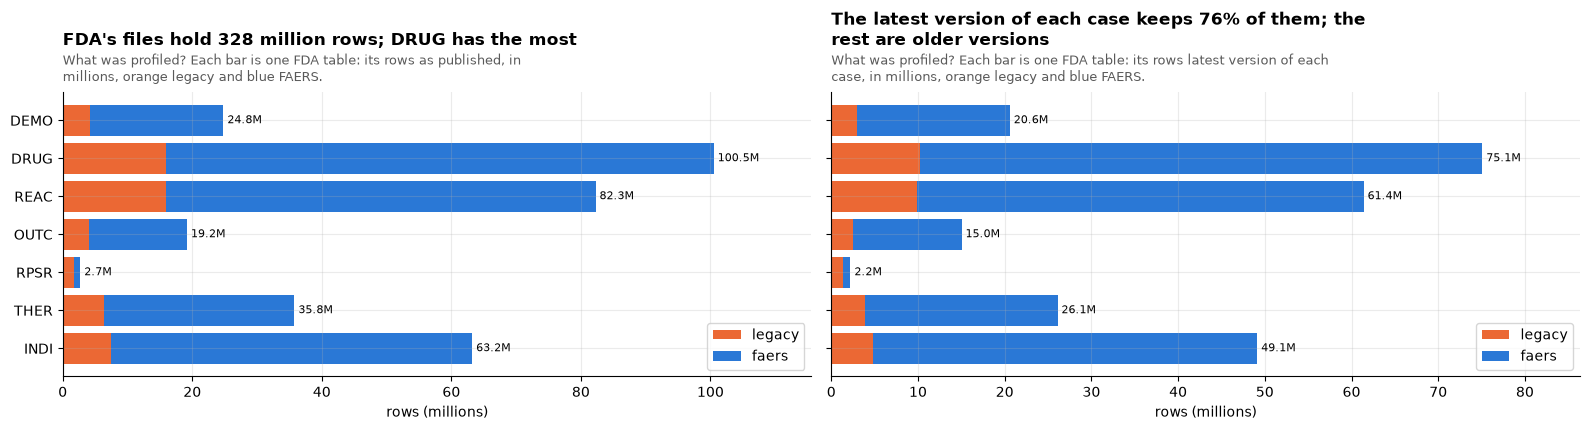

In [2]:
def profile(source, table):
    """Per quarter: rows, and for each field of `table` the rows in each kind of empty. `source` is a
    table or view name. 'spaces only' counts the blanks that hold spaces rather than nothing."""
    cols = [c for t, c in FIELDS if t == table]
    inner = ", ".join(f"{c}, {state_sql(c)} AS s_{c}" for c in cols)
    aggs = ", ".join(
        [f"count(*) FILTER (WHERE s_{c} = '{k}') AS \"{c}|{k}\"" for c in cols for k in KINDS[1:]]
        + [
            f"count(*) FILTER (WHERE s_{c} = 'blank' AND {c} IS NOT NULL) AS \"{c}|spaces only\""
            for c in cols
        ]
    )
    wide = q(
        f"SELECT quarter_T, era_T, count(*) AS rows_T, {aggs} FROM (SELECT quarter_T, era_T, {inner} FROM {source}) GROUP BY ALL"
    )
    long = wide.melt(id_vars=["quarter_T", "era_T", "rows_T"], var_name="ck", value_name="n")
    long[["column", "kind"]] = long.ck.str.split("|", expand=True)
    out = long.pivot_table(
        index=["quarter_T", "era_T", "rows_T", "column"], columns="kind", values="n", aggfunc="sum"
    ).reset_index()
    out.columns.name = None
    out.insert(0, "table", table)
    lay = (
        LAYOUT[LAYOUT.table == table]
        if LAYOUT is not None
        else out.assign(in_file=out.blank < out.rows_T)
    )[["quarter_T", "column", "in_file"]]
    out = out.merge(lay, on=["quarter_T", "column"], how="left")
    out["in_file"] = out.in_file.fillna(True).astype(bool)
    out["not in file"] = np.where(out.in_file, 0, out.blank)
    out["blank"] = np.where(out.in_file, out.blank, 0)
    return out[
        ["table", "column", "quarter_T", "era_T", "rows_T", "in_file"] + KINDS + ["spaces only"]
    ]


LATEST_SOURCE = {"demo": "case_latest_T", **{t: f"{t}_latest_T" for t in TABLES[1:]}}
started = time.time()
for name, sources in [
    ("raw_profile_T", {t: t for t in TABLES}),
    ("latest_profile_T", LATEST_SOURCE),
]:
    if REBUILD or not have(name):
        df = pd.concat([profile(src, t) for t, src in sources.items()], ignore_index=True)
        con.register("df_T", df)
        con.execute(f"CREATE OR REPLACE TABLE w.{name} AS SELECT * FROM df_T")
        con.unregister("df_T")
RAW = q("SELECT * FROM w.raw_profile_T")  # rows as FDA published them, per quarterly file
LATEST = q("SELECT * FROM w.latest_profile_T")  # DEMO: cases; other tables: the rows of those cases
for d in (RAW, LATEST):
    d["in_file"] = d.in_file.astype(bool)
    d["empty"] = d[KINDS].sum(axis=1)
    d["field"] = d.table.str.upper() + " " + d.column


def FULL_DATE(c):
    return f"(regexp_full_match({c}, '[0-9]{{8}}') AND try_strptime({c}, '%Y%m%d') IS NOT NULL)"


STATE_FIELDS = {  # field: the scratch column holding its kind of empty
    "event_dt": "event_dt_s_T",
    "age": "age_s_T",
    "age_cod": "age_cod_s_T",
    "sex": "sex_s_T",
    "wt": "wt_s_T",
    "wt_cod": "wt_cod_s_T",
    "occp_cod": "occp_s_T",
    "mfr_num": "mfr_num_s_T",
    "occr_country": "occr_country_s_T",
    "reporter_country": "reporter_country_s_T",
    "country_T": "country_s_T",
}
if REBUILD or not have("cases_T"):
    con.execute(f"""
    CREATE OR REPLACE TABLE w.ps_T AS   -- the primary suspect drug of each case, and its therapy start date
    SELECT d.era_T, d.primaryid, d.quarter_T,
           bool_and({empty("route", "d.route")}) AS ps_route_empty_T,
           bool_and({empty("dose_amt", "d.dose_amt")}) AS ps_dose_empty_T,
           bool_and({empty("dechal", "d.dechal", quarter="d.quarter_T")}) AS ps_dechal_empty_T,
           bool_or({FULL_DATE("t.start_dt")}) AS ps_start_full_T,
           bool_or({FULL_DATE("t.start_dt")} AND right(t.start_dt, 2) <> '01') AS ps_start_full_not_1st_T,
           bool_or(NOT {empty("start_dt", "t.start_dt")}) AS ps_start_any_T
    FROM drug_latest_T d
    LEFT JOIN ther_latest_T t ON t.era_T = d.era_T AND t.primaryid = d.primaryid AND t.quarter_T = d.quarter_T AND t.dsg_drug_seq = d.drug_seq
    WHERE d.role_cod = 'PS' GROUP BY ALL""")
    con.execute(f"""
    CREATE OR REPLACE TABLE w.indi_T AS
    SELECT era_T, primaryid, quarter_T, bool_or(NOT {empty("indi_pt")}) AS indi_known_T FROM indi_latest_T GROUP BY ALL""")
    states = ", ".join(f"{state_sql(f)} AS {col}" for f, col in STATE_FIELDS.items())
    key_ng = " OR ".join(empty(f) for f in KEY_FIELDS)
    con.execute(f"""
    CREATE OR REPLACE TABLE w.cases_T AS
    WITH c AS (SELECT *, {states}, ({key_ng}) AS key_not_given_T FROM case_latest_T)
    SELECT c.era_T, c.case_key_T, c.primaryid, c.caseid, c.quarter_T, c.init_year_T, c.rept_cod, c.mfr_sndr, c.i_f_code,
           CASE WHEN c.rept_cod = 'DIR' THEN 'Direct reports' WHEN {empty("mfr_sndr", "c.mfr_sndr")} THEN '{NG}'
                ELSE coalesce(m.company, c.mfr_sndr) END AS sender_T,
           m.company IS NOT NULL AS mapped_T,
           c.event_dt, c.age, c.age_cod, c.age_grp, c.sex, c.wt, c.wt_cod, c.occp_cod, c.country_T, c.event_dt_T, c.age_years_T,
           k.dup_key_T, c.probable_duplicate_T, c.dup_kept_T, coalesce(c.dup_rule_T, []) AS dup_rule_T,
           {", ".join(f"c.{col}" for col in STATE_FIELDS.values())}, c.key_not_given_T,
           p.primaryid IS NOT NULL AS has_ps_T, p.ps_route_empty_T, p.ps_dose_empty_T, p.ps_dechal_empty_T,
           coalesce(p.ps_start_full_T, false) AS ps_start_full_T, coalesce(p.ps_start_full_not_1st_T, false) AS ps_start_full_not_1st_T,
           coalesce(p.ps_start_any_T, false) AS ps_start_any_T,
           i.primaryid IS NOT NULL AS has_indi_T, coalesce(i.indi_known_T, false) AS indi_known_T
    FROM c
    JOIN case_dup_T k USING (era_T, case_key_T)
    LEFT JOIN company_T m ON m.fda_value = c.mfr_sndr AND c.rept_cod <> 'DIR' AND c.era_T = 'faers'
    LEFT JOIN w.ps_T p ON p.era_T = c.era_T AND p.primaryid = c.primaryid AND p.quarter_T = c.quarter_T
    LEFT JOIN w.indi_T i ON i.era_T = c.era_T AND i.primaryid = c.primaryid AND i.quarter_T = c.quarter_T""")
N_CASES = one("SELECT count(*) FROM w.cases_T")[0]
check(
    "cases in the scratch table = cases in case_latest_T",
    N_CASES,
    one("SELECT count(*) FROM case_latest_T")[0],
)
check(
    "DEMO cases profiled = cases in case_latest_T",
    int(LATEST[LATEST.column == "fda_dt"].rows_T.sum()),
    N_CASES,
)
check(
    "DEMO rows profiled = rows in FDA's DEMO files",
    int(RAW[RAW.column == "fda_dt"].rows_T.sum()),
    one("SELECT count(*) FROM demo")[0],
)
print(f"working tables ready in {time.time() - started:.0f}s")


# what was profiled: rows per table and era, both grains
def per(d):
    return (
        d.drop_duplicates(["table", "quarter_T", "era_T"])
        .groupby(["table", "era_T"])
        .rows_T.sum()
        .unstack()
    )


prof = pd.concat(
    {"as published": per(RAW), "latest version of each case": per(LATEST)}, axis=1
).reindex(list(TABLES))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), sharey=True)
tot_pub, tot_lat = (
    np.nansum(prof[g].values) for g in ["as published", "latest version of each case"]
)
KEPT = 100 * tot_lat / tot_pub
CLAIM = {
    "as published": f"FDA's files hold {tot_pub / 1e6:.0f} million rows; DRUG has the most",
    "latest version of each case": f"The latest version of each case keeps {KEPT:.0f}% of them; the rest are older versions",
}
for ax, grain in zip(axes, ["as published", "latest version of each case"], strict=True):
    left = np.zeros(len(prof))
    for era in ["legacy", "faers"]:
        v = prof[(grain, era)].values / 1e6
        ax.barh([t.upper() for t in prof.index], v, left=left, color=ERA[era], label=era)
        left += v
    for y, tot in enumerate(left):
        ax.text(tot, y, f" {tot:,.1f}M", va="center", fontsize=8)
    titled(
        ax,
        CLAIM[grain],
        "What was profiled?",
        f"Each bar is one FDA table: its rows {grain}, in millions, orange legacy and blue FAERS.",
        width=80,
    )
    ax.set_xlim(0, left.max() * 1.15)
    ax.set_xlabel("rows (millions)")
    ax.legend(loc="lower right")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

### Does keeping only the latest version lose what an earlier one gave?

A case is kept as its latest version, whole: never merged with an earlier version, and no field filled from one (rule `latest-version`). The chart below counts what that costs: cases whose latest version does not give a field that an earlier version of the same case did.

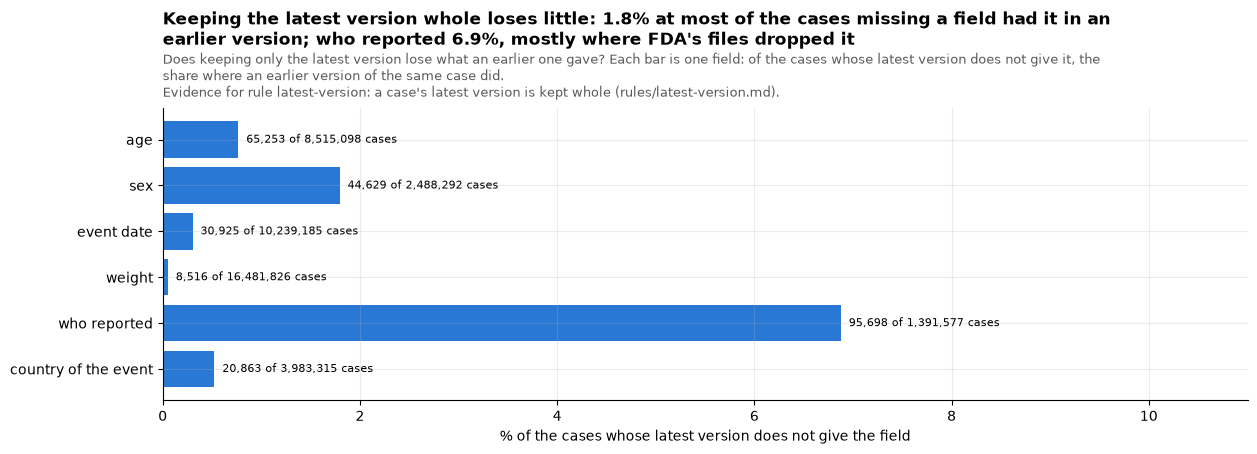

checked: cases whose latest version gives no age = 8,515,098
Who reported, given in an earlier version but not in the latest: 95,698 cases, 61,020 of them (64%) with a latest version from 2025Q3 on, when FDA's files stopped saying who reported on company reports (section 4).


,not given,earlier gave it,%
age,8515098,65253,0.766321
sex,2488292,44629,1.793560
event date,10239185,30925,0.302026
weight,16481826,8516,0.051669
who reported,1391577,95698,6.876946
country of the event,3983315,20863,0.523760


In [3]:
# A case is kept as its latest version, whole; never filled from an earlier one.
LOST = {
    "age": "age",
    "sex": "sex",
    "event date": "event_dt",
    "weight": "wt",
    "who reported": "occp_cod",
    "country of the event": "occr_country",
}
earlier = ", ".join(f"bool_or(NOT {empty(c, 'd.' + c)}) AS {c}_T" for c in LOST.values())
OCC_FROM = next(
    n["from"] for n in rulebook.value("explorer-field-notes", "notes") if n["field"] == "occp_cod"
)
counts = ", ".join(
    [
        f'count(*) FILTER (WHERE {empty(c, "c." + c)}) AS "{c}|not given", '
        f'count(*) FILTER (WHERE {empty(c, "c." + c)} AND o.{c}_T) AS "{c}|earlier gave it"'
        for c in LOST.values()
    ]
    + [
        f"count(*) FILTER (WHERE {empty('occp_cod', 'c.occp_cod')} AND o.occp_cod_T AND c.quarter_T >= '{OCC_FROM}') AS occp_recent_T"
    ]
)
lost = q(f"""
WITH older AS (   -- every version of a kept case but its latest
  SELECT d.era_T, d.case_key_T, {earlier}
  FROM demo_T d SEMI JOIN case_latest_T c USING (era_T, case_key_T)
  ANTI JOIN case_latest_T l USING (era_T, primaryid, quarter_T)
  GROUP BY ALL)
SELECT {counts} FROM case_latest_T c LEFT JOIN older o USING (era_T, case_key_T)""").iloc[0]
OCC_RECENT = int(lost["occp_recent_T"])
lost = pd.DataFrame(
    {
        "not given": [int(lost[f"{c}|not given"]) for c in LOST.values()],
        "earlier gave it": [int(lost[f"{c}|earlier gave it"]) for c in LOST.values()],
    },
    index=list(LOST),
)
lost["%"] = 100 * lost["earlier gave it"] / lost["not given"]
fig, ax = plt.subplots(figsize=(14, 3.8))
bars = ax.barh(lost.index, lost["%"], color=SERIES[0])
for b, (_, r) in zip(bars, lost.iterrows(), strict=True):
    ax.text(
        b.get_width(),
        b.get_y() + b.get_height() / 2,
        f"  {int(r['earlier gave it']):,} of {int(r['not given']):,} cases",
        va="center",
        fontsize=8,
    )
ax.invert_yaxis()
ax.set_xlim(0, max(2, lost["%"].max() * 1.6))
ax.set_xlabel("% of the cases whose latest version does not give the field")
titled(
    ax,
    f"Keeping the latest version whole loses little: {lost.drop('who reported')['%'].max():.1f}% at most of the cases missing a field "
    f"had it in an earlier version; who reported {lost.loc['who reported', '%']:.1f}%, mostly where FDA's files dropped it",
    "Does keeping only the latest version lose what an earlier one gave?",
    "Each bar is one field: of the cases whose latest version does not give it, the share where an earlier version of the same case did.",
    backs="Evidence for rule latest-version: a case's latest version is kept whole (rules/latest-version.md).",
    width=150,
)
plt.show()
check(
    "cases whose latest version gives no age",
    int(lost.loc["age", "not given"]),
    int(LATEST[LATEST.field == "DEMO age"]["empty"].sum()),
)
print(
    f"Who reported, given in an earlier version but not in the latest: {int(lost.loc['who reported', 'earlier gave it']):,} cases, "
    f"{OCC_RECENT:,} of them ({100 * OCC_RECENT / lost.loc['who reported', 'earlier gave it']:.0f}%) with a latest version from {OCC_FROM.upper()} on, "
    "when FDA's files stopped saying who reported on company reports (section 4)."
)
lost

**What the working tables show**

- **What was profiled.** *Shows:* the rows of FDA's seven tables as published, and the rows of the latest version of each case. *Point:* the latest versions keep about three quarters of FDA's rows; the rest are older versions of the same cases and the cases FDA deleted. *So what:* sections 2, 4 and 5 count what a reader sees, section 3 what FDA published.
- **What keeping the latest version loses.** *Shows:* for six fields, the cases whose latest version does not give the field although an earlier version did. *Point:* age 65,253 of the 8,515,098 cases with no age (0.8%), sex 32,046, event date 30,925, weight 8,516, country 20,863: at most 1.2% of a field. Who reported is the exception, 95,698 cases (6.9%), and 64% of them have a latest version from 2025Q3 on, when FDA's files stopped giving it on company reports (section 4). *So what:* keeping the latest version whole, never filled from an earlier one, costs little, and a reader never sees a case that mixes two versions; the loss in who reported comes from FDA's files, not from the rule.

## 1. What empty looks like

FDA's files are text, one value per field. A field can be empty in four ways, and this notebook counts each one apart, though every one of them reads the same on screen, **Not given** (rule `not-given`):

1. **Not in file.** The column is not in that quarter's file at all. FDA changed its layouts in 2004Q1 to 2005Q3, at the AERS to FAERS change (2012Q4) and in 2014Q3. Read here from the header line of every one of FDA's files.
2. **Blank.** The column is there and the value is empty, or only spaces.
3. **Says unknown.** The value is there and says it is unknown: a code that means unknown (sex `UNK` or `NS`, country `COUNTRY NOT SPECIFIED`, dechallenge `U`), a MedDRA term that means unknown (indication `Product used for unknown indication`), a drug name that names no drug, or free text made only of words like `UNK`, `UNKNOWN`, `ASKU`, `N/A`, `NOT REPORTED`.
4. **Filler.** A value the sender never meant: a number that cannot be real (a weight or dose of zero, a run of three or more 9s such as `999`), rechallenge `D` in FDA's files from 2012Q4 to 2015Q3 (section 3), and whether the reporter also told the company (`to_mfr`) on a company report (section 3).

Kept as real values, on purpose: dechallenge and rechallenge `D` outside those quarters (does not apply), an age of 0 (a newborn), and the country codes `NI` (Nicaragua) and `NA` (Namibia). Every list is read from `rules/not-given.md`, one checked list per field.

### Fields that are not in every file

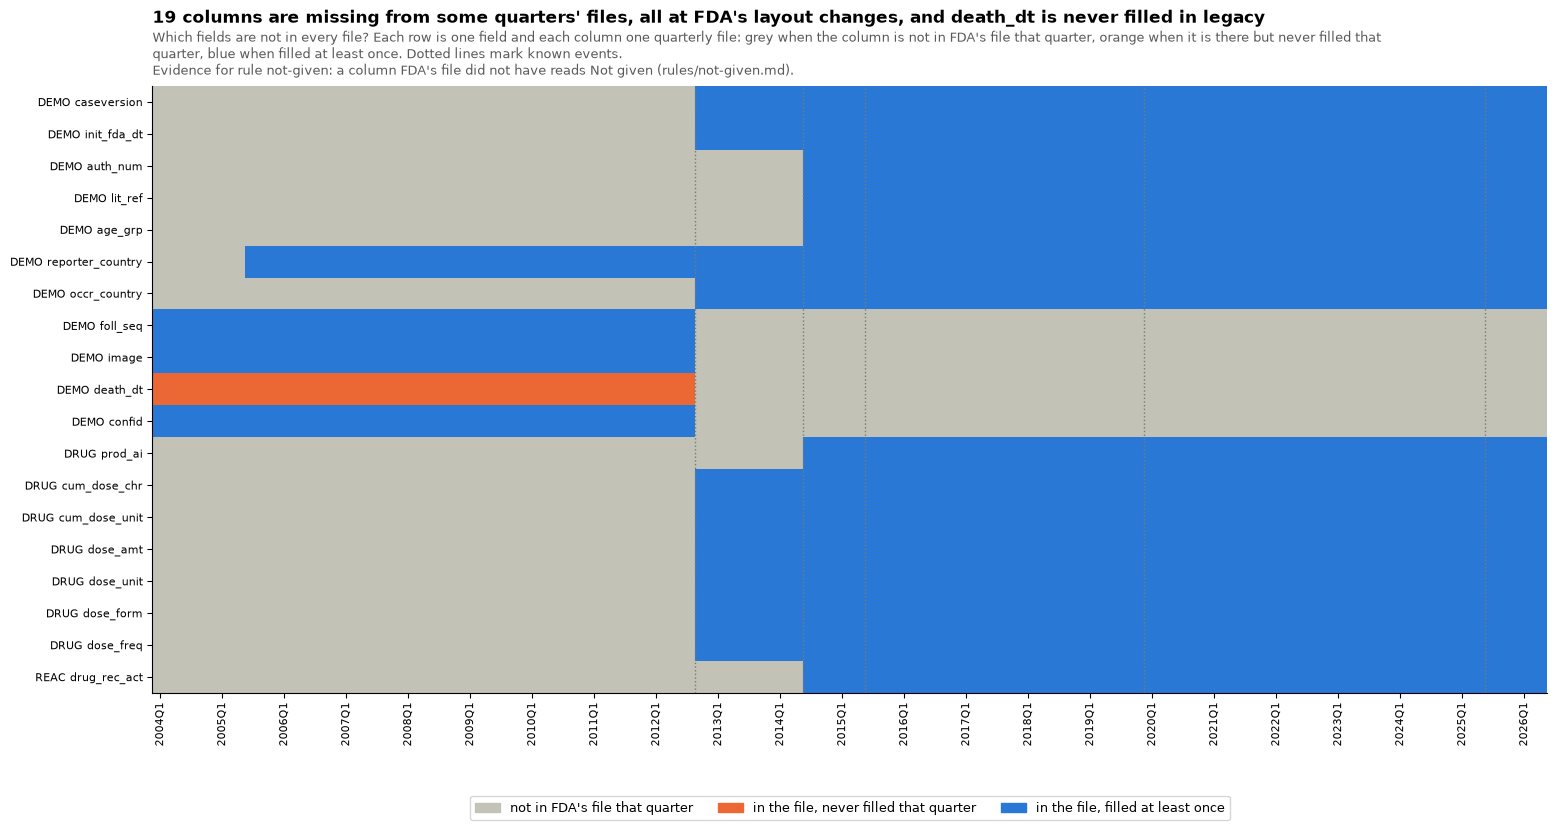

FDA's table files read: 630; lines the loader could not read: 0; lines longer than their header: 4
  2011Q2 DRUG line 322,967: 2 records run together on one line, split back
  2011Q3 DRUG line 247,896: 2 records run together on one line, split back
  2011Q4 DRUG line 446,738: 2 records run together on one line, split back
  2012Q1 DEMO line 105,917: one value more than the header, 'JAPAN', set aside and kept in the manifest
In the file but never filled, in at least one quarter: DEMO death_dt (35 quarters, 2004q1 to 2012q3)


first quarter missing last quarter missing
table column                                                     
demo  age_grp                         2004q1               2014q2
      auth_num                        2004q1               2014q2
      caseversion                     2004q1               2012q3
      confid                          2012q4               2026q2
      death_dt                        2012q4               2026q2
      foll_seq                        2012q4               2026q2
      image                           2012q4               2026q2
      init_fda_dt                     2004q1               2012q3
      lit_ref                         2004q1               2014q2
      occr_country                    2004q1               2012q3
      reporter_country                2004q1               2005q2
drug  cum_dose_chr                    2004q1               2012q3
      cum_dose_unit                   2004q1               2012q3
      dose_amt                        2004q1               2012q3
      dose_form                       2004q1               2012q3
      dose_freq                       2004q1               2012q3
      dose_unit                       2004q1               2012q3
      prod_ai                         2004q1               2014q2
reac  drug_rec_act                    2004q1               2014q2

In [4]:
# Each quarter's file: is the column there, and if it is, did FDA fill it at all that quarter?
cell = RAW.assign(state=np.select([~RAW.in_file, RAW["empty"] >= RAW.rows_T], [0, 1], 2))
part = cell.groupby("field").state.agg(lambda s: (s < 2).any())
shown = part[part].index.tolist()  # fields that are missing or never filled in at least one quarter
order = [f"{t.upper()} {c}" for t, c in FIELDS if f"{t.upper()} {c}" in shown]
mat = (
    cell[cell.field.isin(shown)]
    .pivot_table(index="field", columns="quarter_T", values="state", aggfunc="first")
    .reindex(index=order, columns=QS)
)
fig, ax = plt.subplots(figsize=(18, 0.32 * len(order) + 1.8))
cmap = mpl.colors.ListedColormap([KIND_COLOUR["not in file"], SERIES[1], SERIES[0]])
ax.imshow(mat.values, aspect="auto", cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
ax.grid(False)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=8)
quarter_ticks(ax, QS)
event_lines(ax, QS)
handles = [
    mpl.patches.Patch(color=c, label=label)
    for c, label in zip(
        cmap.colors,
        [
            "not in FDA's file that quarter",
            "in the file, never filled that quarter",
            "in the file, filled at least once",
        ],
        strict=True,
    )
]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=9)
titled(
    ax,
    f"{int((mat == 0).any(axis=1).sum())} columns are missing from some quarters' files, all at FDA's layout changes, "
    "and death_dt is never filled in legacy",
    "Which fields are not in every file?",
    "Each row is one field and each column one quarterly file: grey when the column is not in FDA's file that quarter, orange when "
    "it is there but never filled that quarter, blue when filled at least once. Dotted lines mark known events.",
    backs="Evidence for rule not-given: a column FDA's file did not have reads Not given (rules/not-given.md).",
    width=195,
)
plt.show()
# Is a missing column FDA's layout, or a line we failed to read? The release's manifest records every
# line the loader could not read, and every line longer than its file's header.
files = [i for i in MANIFEST["inputs"] if i.get("table") in TABLES]
rejected = sum(i.get("rejected_lines", 0) for i in MANIFEST["inputs"])
overlong = [(i["quarter"], i["table"], o) for i in files for o in i.get("overlong_lines", [])]
print(
    f"FDA's table files read: {len(files):,}; lines the loader could not read: {rejected:,}; "
    f"lines longer than their header: {len(overlong)}"
)
for qq, t, o in overlong:
    how = (
        f"one value more than the header, {o['dropped'].rstrip('$')!r}, set aside and kept in the manifest"
        if o.get("dropped")
        else f"{o['records']} records run together on one line, split back"
    )
    print(f"  {qq.upper()} {t.upper()} line {o['line']:,}: {how}")
never = cell[(cell.state == 1)].groupby("field").quarter_T.agg(["min", "max", "count"])
print(
    "In the file but never filled, in at least one quarter:",
    "; ".join(
        f"{f} ({r['count']} quarters, {r['min']} to {r['max']})" for f, r in never.iterrows()
    ),
)
(
    LAYOUT[~LAYOUT.in_file]
    .groupby(["table", "column"])
    .quarter_T.agg(["min", "max"])
    .rename(columns={"min": "first quarter missing", "max": "last quarter missing"})
    if LAYOUT is not None
    else None
)

**Missing columns are FDA's layout, not a reading error.** Each quarter's columns are read from the header line of FDA's own file, so a column is "not in file" only when FDA's header does not name it. The loader reads every line: the manifest above records no line it could not read, and only four lines in all of FDA's files that are longer than their header. Three are 2011 DRUG lines where two records ran together, split back into two; one is a 2012Q1 DEMO line with one value too many (`JAPAN`), set aside and kept in the manifest. None of them touches a column that is missing.

### Values that say unknown, and fillers

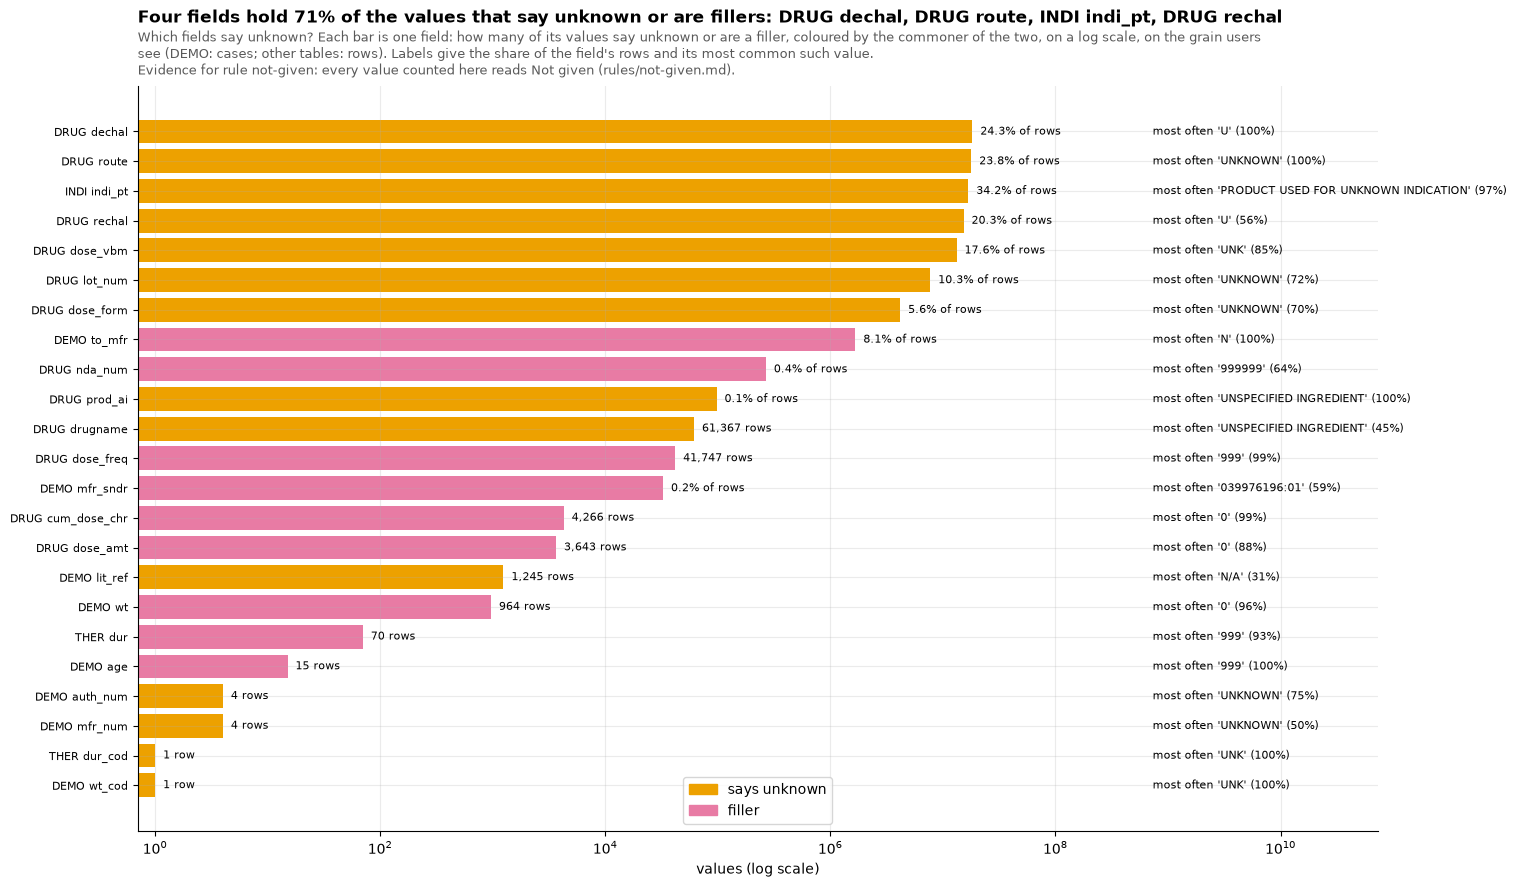

Values that say unknown: 86,711,404. Fillers: 8,708,053. Values that hold only spaces, in every field of all seven files as published: 227 (the loader reads an empty value as blank).
checked: route that says UNKNOWN, rows of latest cases = 17,842,952
checked: cases with sex UNK or NS counted among the unknown words = 0
checked: rechallenge D read as a filler, 2012Q4 to 2015Q3, rows of latest cases = 6,699,103
checked: to_mfr filled on a company report, cases = 1,666,543


checked: values the rule reads Not given in DRUG rechal = blank + says unknown + filler = 73,066,991


In [5]:
# Every value that says unknown or is a filler, on the grain users see: cases (DEMO) and the rows of those cases.
PH_FIELDS = [(t, c) for t, c in FIELDS if c in RULE]
cat = q(
    " UNION ALL ".join(
        f"SELECT '{t.upper()} {c}' AS field, s AS kind, v AS value, count(*) AS n "
        f"FROM (SELECT {state_sql(c)} AS s, {V(c)} AS v FROM {LATEST_SOURCE[t]}) WHERE s IN ('says unknown', 'filler') GROUP BY ALL"
        for t, c in PH_FIELDS
    )
)
tot = cat.groupby("field").n.sum().sort_values()
rows_of = LATEST.groupby("field").rows_T.sum()
topv = cat.sort_values("n", ascending=False).groupby("field").head(1).set_index("field")
fig, ax = plt.subplots(figsize=(16, 0.36 * len(tot) + 1.4))
colours = [KIND_COLOUR[topv.kind[f]] for f in tot.index]
ax.barh(tot.index, tot.values, color=colours)
ax.set_xscale("log")
for y, (f, n) in enumerate(tot.items()):
    pct = 100 * n / rows_of[f]
    ax.text(
        n,
        y,
        f"  {pct:.1f}% of rows" if pct >= 0.1 else f"  {n:,} row{'s' if n != 1 else ''}",
        va="center",
        fontsize=8,
    )
    ax.text(
        tot.max() * 40,
        y,
        f"most often {topv.value[f][:45]!r} ({100 * topv.n[f] / n:.0f}%)",
        va="center",
        fontsize=8,
    )
ax.set_xlim(0.7, tot.max() * 4000)
ax.set_xlabel("values (log scale)")
ax.tick_params(axis="y", labelsize=8)
ax.legend(
    handles=[mpl.patches.Patch(color=KIND_COLOUR[k], label=k) for k in ["says unknown", "filler"]],
    loc="lower center",
)
top4 = tot.index[::-1][:4]
titled(
    ax,
    f"Four fields hold {100 * tot[top4].sum() / tot.sum():.0f}% of the values that say unknown or are fillers: {', '.join(top4)}",
    "Which fields say unknown?",
    "Each bar is one field: how many of its values say unknown or are a filler, coloured by the commoner of the two, on a log scale, "
    "on the grain users see (DEMO: cases; other tables: rows). Labels give the share of the field's rows and its most common such value.",
    backs="Evidence for rule not-given: every value counted here reads Not given (rules/not-given.md).",
    width=175,
)
plt.show()
UNK_TOTAL, FILLER_TOTAL = (int(cat[cat.kind == k].n.sum()) for k in ["says unknown", "filler"])
print(
    f"Values that say unknown: {UNK_TOTAL:,}. Fillers: {FILLER_TOTAL:,}. Values that hold only spaces, in every field of "
    f"all seven files as published: {int(RAW['spaces only'].sum()):,} (the loader reads an empty value as blank)."
)
check(
    "route that says UNKNOWN, rows of latest cases",
    int(cat[(cat.field == "DRUG route") & (cat.value == "UNKNOWN")].n.sum()),
    one("SELECT count(*) FROM drug_latest_T WHERE upper(trim(route)) = 'UNKNOWN'")[0],
)
# sex has its own rule (sex-codes): UNK and NS leave sex_T empty and are not counted as unknown words here
check(
    "cases with sex UNK or NS counted among the unknown words",
    int(cat[cat.field == "DEMO sex"].n.sum()),
    0,
)
W = RULE["rechal"]["codes_in_quarters"]
check(
    f"rechallenge D read as a filler, {W['from'].upper()} to {W['to'].upper()}, rows of latest cases",
    int(cat[(cat.field == "DRUG rechal") & (cat.kind == "filler")].n.sum()),
    one(
        f"SELECT count(*) FROM drug_latest_T WHERE upper(trim(rechal)) = 'D' AND quarter_T BETWEEN '{W['from']}' AND '{W['to']}'"
    )[0],
)
check(
    "to_mfr filled on a company report, cases",
    int(cat[(cat.field == "DEMO to_mfr") & (cat.kind == "filler")].n.sum()),
    one(
        "SELECT count(*) FROM case_latest_T WHERE coalesce(rept_cod, '') <> 'DIR' AND trim(to_mfr) <> ''"
    )[0],
)
check(
    "values the rule reads Not given in DRUG rechal = blank + says unknown + filler",
    int(LATEST[LATEST.field == "DRUG rechal"]["empty"].sum()),
    one(f"SELECT count(*) FROM drug_latest_T WHERE {empty('rechal')}")[0],
)

**What reads Not given, besides a blank.** The rule's lists find 87.5 million values that say unknown and 8.7 million fillers, 71% of them in four fields: dechallenge `U`, route `UNKNOWN`, the "unknown indication" terms (real MedDRA terms that say no indication was given) and rechallenge, whose `D` in 2012Q4 to 2015Q3 is a filler (section 3). On cases: `to_mfr` filled on a company report (a filler, section 3), reporter country `COUNTRY NOT SPECIFIED`, sex `NS` or `UNK`, a sender called `Unknown Manufacturer`. Filler numbers are rare: NDA number `999999` or `000000`, dose frequency `999`, a weight of `0`.

### Dates: zero-filled, partial and padded

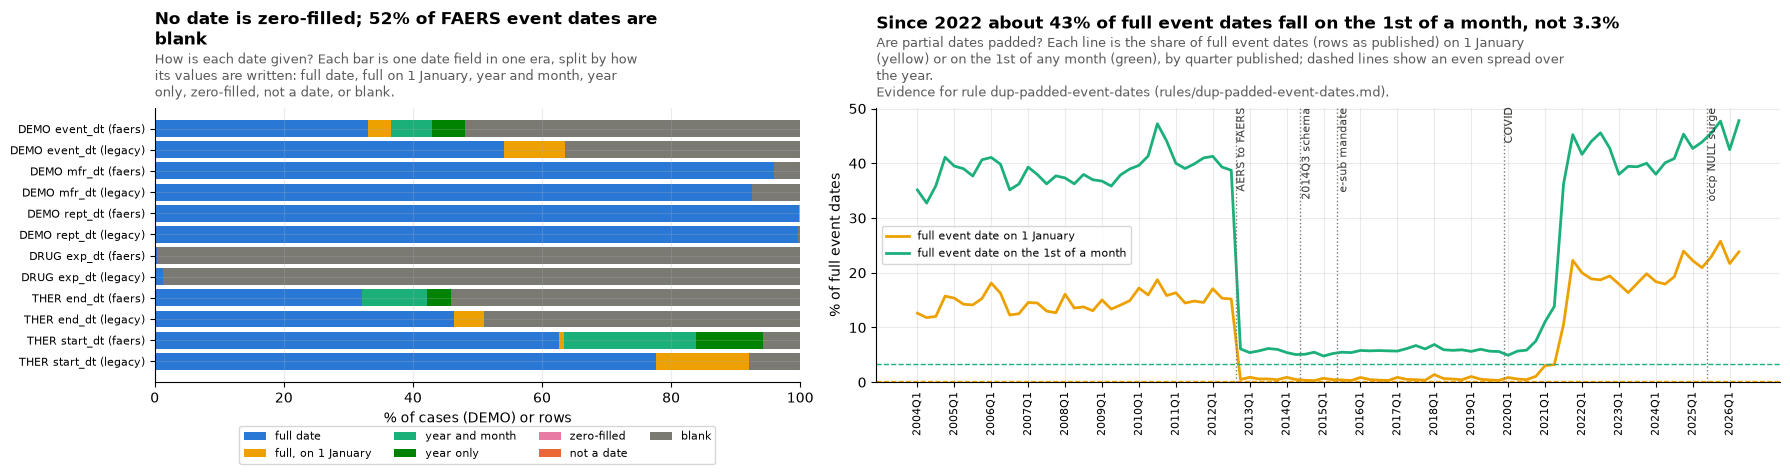

Zero-filled dates (all zeros, month 00 or day 00) in these six fields: 0.


In [6]:
# Dates: no zero-filled dates exist; the placeholder hiding in dates is the padded day or month.
DATE_FIELDS = [
    ("demo", "event_dt"),
    ("demo", "mfr_dt"),
    ("demo", "rept_dt"),
    ("ther", "start_dt"),
    ("ther", "end_dt"),
    ("drug", "exp_dt"),
]
# a padded date: the month and day the duplicate step reads as padding (rules/dup-padded-event-dates.md)
PADDED = rulebook.value("dup-padded-event-dates", "padded_month_day")


def SHAPE(c):
    return f"""CASE WHEN {c} IS NULL THEN 'blank' WHEN NOT regexp_full_match({c}, '[0-9]+') OR length({c}) NOT IN (4, 6, 8) THEN 'not a date'
    WHEN regexp_full_match({c}, '0+') OR (length({c}) >= 6 AND substr({c}, 5, 2) = '00') OR (length({c}) = 8 AND substr({c}, 7, 2) = '00') THEN 'zero-filled'
    WHEN length({c}) = 4 THEN 'year only' WHEN length({c}) = 6 THEN 'year and month'
    WHEN try_strptime({c}, '%Y%m%d') IS NULL THEN 'not a date' WHEN right({c}, {len(PADDED)}) = '{PADDED}' THEN 'full, on 1 January' ELSE 'full date' END"""


shapes = q(
    " UNION ALL ".join(
        f"SELECT '{t.upper()} {c}' AS field, era_T, {SHAPE(c)} AS shape, count(*) AS n FROM {LATEST_SOURCE[t]} GROUP BY ALL"
        for t, c in DATE_FIELDS
    )
)
SH = [
    "full date",
    "full, on 1 January",
    "year and month",
    "year only",
    "zero-filled",
    "not a date",
    "blank",
]
SH_COL = [SERIES[0], SERIES[3], SERIES[2], SERIES[5], SERIES[4], SERIES[1], KIND_COLOUR["blank"]]
jan = (
    q(f"""SELECT quarter_T, era_T, 100 * avg((right(event_dt, {len(PADDED)}) = '{PADDED}')::INT) AS jan1, 100 * avg((right(event_dt, 2) = '01')::INT) AS first
           FROM demo WHERE regexp_full_match(event_dt, '[0-9]{{8}}') GROUP BY ALL""")
    .set_index("quarter_T")
    .reindex(QS)
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1.4]})
p = (
    shapes.pivot_table(index=["field", "era_T"], columns="shape", values="n", aggfunc="sum")
    .reindex(columns=SH)
    .fillna(0)
)
p = 100 * p.div(p.sum(axis=1), axis=0)
labels = [f"{f} ({e})" for f, e in p.index]
left = np.zeros(len(p))
for s, col in zip(SH, SH_COL, strict=True):
    a1.barh(labels, p[s], left=left, color=col, label=s)
    left += p[s].values
a1.invert_yaxis()
a1.set_xlim(0, 100)
a1.set_xlabel("% of cases (DEMO) or rows")
a1.tick_params(axis="y", labelsize=8)
a1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, fontsize=8)
titled(
    a1,
    f"No date is zero-filled; {p.loc[('DEMO event_dt', 'faers'), 'blank']:.0f}% of FAERS event dates are blank",
    "How is each date given?",
    "Each bar is one date field in one era, split by how its values are written: full date, full on 1 January, year and month, "
    "year only, zero-filled, not a date, or blank.",
    width=76,
)
a2.plot(range(len(QS)), jan.jan1, color=SERIES[3], label="full event date on 1 January")
a2.plot(
    range(len(QS)), jan["first"], color=SERIES[2], label="full event date on the 1st of a month"
)
a2.axhline(100 / 365.25, color=SERIES[3], lw=1, ls="--")
a2.axhline(100 * 12 / 365.25, color=SERIES[2], lw=1, ls="--")
a2.set_ylabel("% of full event dates")
quarter_ticks(a2, QS)
a2.set_ylim(0, None)
mark_quarters(a2, QS)
a2.legend(loc="center left", fontsize=8)
titled(
    a2,
    f"Since 2022 about {jan.loc['2022q1':, 'first'].mean():.0f}% of full event dates fall on the 1st of a month, not {100 * 12 / 365.25:.1f}%",
    "Are partial dates padded?",
    "Each line is the share of full event dates (rows as published) on 1 January (yellow) or on the 1st of any month (green), by "
    "quarter published; dashed lines show an even spread over the year.",
    backs="Evidence for rule dup-padded-event-dates (rules/dup-padded-event-dates.md).",
    width=107,
)
plt.tight_layout()
plt.show()
zero = int(shapes.loc[shapes["shape"] == "zero-filled", "n"].sum())
print(f"Zero-filled dates (all zeros, month 00 or day 00) in these six fields: {zero:,}.")

**What section 1 shows**

- **Fields that are not in every file.** *Shows:* for each field and quarter, whether FDA's file has the column and fills it. *Point:* 19 columns are missing from some quarters, every one at a layout change, and `death_dt` is in every legacy file but never filled; the loader rejected no line. *So what:* a missing column reads Not given like any other empty value, and the methods page says which quarters lacked it.
- **Values that say unknown, and fillers.** *Shows:* per field, the values the rule reads Not given although they are not blank. *Point:* 87.5 million values say unknown and 8.7 million are fillers, 71% of them in dechallenge, route, indication and rechallenge. *So what:* counting only blanks as empty would leave tens of millions of unknowns in filters and charts as if they were answers.
- **How each date is given.** *Shows:* each date field split by how it is written. *Point:* no date is zero-filled; 52% of FAERS event dates are blank, and a full date is not always a real day. *So what:* the date rules must read partial and padded dates, not zeros.
- **Padded dates.** *Shows:* the share of full event dates on 1 January and on the 1st of a month, by quarter. *Point:* since 2022 about 43% of full event dates fall on the 1st, thirteen times an even spread: a date known only to the month or year is written as the 1st. *So what:* a padded date never joins two cases on its own, and time to onset measured from one is not a real interval (section 5).

## 2. Which fields are empty

Every field of the seven tables, each era on its own. DEMO fields are counted on **cases**; the fields of the other six tables on **rows** (the rows that belong to those cases). The bar splits the four kinds of empty, which all read Not given.

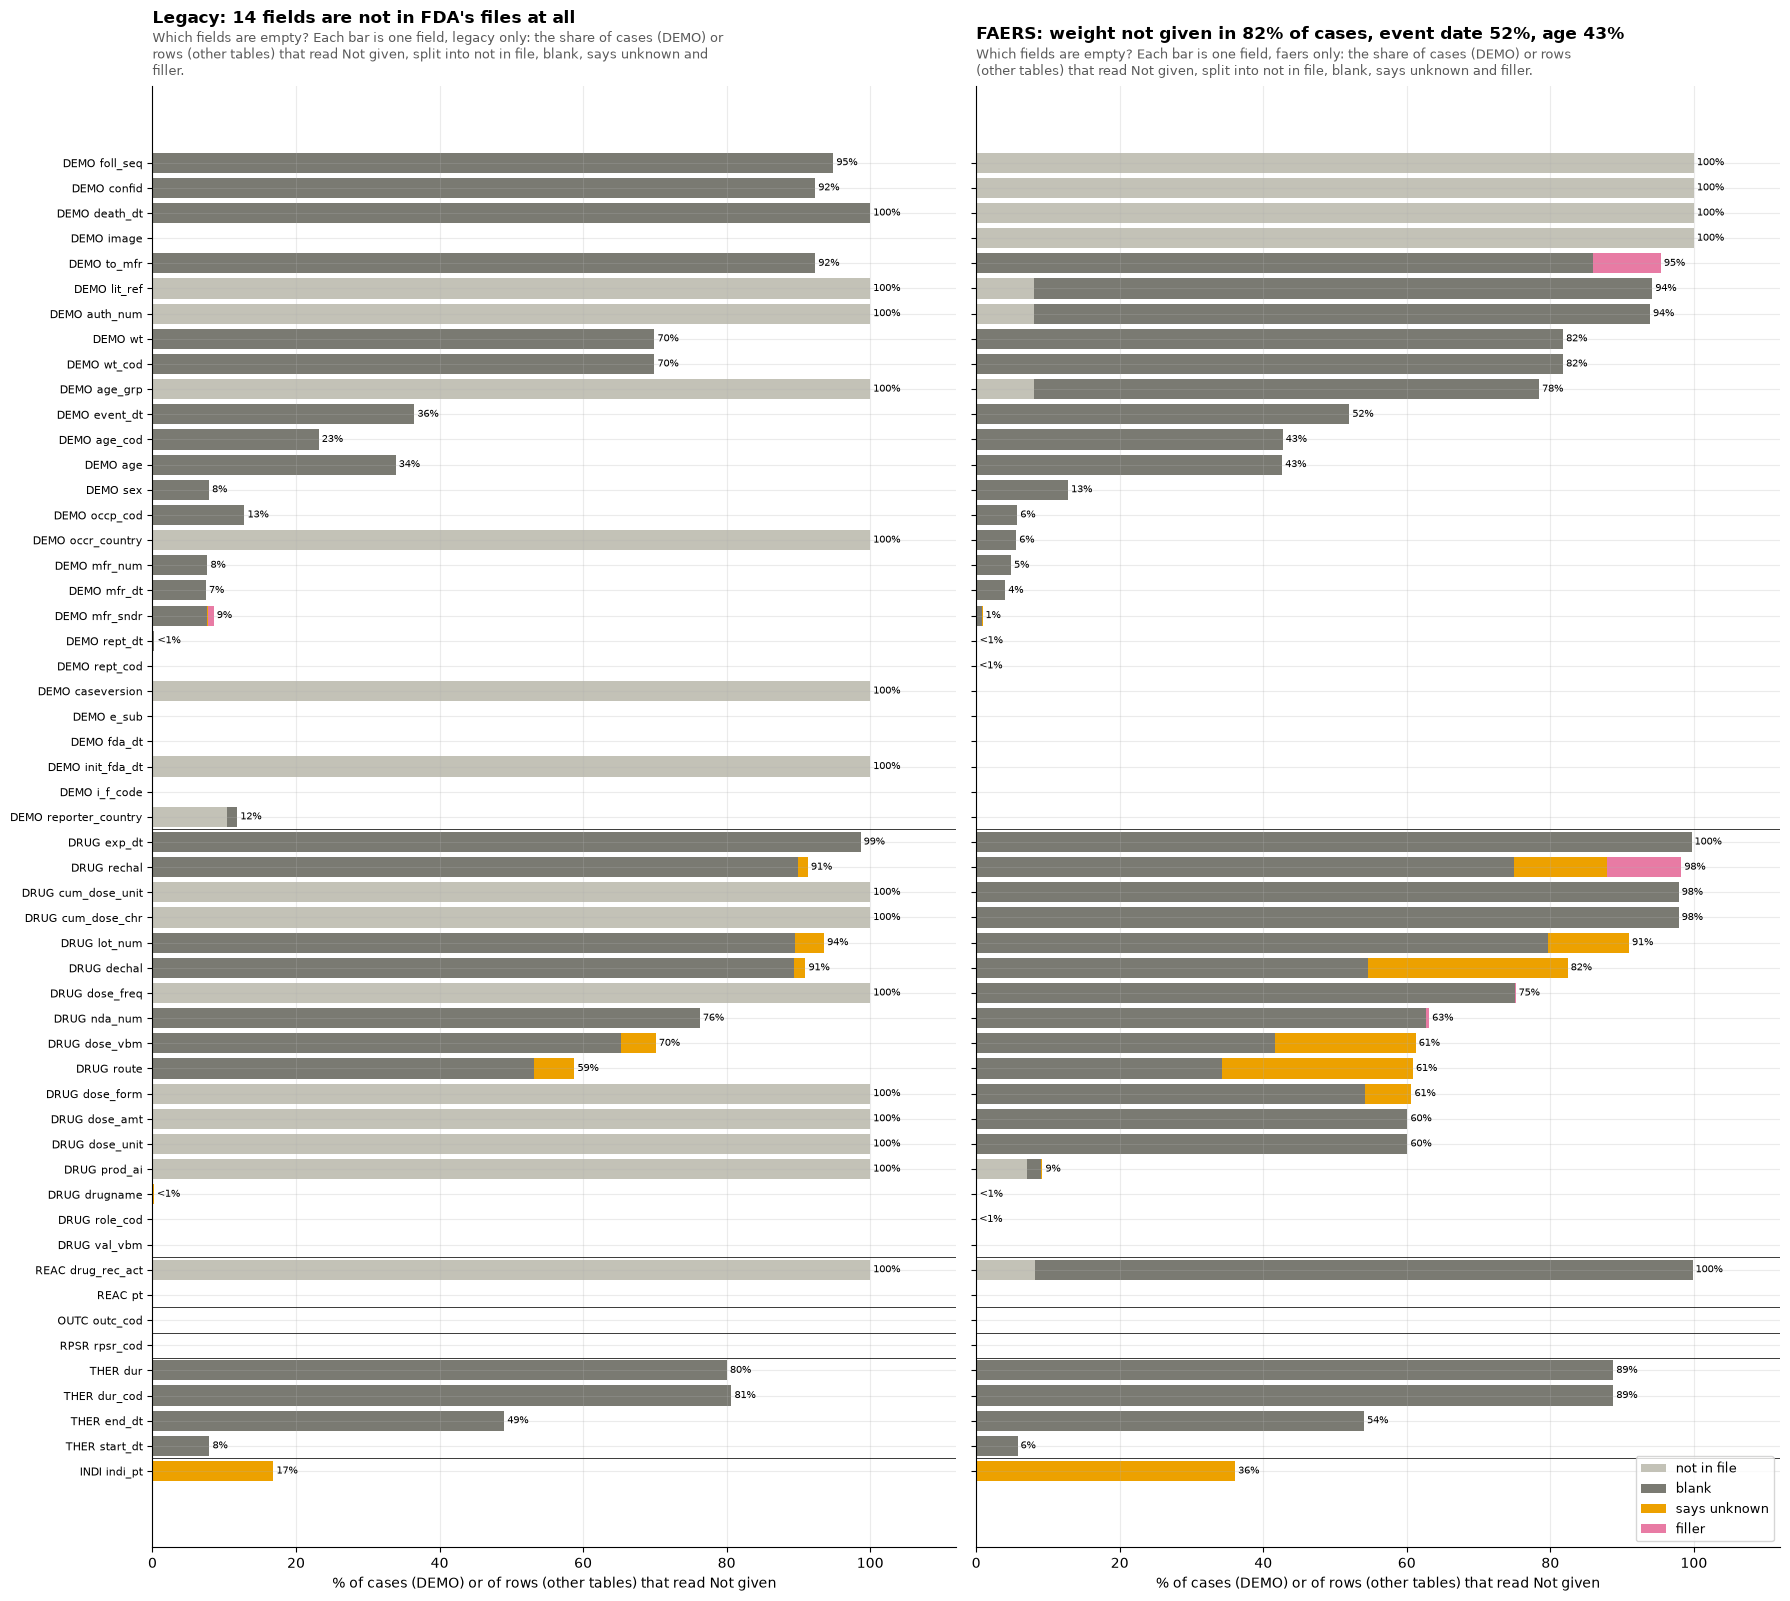

checked: FAERS cases with event date blank = 9,143,310


checked: FAERS drug rows of latest cases with route blank or saying unknown = 39,489,510


era_T,"% Not given, faers","% Not given, legacy"
field,,
DEMO wt,81.8,69.9
DEMO event_dt,52.0,36.5
DEMO age,42.6,33.9
DEMO sex,12.8,7.9
DEMO occp_cod,5.7,12.8
DRUG route,60.9,58.8
DRUG dose_amt,60.1,100.0


In [7]:
# Every field, both eras. DEMO fields are counted on cases (the latest version of each case); the fields of the other
# six tables on their rows that belong to those cases (one DRUG row per drug, one REAC row per reaction, and so on).
by = LATEST.groupby(["table", "column", "field", "era_T"])[["rows_T"] + KINDS].sum().reset_index()
for k in KINDS:
    by[k] = 100 * by[k] / by.rows_T
by["any"] = by[KINDS].sum(axis=1)
order = []
for t in TABLES:  # within each table, the emptiest FAERS field first
    order += (
        by[(by.table == t) & (by.era_T == "faers")]
        .sort_values("any", ascending=False)
        .field.tolist()
    )
fig, axes = plt.subplots(1, 2, figsize=(18, 0.27 * len(order) + 1.8), sharey=True)
for ax, era in zip(axes, ["legacy", "faers"], strict=True):
    d = by[by.era_T == era].set_index("field").reindex(order)
    left = np.zeros(len(d))
    for k in KINDS:
        ax.barh(range(len(d)), d[k], left=left, color=KIND_COLOUR[k], label=k, height=0.8)
        left += d[k].fillna(0).values
    for y, v in enumerate(left):
        ax.text(
            v, y, f" {v:.0f}%" if v >= 0.5 else (" <1%" if v > 0 else ""), va="center", fontsize=7
        )
    ax.set_xlim(0, 112)
    ax.set_xlabel(f"% of cases (DEMO) or of rows (other tables) that read {NG}")
    claim = (
        f"Legacy: {int((d['not in file'] > 99.9).sum())} fields are not in FDA's files at all"
        if era == "legacy"
        else f"FAERS: weight not given in {d.loc['DEMO wt', 'any']:.0f}% of cases, event date {d.loc['DEMO event_dt', 'any']:.0f}%, age {d.loc['DEMO age', 'any']:.0f}%"
    )
    titled(
        ax,
        claim,
        "Which fields are empty?",
        f"Each bar is one field, {era} only: the share of cases (DEMO) or rows (other tables) that read {NG}, split into not in "
        "file, blank, says unknown and filler.",
        width=92,
    )
    bounds = np.cumsum([sum(1 for f in order if f.startswith(t.upper() + " ")) for t in TABLES])[
        :-1
    ]
    for b in bounds:
        ax.axhline(b - 0.5, color="#1a1a19", lw=0.6)
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels(order, fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()
check(
    "FAERS cases with event date blank",
    int(LATEST[(LATEST.field == "DEMO event_dt") & (LATEST.era_T == "faers")].blank.sum()),
    one("SELECT count(*) FROM case_latest_T WHERE era_T = 'faers' AND event_dt IS NULL")[0],
)
check(
    "FAERS drug rows of latest cases with route blank or saying unknown",
    int(
        LATEST[(LATEST.field == "DRUG route") & (LATEST.era_T == "faers")][
            ["blank", "says unknown"]
        ]
        .sum()
        .sum()
    ),
    one(f"SELECT count(*) FROM drug_latest_T WHERE era_T = 'faers' AND {empty('route')}")[0],
)
FIELD_PCT = by.pivot_table(index="field", columns="era_T", values="any")
FIELD_PCT.loc[
    [
        "DEMO wt",
        "DEMO event_dt",
        "DEMO age",
        "DEMO sex",
        "DEMO occp_cod",
        "DRUG route",
        "DRUG dose_amt",
    ]
].round(1).rename(columns=lambda e: f"% {NG}, {e}")

**Fields that are never empty.** Drug name, role, reaction term, outcome code and report source are never empty: a row exists because it holds that value.

A case can also have no row at all in a child table. That is not an empty field, and it is not always an answer either: FDA writes an outcome row for a serious outcome, but a case with no outcome row is not proof that nothing serious happened.

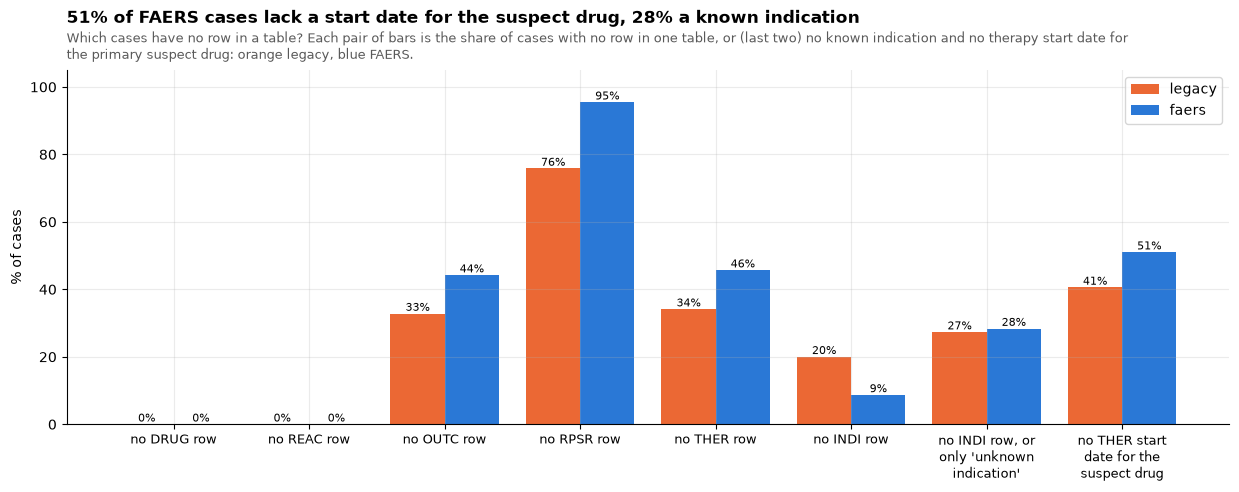

checked: FAERS cases with no OUTC row = 7,777,709


Expedited reports (rept_cod EXP: a company's 15-day report of a serious, unexpected event) with no outcome row: 436,189.


In [8]:
# A case can also have no row at all in a child table. Counted on cases.
child = q(
    " UNION ALL ".join(
        f"SELECT '{t.upper()}' AS tbl, era_T, count(*) AS cases, count(*) FILTER (WHERE NOT has_row) AS no_row FROM "
        f"(SELECT c.era_T, EXISTS (SELECT 1 FROM {t}_latest_T x WHERE x.era_T = c.era_T AND x.primaryid = c.primaryid AND x.quarter_T = c.quarter_T) AS has_row "
        f"FROM case_latest_T c) GROUP BY ALL"
        for t in TABLES[1:]
    )
)
child["pct"] = 100 * child.no_row / child.cases
extra = q("""SELECT era_T, count(*) AS cases, count(*) FILTER (WHERE NOT has_indi_T OR NOT indi_known_T) AS no_known_indication,
                    count(*) FILTER (WHERE NOT ps_start_any_T) AS no_suspect_start_date FROM w.cases_T GROUP BY 1""").set_index(
    "era_T"
)
fig, ax = plt.subplots(figsize=(15, 4.6))
p = child.pivot(index="tbl", columns="era_T", values="pct").reindex([t.upper() for t in TABLES[1:]])
p.loc["no INDI row, or\nonly 'unknown\nindication'"] = 100 * extra.no_known_indication / extra.cases
p.loc["no THER start\ndate for the\nsuspect drug"] = 100 * extra.no_suspect_start_date / extra.cases
x = np.arange(len(p))
w = 0.4
for i, era in enumerate(["legacy", "faers"]):
    label_bars(ax, ax.bar(x + (i - 0.5) * w, p[era], w, color=ERA[era], label=era), "{:.0f}%")
ax.set_xticks(x)
ax.set_xticklabels([t if t.startswith("no ") else f"no {t} row" for t in p.index], fontsize=9)
ax.set_ylabel("% of cases")
ax.set_ylim(0, 105)
ax.legend()
titled(
    ax,
    f"{p['faers'].iloc[-1]:.0f}% of FAERS cases lack a start date for the suspect drug, {p['faers'].iloc[-2]:.0f}% a known indication",
    "Which cases have no row in a table?",
    "Each pair of bars is the share of cases with no row in one table, or (last two) no known indication and no therapy start date "
    "for the primary suspect drug: orange legacy, blue FAERS.",
    width=165,
)
plt.show()
check(
    "FAERS cases with no OUTC row",
    int(child[(child.tbl == "OUTC") & (child.era_T == "faers")].no_row.sum()),
    one(
        "SELECT count(*) FROM case_latest_T c ANTI JOIN outc_latest_T o USING (era_T, primaryid, quarter_T) WHERE c.era_T = 'faers'"
    )[0],
)
EXP_NO_OUTC = one(
    "SELECT count(*) FROM case_latest_T c ANTI JOIN outc_latest_T o USING (era_T, primaryid, quarter_T) WHERE c.rept_cod = 'EXP'"
)[0]
print(
    f"Expedited reports (rept_cod EXP: a company's 15-day report of a serious, unexpected event) with no outcome row: {EXP_NO_OUTC:,}."
)

**No outcome row is not "not serious".** 44% of FAERS cases have no outcome row. FDA writes one for each serious outcome, so a missing row is often a non-serious case, but not always: the cell above counts the expedited reports, which a company sends within 15 days because the event is serious and unexpected, that carry no outcome row at all. No outcome row is neither an empty field nor proof of a non-serious case. **No report source row** (95% of FAERS cases) reflects that FDA almost stopped filling RPSR from 2015 (notebook 00). The two that matter for analysis: 28% of FAERS cases have no known indication, and 51% have no therapy start date for the primary suspect drug, which time to onset needs (section 5).

### What the reader of one product sees: Ozempic

A reader rarely looks at all of FAERS: they look at one product. Here, the cases that name Ozempic as the primary suspect drug, as the explorer finds them, against all FAERS cases. The second chart is the explorer's age chart for those cases, drawn the way every chart that reads a field that can be empty is drawn: a line under its title says how many of the cases give the field, and one grey **Not given** bar stands apart. That line is how a reader knows whether a chart is representative.

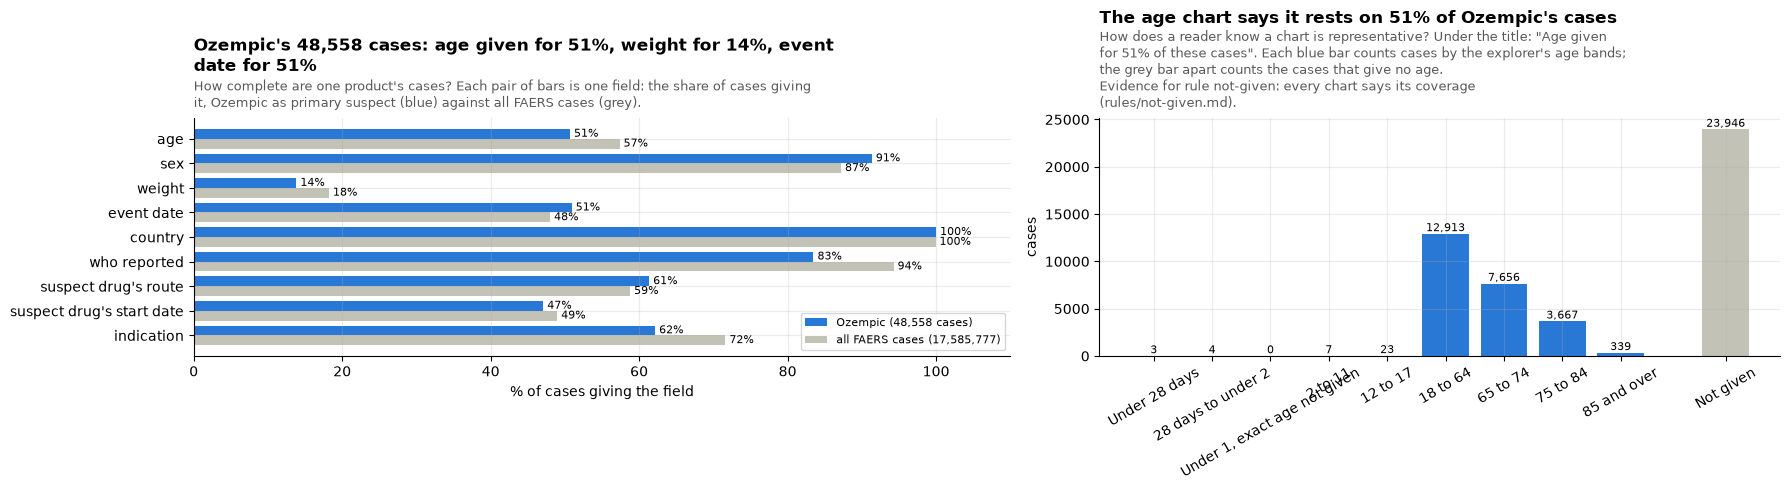

checked: cases naming OZEMPIC as primary suspect = 48,558
Who sent Ozempic's cases: Novo Nordisk 47,007 (97%); Direct reports 1,547 (3%); Torrent 3 (0%)


In [9]:
PRODUCT = "OZEMPIC"  # the example: cases naming it as the primary suspect drug (drugname_norm_T)
con.execute(f"""CREATE OR REPLACE TEMP TABLE product_T AS
SELECT c.* FROM w.cases_T c
SEMI JOIN (SELECT era_T, primaryid, quarter_T FROM drug_latest_T WHERE role_cod = 'PS' AND drugname_norm_T = '{PRODUCT}') d
USING (era_T, primaryid, quarter_T)""")
GIVEN = {
    "age": "age_s_T IS NULL",
    "sex": "sex_s_T IS NULL",
    "weight": "wt_s_T IS NULL",
    "event date": "event_dt_s_T IS NULL",
    "country": "country_s_T IS NULL",
    "who reported": "occp_s_T IS NULL",
    "suspect drug's route": "NOT coalesce(ps_route_empty_T, true)",
    "suspect drug's start date": "ps_start_any_T",
    "indication": "indi_known_T",
}
pcts = ", ".join(f'100 * avg(({c})::INT) AS "{n}"' for n, c in GIVEN.items())
prod = q(f"SELECT count(*) AS cases, {pcts} FROM product_T").iloc[0]
allf = q(f"SELECT count(*) AS cases, {pcts} FROM w.cases_T WHERE era_T = 'faers'").iloc[0]
BANDS = rulebook.value(
    "age-bands", "bands"
)  # the explorer's own age bands; the release places each case (age_band_T)
ages = (
    q(f"""SELECT CASE WHEN p.age_s_T IS NOT NULL OR p.age_years_T IS NULL THEN '{NG}' ELSE b.age_band_T END AS band, count(*) AS n
          FROM product_T p JOIN case_latest_T b USING (era_T, case_key_T) GROUP BY 1""")
    .set_index("band")
    .n.reindex([b["id"] for b in BANDS] + [NG])
    .fillna(0)
)
ages.index = [b["label"] for b in BANDS] + [NG]
COVER = 100 * (1 - ages[NG] / ages.sum())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1.2, 1]})
names = list(GIVEN)
y = np.arange(len(names))
h = 0.4
label_bars(
    a1,
    a1.barh(
        y - h / 2,
        [prod[n] for n in names],
        h,
        color=SERIES[0],
        label=f"Ozempic ({int(prod.cases):,} cases)",
    ),
    "{:.0f}%",
    horizontal=True,
)
label_bars(
    a1,
    a1.barh(
        y + h / 2,
        [allf[n] for n in names],
        h,
        color=SERIES[7],
        label=f"all FAERS cases ({int(allf.cases):,})",
    ),
    "{:.0f}%",
    horizontal=True,
)
a1.set_yticks(y)
a1.set_yticklabels(names)
a1.invert_yaxis()
a1.set_xlim(0, 110)
a1.set_xlabel("% of cases giving the field")
a1.legend(loc="lower right", fontsize=8)
titled(
    a1,
    f"Ozempic's {int(prod.cases):,} cases: age given for {prod['age']:.0f}%, weight for {prod['weight']:.0f}%, event date for {prod['event date']:.0f}%",
    "How complete are one product's cases?",
    "Each pair of bars is one field: the share of cases giving it, Ozempic as primary suspect (blue) against all FAERS cases (grey).",
    width=95,
)
xb = list(range(len(BANDS))) + [len(BANDS) + 0.8]  # Not given set apart
bars = a2.bar(xb, ages.values, color=[SERIES[0]] * len(BANDS) + [SERIES[7]], width=0.8)
label_bars(a2, bars, "{:,.0f}")
a2.set_xticks(xb)
a2.set_xticklabels(ages.index, rotation=30)
a2.set_ylabel("cases")
titled(
    a2,
    f"The age chart says it rests on {COVER:.0f}% of Ozempic's cases",
    "How does a reader know a chart is representative?",
    f'Under the title: "Age given for {COVER:.0f}% of these cases". Each blue bar counts cases by the explorer\'s age bands; the grey '
    f"bar apart counts the cases that give no age.",
    backs="Evidence for rule not-given: every chart says its coverage\n(rules/not-given.md).",
    width=80,
)
plt.tight_layout()
plt.show()
check(
    f"cases naming {PRODUCT} as primary suspect",
    int(prod.cases),
    one(
        f"SELECT count(DISTINCT (era_T, primaryid, quarter_T)) FROM drug_latest_T WHERE role_cod = 'PS' AND drugname_norm_T = '{PRODUCT}'"
    )[0],
)
OZ_SENDERS = q(
    "SELECT sender_T, count(*) AS cases FROM product_T GROUP BY 1 ORDER BY 2 DESC LIMIT 3"
)
print(
    "Who sent Ozempic's cases: "
    + "; ".join(
        f"{r.sender_T} {r.cases:,} ({100 * r.cases / prod.cases:.0f}%)"
        for r in OZ_SENDERS.itertuples()
    )
)

**What section 2 shows**

- **Which fields are empty, legacy.** *Shows:* every field's share of cases or rows that read Not given, split by kind. *Point:* legacy's empty fields are mostly columns its files never had. *So what:* comparing a field across eras means reading which quarters had the column at all.
- **Which fields are empty, FAERS.** *Shows:* the same for FAERS. *Point:* weight is not given in 82% of cases, event date in 52%, age in 43%; route in 61% of drug rows. *So what:* any count by age, weight or date rests on a part of the cases, and the part differs by field.
- **Cases with no row in a table.** *Shows:* the share of cases with no row in each child table. *Point:* 51% of FAERS cases have no start date for the suspect drug and 28% no known indication; 436,189 expedited reports, serious by definition, have no outcome row. *So what:* time to onset and indication analyses rest on a minority of cases, and no outcome row never means "not serious".
- **One product's cases.** *Shows:* how often Ozempic's 48,558 cases give each field, against all FAERS cases. *Point:* age is given in 51% of them, weight in 14%, event date in 51%, and 97% were sent by one company, Novo Nordisk. *So what:* a reader of one product sees its senders' habits, not FAERS's average.
- **The age chart with its coverage line.** *Shows:* Ozempic's cases by age band, with Not given apart. *Point:* the chart rests on 51% of the cases, and says so under its title. *So what:* every chart that reads a field that can be empty states its coverage, following the reader's filters, so they know whether what they see is representative.

## 3. Over time, quarter by quarter

Rows as FDA published them in each quarterly file (DEMO: one row per report version). Each cell is the share of rows that read Not given in that quarter; grey means the column was not in that quarter's file.

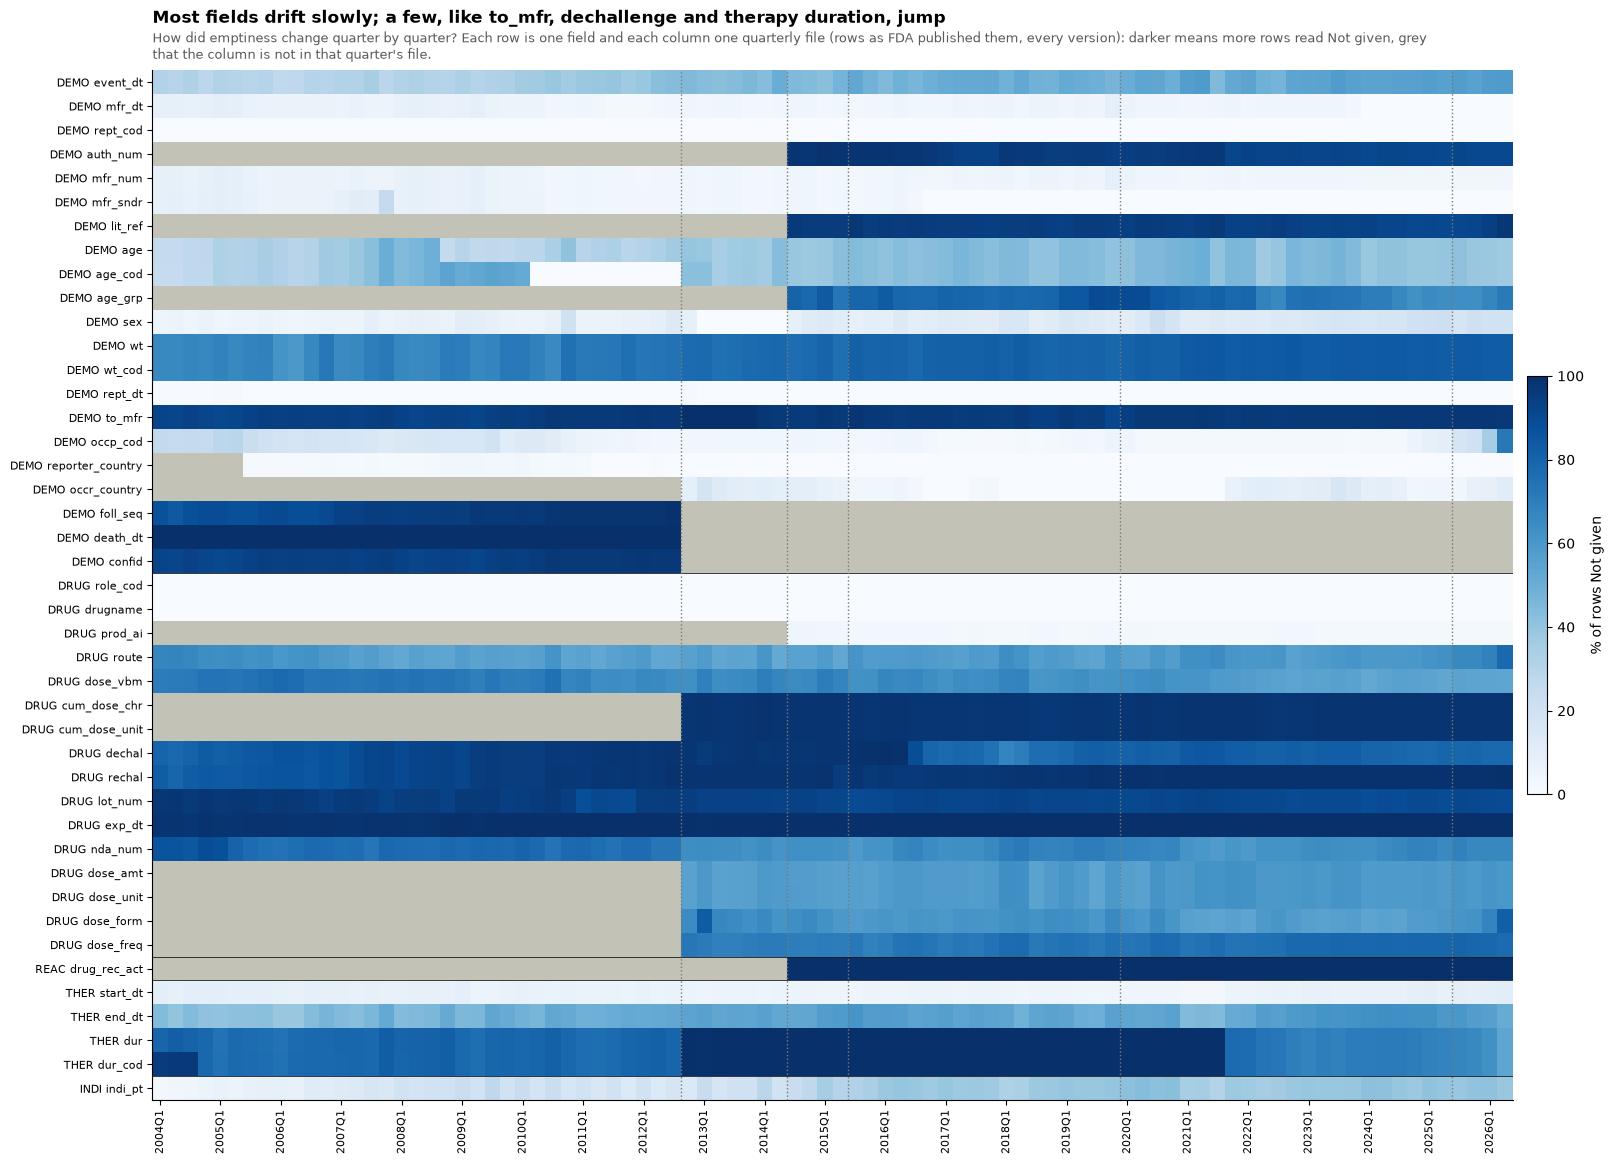

43 fields shown; 10 are never empty in any quarter: DEMO caseversion, DEMO i_f_code, DEMO init_fda_dt, DEMO fda_dt, DEMO e_sub, DEMO image, DRUG val_vbm, REAC pt, OUTC outc_cod, RPSR rpsr_cod


In [10]:
# Quarter by quarter, rows as FDA published them in each quarterly file (DEMO: one row per report version).
def empty_share(d):
    """% of rows Not given (blank, says unknown, filler) per field and quarter; NaN where the column is not in that quarter's file."""
    d = d.assign(
        pct=np.where(
            d.in_file, 100 * d[KINDS[1:]].sum(axis=1) / d.rows_T.where(d.rows_T > 0), np.nan
        )
    )
    return d.pivot_table(
        index="field", columns="quarter_T", values="pct", aggfunc="first", dropna=False
    ).reindex(columns=QS)


SHARE = empty_share(RAW).reindex([f"{t.upper()} {c}" for t, c in FIELDS])
SHARE = SHARE[SHARE.max(axis=1) > 0]  # fields never empty in any quarter are left out
fig, ax = plt.subplots(figsize=(18, 0.26 * len(SHARE) + 2.2))
ax.imshow(
    np.where(np.isnan(SHARE.values), 1, np.nan),
    aspect="auto",
    cmap=mpl.colors.ListedColormap([KIND_COLOUR["not in file"]]),
    interpolation="nearest",
)
im = ax.imshow(
    np.ma.masked_invalid(SHARE.values),
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=100,
    interpolation="nearest",
)
ax.grid(False)
ax.set_yticks(range(len(SHARE)))
ax.set_yticklabels(SHARE.index, fontsize=8)
quarter_ticks(ax, QS)
event_lines(ax, QS)
for t in TABLES[1:]:
    first = [i for i, f in enumerate(SHARE.index) if f.startswith(t.upper() + " ")]
    if first:
        ax.axhline(first[0] - 0.5, color="#1a1a19", lw=0.6)
fig.colorbar(im, ax=ax, fraction=0.015, pad=0.01, label=f"% of rows {NG}")
titled(
    ax,
    "Most fields drift slowly; a few, like to_mfr, dechallenge and therapy duration, jump",
    "How did emptiness change quarter by quarter?",
    f"Each row is one field and each column one quarterly file (rows as FDA published them, every version): darker means more rows "
    f"read {NG}, grey that the column is not in that quarter's file.",
    width=190,
)
plt.show()
print(
    f"{len(SHARE)} fields shown; {len(FIELDS) - len(SHARE)} are never empty in any quarter: "
    + ", ".join(f for f in [f"{t.upper()} {c}" for t, c in FIELDS] if f not in SHARE.index)
)

Most fields drift slowly. Weight and event date are emptier now than in 2004; the country of the event became emptier again from 2022. A few fields jump. The cell below finds the jumps: a break is a change of at least 15 points between the median of four quarters and the median of the next four. The charts show sixteen fields, with the breaks found marked, and the table says what each break is.

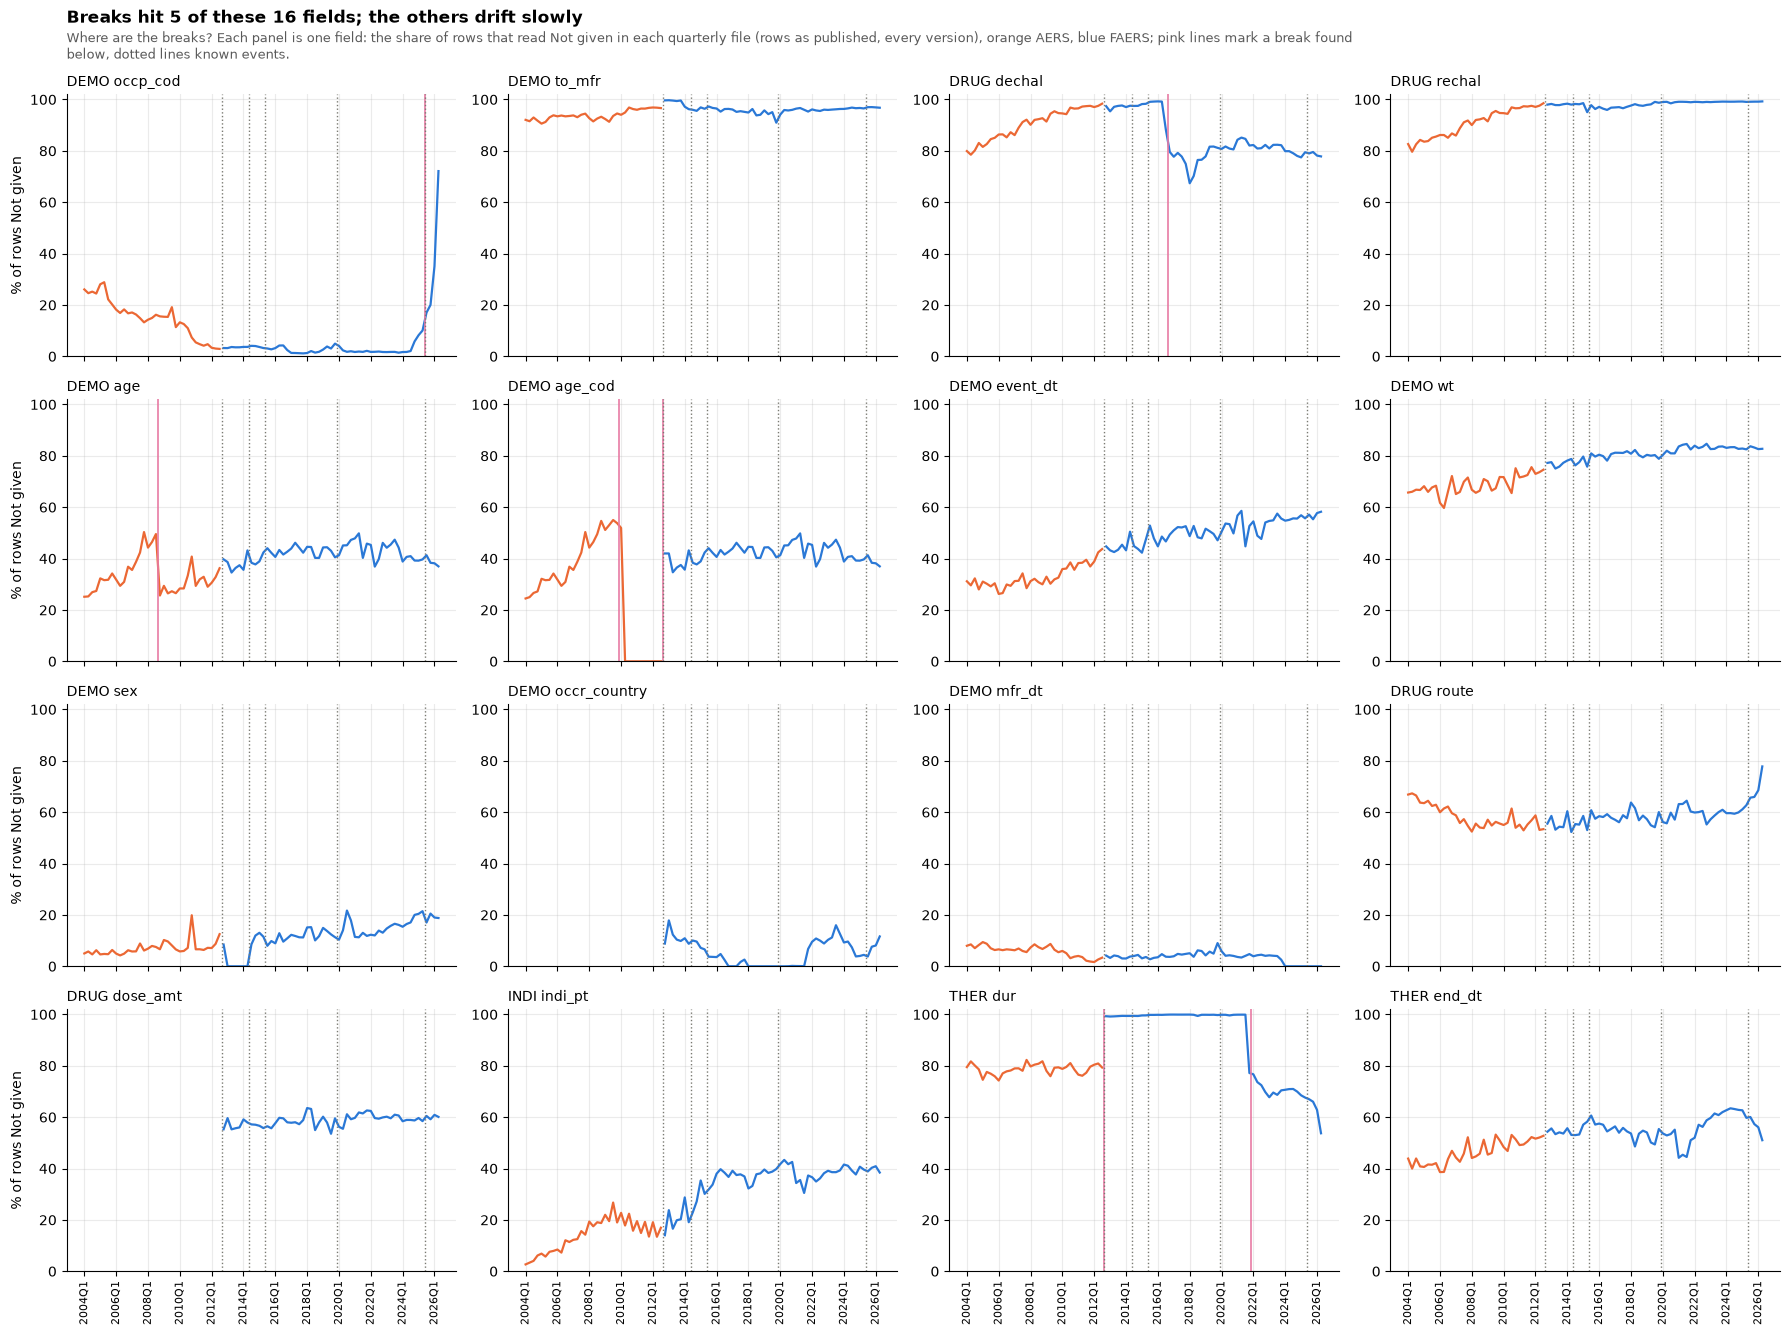

checked: DEMO rows with occp_cod blank in 2026Q2 (rows as published) = 304,677


,field,quarter,before %,after %,jump,what it is
0,THER dur_cod,2005q1,95.5,76.6,-18.9,not explained
1,DEMO age,2008q4,48.0,26.9,-21.1,not explained; not fillers (an age of 0 is under 1% of ages)
2,DEMO age_cod,2010q1,53.4,0.0,-53.4,AERS writes an age unit even without an age from 2010
3,DEMO age_cod,2012q4,0.0,39.2,39.2,FAERS leaves the unit blank when the age is blank; AERS wrote a un...
4,THER dur,2012q4,80.0,99.3,19.2,FAERS gives a therapy duration almost never until 2022 (therapy du...
5,THER dur_cod,2012q4,80.0,99.3,19.2,FAERS gives a therapy duration almost never until 2022 (therapy du...
6,DRUG dechal,2016q4,99.2,78.5,-20.7,"dechallenge filled again from 2016Q3 (dechallenge and rechallenge,..."
7,THER dur,2022q1,99.9,73.0,-26.8,"duration filled from 2022, most likely worked out from the dates (..."
8,THER dur_cod,2022q1,99.9,73.0,-26.9,"duration filled from 2022, most likely worked out from the dates (..."
9,DEMO occp_cod,2025q3,7.0,27.6,20.5,FDA's files leave who reported blank on company reports (section 4)


In [11]:
def find_breaks(share, window=4, min_jump=15):
    """A break: the median of the next `window` quarters differs from the median of the `window` before by at least
    `min_jump` points. Per field, only the largest jump within `window` quarters is kept."""
    rows = []
    for field, s in share.iterrows():
        v = s.values
        jumps = []
        for i in range(window, len(v) - window + 1):
            before, after = v[i - window : i], v[i : i + window]
            if not (np.isnan(before).any() or np.isnan(after).any()):
                jumps.append((i, np.median(after) - np.median(before)))
        big = [(i, j) for i, j in jumps if abs(j) >= min_jump]
        for i, j in big:
            if abs(j) == max(abs(jj) for ii, jj in big if abs(ii - i) <= window) and not any(
                r["field"] == field and abs(QS.index(r["quarter"]) - i) <= window for r in rows
            ):
                rows.append(
                    {
                        "field": field,
                        "quarter": QS[i],
                        "before %": np.median(v[i - window : i]),
                        "after %": np.median(v[i : i + window]),
                        "jump": j,
                    }
                )
    return pd.DataFrame(rows).sort_values(["quarter", "field"]).reset_index(drop=True)


KNOWN = {  # what each break is: the sections below, and notebooks 00 and 01
    (
        "DRUG dechal",
        "2016q4",
    ): "dechallenge filled again from 2016Q3 (dechallenge and rechallenge, below)",
    (
        "DEMO occp_cod",
        "2025q3",
    ): "FDA's files leave who reported blank on company reports (section 4)",
    ("DEMO age_cod", "2010q1"): "AERS writes an age unit even without an age from 2010",
    (
        "DEMO age_cod",
        "2012q4",
    ): "FAERS leaves the unit blank when the age is blank; AERS wrote a unit anyway from 2010",
    ("DEMO age", "2008q4"): "not explained; not fillers (an age of 0 is under 1% of ages)",
    (
        "THER dur",
        "2012q4",
    ): "FAERS gives a therapy duration almost never until 2022 (therapy duration, below)",
    (
        "THER dur_cod",
        "2012q4",
    ): "FAERS gives a therapy duration almost never until 2022 (therapy duration, below)",
    (
        "THER dur",
        "2022q1",
    ): "duration filled from 2022, most likely worked out from the dates (therapy duration, below)",
    (
        "THER dur_cod",
        "2022q1",
    ): "duration filled from 2022, most likely worked out from the dates (therapy duration, below)",
}
BREAKS = find_breaks(SHARE)
BREAKS["what it is"] = [
    KNOWN.get((r.field, r.quarter), "not explained") for r in BREAKS.itertuples()
]
WATCH = [
    "DEMO occp_cod",
    "DEMO to_mfr",
    "DRUG dechal",
    "DRUG rechal",
    "DEMO age",
    "DEMO age_cod",
    "DEMO event_dt",
    "DEMO wt",
    "DEMO sex",
    "DEMO occr_country",
    "DEMO mfr_dt",
    "DRUG route",
    "DRUG dose_amt",
    "INDI indi_pt",
    "THER dur",
    "THER end_dt",
]
fig, axes = plt.subplots(4, 4, figsize=(18, 12.8), sharex=True)
for ax, f in zip(axes.flat, WATCH, strict=True):
    s = SHARE.loc[f] if f in SHARE.index else pd.Series(np.nan, index=QS)
    for era in ["legacy", "faers"]:
        m = (QUARTERS.era_T == era).values
        ax.plot(np.arange(len(QS))[m], s.values[m], color=ERA[era], lw=1.6)
    for r in BREAKS[BREAKS.field == f].itertuples():
        ax.axvline(QS.index(r.quarter) - 0.5, color=SERIES[4], lw=1.2)
    ax.set_ylim(0, 102)
    ax.set_title(f, loc="left", fontsize=10)
    event_lines(ax, QS)
for ax in axes[-1]:
    quarter_ticks(ax, QS, every=8)
for ax in axes[:, 0]:
    ax.set_ylabel(f"% of rows {NG}")
plt.tight_layout()
head = header(fig)  # the figure's title sits on this empty strip above the panels
titled(
    head,
    f"Breaks hit {BREAKS[BREAKS.field.isin(WATCH)].field.nunique()} of these {len(WATCH)} fields; the others drift slowly",
    "Where are the breaks?",
    f"Each panel is one field: the share of rows that read {NG} in each quarterly file (rows as published, every version), orange "
    "AERS, blue FAERS; pink lines mark a break found below, dotted lines known events.",
    width=200,
)
plt.show()
check(
    "DEMO rows with occp_cod blank in 2026Q2 (rows as published)",
    int(RAW[(RAW.field == "DEMO occp_cod") & (RAW.quarter_T == "2026q2")].blank.sum()),
    one("SELECT count(*) FROM demo WHERE quarter_T = '2026q2' AND occp_cod IS NULL")[0],
)
BREAKS.round(1)

### Dechallenge, rechallenge, and what `D` means

Two questions FDA's files ask of each suspect drug:

- **Dechallenge** (`dechal`): when the drug was stopped or the dose lowered, did the reaction stop or lessen? `Y` yes, `N` no, `U` unknown, `D` does not apply (for example, the drug was never stopped).
- **Rechallenge** (`rechal`): when the drug was given again, did the reaction come back? The same four codes.

A `Y` on both is some of the strongest evidence a single report can give that the drug caused the reaction, so how the two are filled matters. The charts below show each code's share of drug rows, quarter by quarter, and test whether rechallenge `D` from 2012Q4 to 2015Q3 is something senders said.

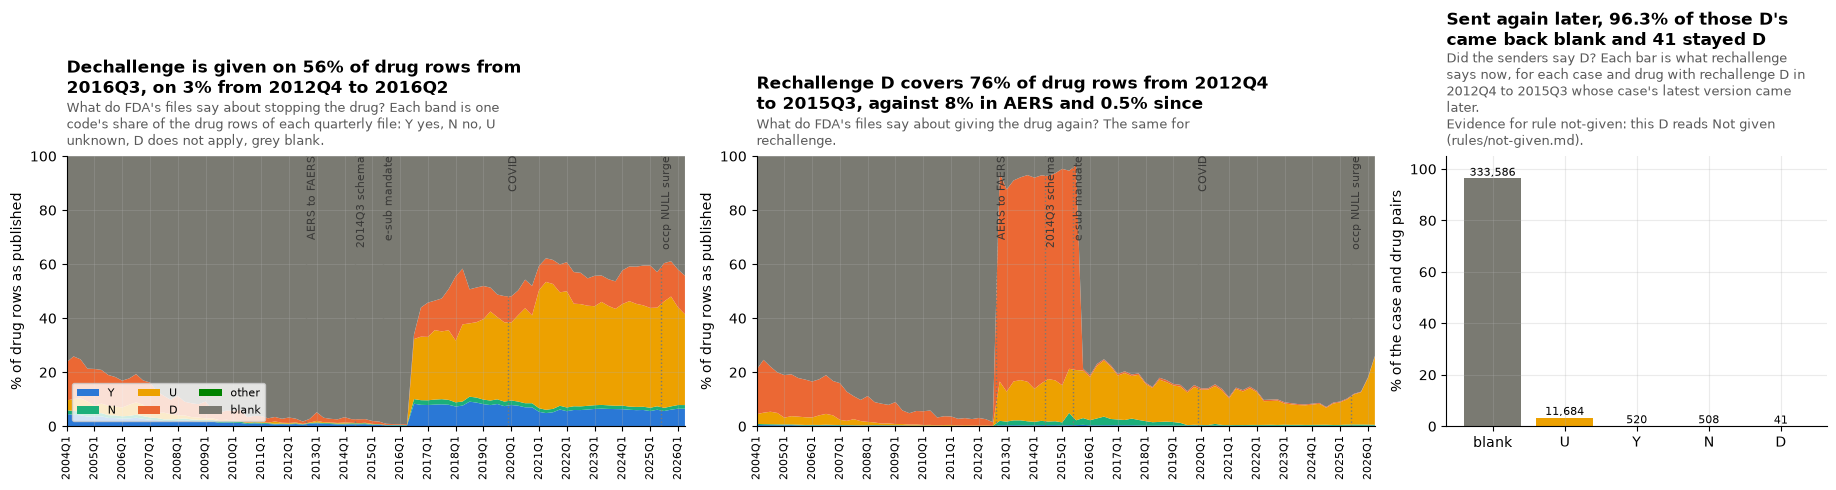

In AERS, D is 75% to 91% of the filled rechallenge values each quarter (median 8% of drug rows): a real, common answer. Case and drug pairs sent again: 346,339; blank now 333,586 (96.3%), U 11,684, D 41.
checked: drug rows as published with rechallenge D in the filler quarters = 7,414,486


In [12]:
CODES = ["Y", "N", "U", "D"]
CODE_COL = {
    "Y": SERIES[0],
    "N": SERIES[2],
    "U": SERIES[3],
    "D": SERIES[1],
    "blank": KIND_COLOUR["blank"],
    "other": SERIES[5],
}
CHAL = q(
    " UNION ALL ".join(
        f"""SELECT quarter_T, '{f}' AS field, CASE WHEN {blank_sql(f)} THEN 'blank' WHEN {V(f)} IN ('Y', 'N', 'U', 'D') THEN {V(f)} ELSE 'other' END AS code, count(*) AS n
        FROM drug GROUP BY ALL"""
        for f in ["dechal", "rechal"]
    )
)
W = RULE["rechal"][
    "codes_in_quarters"
]  # the quarters whose rechallenge D the rule reads as a filler
# the proof: each case and drug with rechallenge D in those quarters, whose case's latest version came later
resent = (
    q(f"""
WITH d AS (SELECT DISTINCT caseid, upper(trim(drugname)) AS name_T FROM drug
           WHERE quarter_T BETWEEN '{W["from"]}' AND '{W["to"]}' AND {V("rechal")} = 'D')
SELECT CASE WHEN {blank_sql("l.rechal")} THEN 'blank' ELSE {V("l.rechal")} END AS now_T, count(*) AS n
FROM d JOIN drug_latest_T l ON l.caseid = d.caseid AND upper(trim(l.drugname)) = d.name_T AND l.quarter_T > '{W["to"]}'
GROUP BY 1""")
    .set_index("now_T")
    .n.reindex(["blank", "U", "Y", "N", "D"])
    .fillna(0)
    .astype(int)
)
fig, (a1, a2, a3) = plt.subplots(
    1, 3, figsize=(19, 5), gridspec_kw={"width_ratios": [1.3, 1.3, 0.8]}
)
SHARES = {}
for ax, f in zip((a1, a2), ["dechal", "rechal"], strict=True):
    p = (
        CHAL[CHAL.field == f]
        .pivot_table(index="quarter_T", columns="code", values="n", aggfunc="sum")
        .reindex(QS)
        .fillna(0)
    )
    p = 100 * p.div(p.sum(axis=1), axis=0).reindex(columns=[*CODES, "other", "blank"]).fillna(0)
    SHARES[f] = p
    ax.stackplot(
        range(len(QS)),
        *[p[c] for c in p.columns],
        colors=[CODE_COL[c] for c in p.columns],
        labels=list(p.columns),
    )
    ax.set_ylim(0, 100)
    ax.set_xlim(0, len(QS) - 1)
    ax.set_ylabel("% of drug rows as published")
    quarter_ticks(ax, QS)
    mark_quarters(ax, QS)
inw = (SHARES["rechal"].index >= W["from"]) & (SHARES["rechal"].index <= W["to"])
after_w = SHARES["rechal"].index > W["to"]
DECHAL_GIVEN = 100 - SHARES["dechal"]["blank"]
dechal_gap = (DECHAL_GIVEN.index >= "2012q4") & (DECHAL_GIVEN.index <= "2016q2")
legacy_q = QUARTERS.set_index("quarter_T").era_T.reindex(SHARES["rechal"].index) == "legacy"
filled = SHARES["rechal"][CODES].sum(axis=1)
d_of_filled = 100 * SHARES["rechal"]["D"] / filled.where(filled > 0)
titled(
    a1,
    f"Dechallenge is given on {DECHAL_GIVEN[DECHAL_GIVEN.index >= '2016q3'].median():.0f}% of drug rows from 2016Q3, "
    f"on {DECHAL_GIVEN[dechal_gap].median():.0f}% from 2012Q4 to 2016Q2",
    "What do FDA's files say about stopping the drug?",
    "Each band is one code's share of the drug rows of each quarterly file: Y yes, N no, U unknown, D does not apply, grey blank.",
    width=70,
)
a1.legend(loc="lower left", fontsize=8, ncol=3)
titled(
    a2,
    f"Rechallenge D covers {SHARES['rechal'].loc[inw, 'D'].median():.0f}% of drug rows from {W['from'].upper()} to {W['to'].upper()}, "
    f"against {SHARES['rechal'].loc[legacy_q, 'D'].median():.0f}% in AERS and {SHARES['rechal'].loc[after_w, 'D'].median():.1f}% since",
    "What do FDA's files say about giving the drug again?",
    "The same for rechallenge.",
    width=70,
)
bars = a3.bar(resent.index, 100 * resent / resent.sum(), color=[CODE_COL[c] for c in resent.index])
for b, n in zip(bars, resent.values, strict=True):
    a3.text(
        b.get_x() + b.get_width() / 2,
        b.get_height(),
        f"{n:,}",
        ha="center",
        va="bottom",
        fontsize=8,
    )
a3.set_ylim(0, 105)
a3.set_ylabel("% of the case and drug pairs")
RESENT_BLANK = 100 * resent["blank"] / resent.sum()
titled(
    a3,
    f"Sent again later, {RESENT_BLANK:.1f}% of those D's came back blank and {resent['D']:,} stayed D",
    "Did the senders say D?",
    f"Each bar is what rechallenge says now, for each case and drug with rechallenge D in {W['from'].upper()} to {W['to'].upper()} "
    f"whose case's latest version came later.",
    backs="Evidence for rule not-given: this D reads Not given\n(rules/not-given.md).",
    width=55,
)
plt.tight_layout()
plt.show()
print(
    f"In AERS, D is {d_of_filled[legacy_q].min():.0f}% to {d_of_filled[legacy_q].max():.0f}% of the filled rechallenge values each quarter "
    f"(median {SHARES['rechal'].loc[legacy_q, 'D'].median():.0f}% of drug rows): a real, common answer. "
    f"Case and drug pairs sent again: {resent.sum():,}; blank now {resent['blank']:,} ({RESENT_BLANK:.1f}%), U {resent['U']:,}, D {resent['D']:,}."
)
check(
    "drug rows as published with rechallenge D in the filler quarters",
    int(
        CHAL[
            (CHAL.field == "rechal")
            & (CHAL.code == "D")
            & CHAL.quarter_T.between(W["from"], W["to"])
        ].n.sum()
    ),
    one(
        f"SELECT count(*) FROM drug WHERE upper(trim(rechal)) = 'D' AND quarter_T BETWEEN '{W['from']}' AND '{W['to']}'"
    )[0],
)

**`D` is a filler from 2012Q4 to 2015Q3, and a real answer before.** In those twelve quarters FDA's files give rechallenge `D` on most drug rows, while dechallenge is almost empty. When the same case was sent again later, the same drug's rechallenge came back blank almost every time and `D` almost never: the senders had not said `D`. Before 2012Q4, in AERS, `D` is a real and common answer, three quarters or more of the filled rechallenge values. From 2015Q4 to 2016Q2 both fields are nearly empty, and dechallenge fills again from 2016Q3. So the rule reads rechallenge `D` as Not given in 2012Q4 to 2015Q3 only, and the explorer notes the change on both fields from 2012Q4 to 2016Q2 (rule `explorer-field-notes`).

### Whether the reporter also told the company (`to_mfr`)

`to_mfr` asks whether a person who reported straight to FDA also told the company. It means something only on a direct report: a company report came from the company.

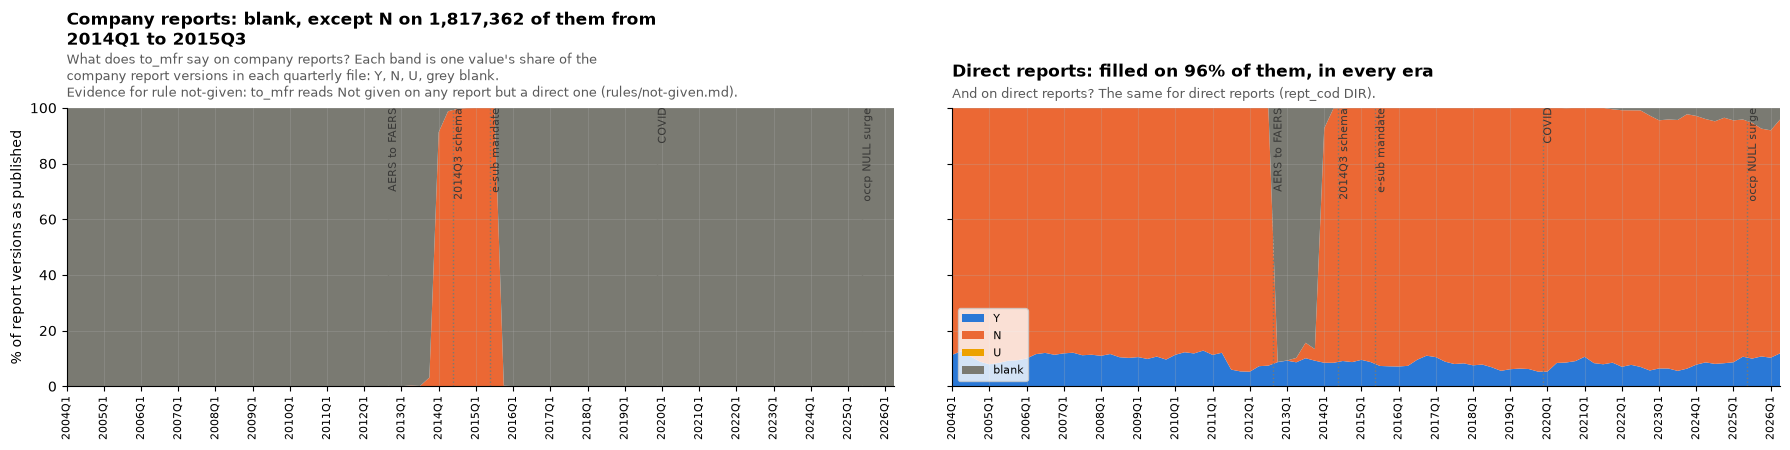

In [13]:
TOMFR = q(f"""SELECT quarter_T, CASE WHEN rept_cod = 'DIR' THEN 'direct reports' ELSE 'company reports' END AS who,
                     CASE WHEN {blank_sql("to_mfr")} THEN 'blank' ELSE {V("to_mfr")} END AS v, count(*) AS n
              FROM demo GROUP BY ALL""")
fig, axes = plt.subplots(1, 2, figsize=(18, 4.6), sharey=True)
TO_COL = {"Y": SERIES[0], "N": SERIES[1], "U": SERIES[3], "blank": KIND_COLOUR["blank"]}
TO_SHARE = {}
for ax, who in zip(axes, ["company reports", "direct reports"], strict=True):
    p = (
        TOMFR[TOMFR.who == who]
        .pivot_table(index="quarter_T", columns="v", values="n", aggfunc="sum")
        .reindex(QS)
        .fillna(0)
    )
    p = 100 * p.div(p.sum(axis=1), axis=0).reindex(columns=list(TO_COL)).fillna(0)
    TO_SHARE[who] = p
    ax.stackplot(
        range(len(QS)), *[p[c] for c in TO_COL], colors=list(TO_COL.values()), labels=list(TO_COL)
    )
    ax.set_xlim(0, len(QS) - 1)
    ax.set_ylim(0, 100)
    quarter_ticks(ax, QS)
    mark_quarters(ax, QS)
axes[0].set_ylabel("% of report versions as published")
axes[1].legend(loc="lower left", fontsize=8)
N_WINDOW = TO_SHARE["company reports"][TO_SHARE["company reports"]["N"] > 50].index
TO_N = int(
    TOMFR[
        (TOMFR.who == "company reports") & (TOMFR.v == "N") & TOMFR.quarter_T.isin(N_WINDOW)
    ].n.sum()
)
DIR_FILLED = 100 * (
    1
    - TOMFR[(TOMFR.who == "direct reports") & (TOMFR.v == "blank")].n.sum()
    / TOMFR[TOMFR.who == "direct reports"].n.sum()
)
titled(
    axes[0],
    f"Company reports: blank, except N on {TO_N:,} of them from {N_WINDOW.min().upper()} to {N_WINDOW.max().upper()}",
    "What does to_mfr say on company reports?",
    "Each band is one value's share of the company report versions in each quarterly file: Y, N, U, grey blank.",
    backs="Evidence for rule not-given: to_mfr reads Not given on any report but a direct one (rules/not-given.md).",
    width=85,
)
titled(
    axes[1],
    f"Direct reports: filled on {DIR_FILLED:.0f}% of them, in every era",
    "And on direct reports?",
    "The same for direct reports (rept_cod DIR).",
    width=85,
)
plt.tight_layout()
plt.show()

On a company report `to_mfr` is blank in almost every quarter; from 2014Q1 to 2015Q3 it says `N` on nearly all of them, which no sender meant: a filler. On direct reports it is filled in every quarter, AERS and FAERS. So the rule reads `to_mfr` only on direct reports, and the field is no longer nearly empty once read where it means something.

### Therapy duration from 2022

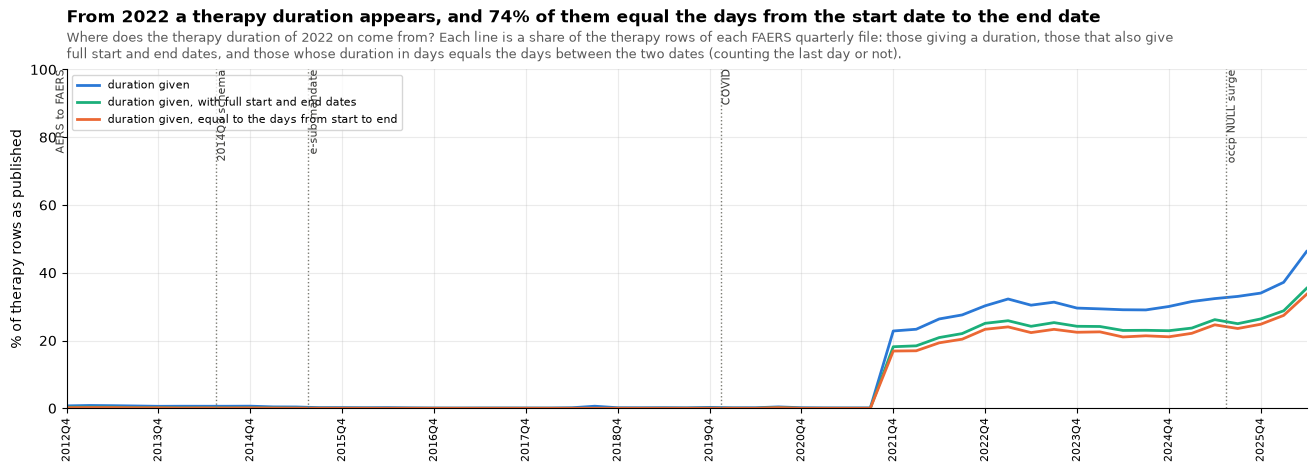

From 2022Q1: 3,184,967 therapy rows give a duration, 79% with both full dates, and 93% of those equal the days between them; most common values: 1 DAY (838,316), 2 DAY (102,927), 3 DAY (98,058)


In [14]:
DUR = (
    q(f"""
SELECT quarter_T, count(*) AS rows_T, count(*) FILTER (WHERE NOT {blank_sql("dur")}) AS dur_T,
       count(*) FILTER (WHERE NOT {blank_sql("dur")} AND {FULL_DATE("start_dt")} AND {FULL_DATE("end_dt")}) AS both_dates_T,
       count(*) FILTER (WHERE NOT {blank_sql("dur")} AND upper(trim(dur_cod)) = 'DAY'
                        AND try_cast(dur AS DOUBLE) - date_diff('day', try_strptime(start_dt, '%Y%m%d'), try_strptime(end_dt, '%Y%m%d')) IN (0, 1)) AS from_dates_T
FROM ther WHERE era_T = 'faers' GROUP BY 1""")
    .set_index("quarter_T")
    .reindex([x for x in QS if x >= "2012q4"])
)
top_dur = q(f"""SELECT trim(dur) || ' ' || coalesce(trim(dur_cod), '') AS value, count(*) AS n FROM ther
                WHERE era_T = 'faers' AND quarter_T >= '2022q1' AND NOT {blank_sql("dur")} GROUP BY 1 ORDER BY 2 DESC LIMIT 3""")
fig, ax = plt.subplots(figsize=(16, 4.4))
xs = range(len(DUR))
ax.plot(xs, 100 * DUR.dur_T / DUR.rows_T, color=SERIES[0], label="duration given")
ax.plot(
    xs,
    100 * DUR.both_dates_T / DUR.rows_T,
    color=SERIES[2],
    label="duration given, with full start and end dates",
)
ax.plot(
    xs,
    100 * DUR.from_dates_T / DUR.rows_T,
    color=SERIES[1],
    label="duration given, equal to the days from start to end",
)
ax.set_ylim(0, 100)
ax.set_xlim(0, len(DUR) - 1)
ax.set_ylabel("% of therapy rows as published")
quarter_ticks(ax, DUR.index)
mark_quarters(ax, DUR.index)
ax.legend(loc="upper left", fontsize=8)
recent = DUR.loc["2022q1":].sum()
FROM_DATES = 100 * recent.from_dates_T / recent.dur_T
titled(
    ax,
    f"From 2022 a therapy duration appears, and {FROM_DATES:.0f}% of them equal the days from the start date to the end date",
    "Where does the therapy duration of 2022 on come from?",
    "Each line is a share of the therapy rows of each FAERS quarterly file: those giving a duration, those that also give full start "
    "and end dates, and those whose duration in days equals the days between the two dates (counting the last day or not).",
    width=170,
)
plt.show()
print(
    f"From 2022Q1: {int(recent.dur_T):,} therapy rows give a duration, {100 * recent.both_dates_T / recent.dur_T:.0f}% with both full dates, "
    f"and {100 * recent.from_dates_T / recent.both_dates_T:.0f}% of those equal the days between them; "
    f"most common values: " + ", ".join(f"{r.value} ({r.n:,})" for r in top_dur.itertuples())
)

Therapy duration was almost never filled in FAERS until 2022Q1. From then on it appears on about a third of therapy rows, nearly always beside a full start and end date, most often as `1 DAY`, and most of the time it equals the days between the two dates. FDA most likely works it out from the dates. It adds nothing a reader cannot get from the dates, and nothing in the explorer reads it.

### The newest quarters: unknown turning into blank

A break in the newest quarter cannot be seen with four quarters after it, so here the last ten quarters of three fields that moved at once.

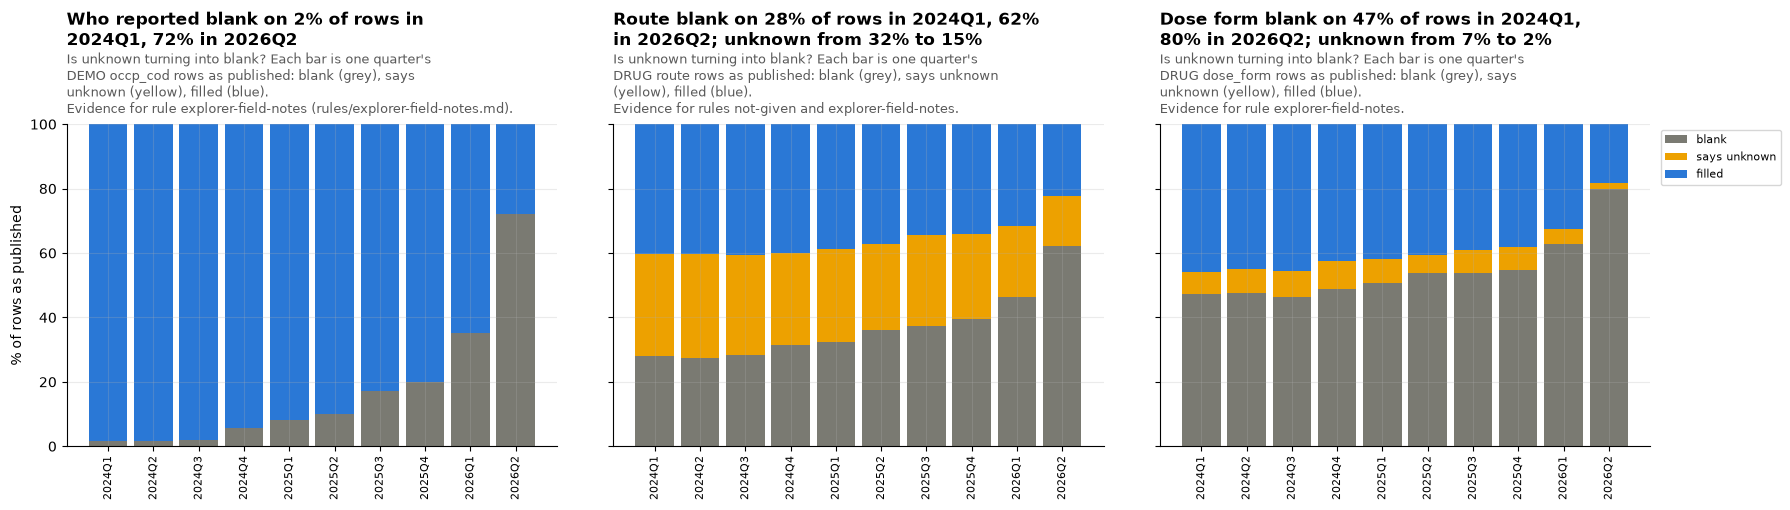

checked: DRUG rows in 2026q2 with route blank = 1,013,885


checked: route blank in FDA's own 2026Q2 DRUG file = in the release = 1,013,885
Route in 2025Q4: 39% blank, 27% unknown. In 2026Q2: 62% blank, 15% unknown.


In [15]:
RECENT = QS[QS.index("2024q1") :]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), sharey=True)
NAME = {"DEMO occp_cod": "Who reported", "DRUG route": "Route", "DRUG dose_form": "Dose form"}
BACKS = {
    "DEMO occp_cod": "Evidence for rule explorer-field-notes (rules/explorer-field-notes.md).",
    "DRUG route": "Evidence for rules not-given and explorer-field-notes.",
    "DRUG dose_form": "Evidence for rule explorer-field-notes.",
}
NEWEST = {}
for ax, f in zip(axes, NAME, strict=True):
    d = (
        RAW[RAW.field == f]
        .groupby("quarter_T")[["rows_T", "blank", "says unknown", "filler"]]
        .sum()
        .reindex(RECENT)
    )
    parts = {
        "blank": d.blank,
        "says unknown": d["says unknown"] + d["filler"],
        "filled": d.rows_T - d.blank - d["says unknown"] - d["filler"],
    }
    bottom = np.zeros(len(d))
    for k in ["blank", "says unknown", "filled"]:
        v = 100 * parts[k] / d.rows_T
        ax.bar(range(len(d)), v, bottom=bottom, color=KIND_COLOUR[k], label=k, width=0.85)
        bottom += v.values
    ax.set_xticks(range(len(d)))
    ax.set_xticklabels([x.upper() for x in d.index], rotation=90, fontsize=8)
    ax.set_ylim(0, 100)
    shr = NEWEST[f] = pd.DataFrame({k: 100 * parts[k] / d.rows_T for k in parts})
    claim = f"{NAME[f]} blank on {shr['blank'].iloc[0]:.0f}% of rows in {RECENT[0].upper()}, {shr['blank'].iloc[-1]:.0f}% in {RECENT[-1].upper()}"
    if shr["says unknown"].iloc[0] >= 1:
        claim += f"; unknown from {shr['says unknown'].iloc[0]:.0f}% to {shr['says unknown'].iloc[-1]:.0f}%"
    titled(
        ax,
        claim,
        "Is unknown turning into blank?",
        f"Each bar is one quarter's {f} rows as published: blank (grey), says unknown (yellow), filled (blue).",
        backs=BACKS[f],
        width=58,
    )
axes[0].set_ylabel("% of rows as published")
axes[2].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()
route = NEWEST["DRUG route"]
check(
    f"DRUG rows in {QS[-1]} with route blank",
    int(RAW[(RAW.field == "DRUG route") & (RAW.quarter_T == QS[-1])].blank.sum()),
    one(
        f"SELECT count(*) FROM drug WHERE quarter_T = '{QS[-1]}' AND (route IS NULL OR trim(route) = '')"
    )[0],
)
if ZIPS:  # the same count straight from the text of FDA's own file: the shift is in FDA's file, not our loader
    qz = next(z for z in discover(Path(ZIPS).expanduser()) if z.name == QS[-1])
    with zipfile.ZipFile(qz.path) as z, z.open(qz.table_file("drug")) as f:
        head = [
            unified_name("drug", h)
            for h in f.readline().decode("utf-8", "replace").rstrip("\r\n").split("$")
        ]
        at = head.index("route")
        in_file = sum(
            not line.decode("utf-8", "replace").rstrip("\r\n").split("$")[at].strip() for line in f
        )
    check(
        f"route blank in FDA's own {QS[-1].upper()} DRUG file = in the release",
        in_file,
        int(RAW[(RAW.field == "DRUG route") & (RAW.quarter_T == QS[-1])].blank.sum()),
    )
print(
    f"Route in 2025Q4: {route.loc['2025q4', 'blank']:.0f}% blank, {route.loc['2025q4', 'says unknown']:.0f}% unknown. "
    f"In {QS[-1].upper()}: {route.loc[QS[-1], 'blank']:.0f}% blank, {route.loc[QS[-1], 'says unknown']:.0f}% unknown."
)

**Unknown is turning into blank.** In 2026Q2 three fields move at once. Who reported is blank on 72% of rows (2% in 2024Q1). Route `UNKNOWN` falls from 27% of drug rows in 2025Q4 to 15% while blank route rises from 39% to 62%. Dose form `UNKNOWN` almost disappears (7% of rows in 2024Q1, 2% now) while blank dose form rises to 80%. Real values fall too: route and dose form are given less often than a year ago. This is a change in how FDA writes these fields into its files, the same in the text of FDA's own file (the check above), not a change in what senders know (section 4 shows it sender by sender). One consequence is certain: telling blank apart from "says unknown" would draw a trend that is not real.

**What section 3 shows**

- **Emptiness quarter by quarter.** *Shows:* each field's share of rows that read Not given, in every quarterly file. *Point:* most fields drift slowly; a few jump. *So what:* a trend across a jump is FDA's files, not reporting.
- **Where the breaks are.** *Shows:* sixteen fields over time, with the breaks found. *Point:* 10 breaks in 6 fields, all explained in the table but two in legacy (age in 2008Q4, the duration unit in 2005Q1); to_mfr and rechallenge no longer break, because the rule reads their fillers as the empty values they were. *So what:* each break is either read by the rule (rechallenge, to_mfr), noted on the field's chart (who reported, route, dose form, dechallenge and rechallenge), or harmless (age unit, therapy duration).
- **Dechallenge.** *Shows:* each code's share of drug rows by quarter. *Point:* given on 56% of drug rows from 2016Q3 and on 3% from 2012Q4 to 2016Q2; in AERS on a share that falls from about a quarter to a few percent. *So what:* comparing dechallenge across those years compares FDA's files, so the explorer notes it.
- **Rechallenge.** *Shows:* the same for rechallenge. *Point:* `D` covers 76% of drug rows from 2012Q4 to 2015Q3, against 8% in AERS and almost none since; in AERS it is 75% to 91% of the filled values, a real answer. *So what:* `D` is read as Not given in those quarters only.
- **Rechallenge D sent again.** *Shows:* what rechallenge says now for the case and drug pairs that had `D` in 2012Q4 to 2015Q3 and were sent again later. *Point:* 96.3% are blank, and `D` stayed in 41 of 346,339. *So what:* the senders did not say `D`; it is a filler.
- **to_mfr on company reports.** *Shows:* to_mfr's values on company reports, by quarter. *Point:* blank, except `N` on 1,817,362 company reports from 2014Q1 to 2015Q3. *So what:* that `N` is a filler; to_mfr reads Not given on any report but a direct one.
- **to_mfr on direct reports.** *Shows:* the same on direct reports. *Point:* filled on 96% of them, in every era. *So what:* read where it means something, to_mfr is not a nearly empty field.
- **Therapy duration.** *Shows:* the therapy rows giving a duration, and how many match the dates. *Point:* from 2022 a duration appears, and 74% of them equal the days between start and end (93% of those with both dates). *So what:* FDA most likely computes it from the dates; it adds nothing to them.
- **Who reported, route and dose form, newest quarters.** *Shows:* blank, says unknown and filled, quarter by quarter since 2024Q1. *Point:* blank grows as unknown shrinks, in the same quarters. *So what:* blank and unknown are one state, Not given, and the explorer notes the change on these fields.

## 4. By sender

The sender is FDA's `mfr_sndr`: the company that sent the report. Direct reports (`rept_cod` DIR) come from patients and health professionals straight to FDA; they count as one sender. FAERS cases only (2012Q4 on), because legacy AERS names senders by code (`AZPRODUW00`), which the mapping does not read yet.

FDA's sender names are not stable: one company appears under several spellings, and from 2024Q4 some large companies also under long legal names. Here senders are counted by company through the reviewed mapping (`mappings/faers/senders/accepted.csv`): spellings of one company only, never rolled up to an owner, so Genentech is not Roche and Celgene is not Bristol Myers Squibb.

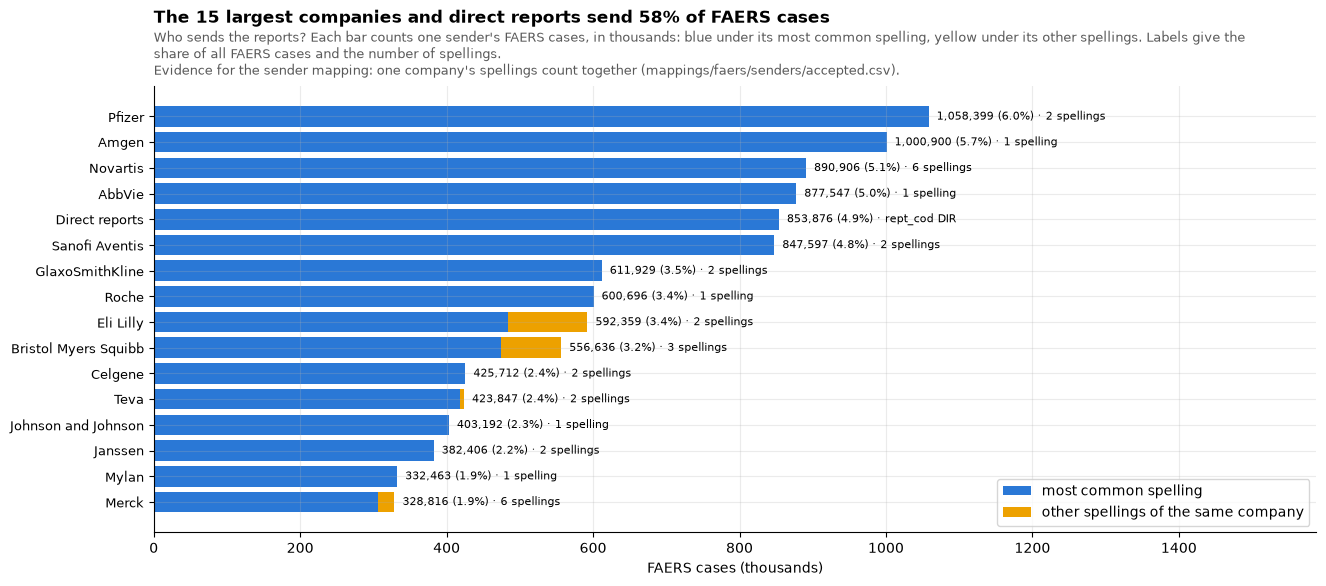

FAERS company reports: 16,731,901 cases under 2,108 spellings. The mapping holds 632 of those spellings, in 390 companies, for 16,580,511 cases (99.1%). Sender names that only say unknown, read Not given: 6,145 cases.


In [16]:
# FAERS cases only (2012Q4 on), senders counted by company through the reviewed mapping.
TOP_N = 15
vol = q("""SELECT sender_T, count(*) AS cases, count(DISTINCT mfr_sndr) AS spellings,
              count(*) FILTER (WHERE mfr_sndr <> mode_sndr) AS cases_under_another_spelling,
              min(quarter_T) AS first_q, max(quarter_T) AS last_q
            FROM (SELECT *, mode(mfr_sndr) OVER (PARTITION BY sender_T) AS mode_sndr FROM w.cases_T WHERE era_T = 'faers')
            GROUP BY 1 ORDER BY 2 DESC, 1""")
TOP = vol[~vol.sender_T.isin(["Direct reports", NG])].head(TOP_N).sender_T.tolist()
shown = vol[vol.sender_T.isin(TOP + ["Direct reports"])].copy()
n_faers = int(vol.cases.sum())
fig, ax = plt.subplots(figsize=(15, 5.8))
y = np.arange(len(shown))
ax.barh(
    y,
    (shown.cases - shown.cases_under_another_spelling) / 1e3,
    color=SERIES[0],
    label="most common spelling",
)
ax.barh(
    y,
    shown.cases_under_another_spelling / 1e3,
    left=(shown.cases - shown.cases_under_another_spelling) / 1e3,
    color=SERIES[3],
    label="other spellings of the same company",
)
for yi, r in zip(y, shown.itertuples(), strict=True):
    names = (
        "rept_cod DIR"
        if r.sender_T == "Direct reports"
        else f"{r.spellings} spelling{'s' if r.spellings > 1 else ''}"
    )
    ax.text(
        r.cases / 1e3,
        yi,
        f"  {r.cases:,} ({100 * r.cases / n_faers:.1f}%) · {names}",
        va="center",
        fontsize=8,
    )
ax.set_yticks(y)
ax.set_yticklabels(shown.sender_T, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, shown.cases.max() / 1e3 * 1.5)
ax.set_xlabel("FAERS cases (thousands)")
ax.legend(loc="lower right")
titled(
    ax,
    f"The {TOP_N} largest companies and direct reports send {100 * shown.cases.sum() / n_faers:.0f}% of FAERS cases",
    "Who sends the reports?",
    "Each bar counts one sender's FAERS cases, in thousands: blue under its most common spelling, yellow under its other spellings. "
    "Labels give the share of all FAERS cases and the number of spellings.",
    backs="Evidence for the sender mapping: one company's spellings count together (mappings/faers/senders/accepted.csv).",
    width=165,
)
plt.show()
company = one(f"""SELECT count(*), count(*) FILTER (WHERE mapped_T), count(DISTINCT mfr_sndr), count(DISTINCT mfr_sndr) FILTER (WHERE mapped_T),
                     count(DISTINCT sender_T) FILTER (WHERE mapped_T), count(*) FILTER (WHERE sender_T = '{NG}')
                 FROM w.cases_T WHERE era_T = 'faers' AND rept_cod IS DISTINCT FROM 'DIR'""")
print(
    f"FAERS company reports: {company[0]:,} cases under {company[2]:,} spellings. The mapping holds {company[3]:,} of those spellings, "
    f"in {company[4]:,} companies, for {company[1]:,} cases ({100 * company[1] / company[0]:.1f}%). "
    f"Sender names that only say unknown, read {NG}: {company[5]:,} cases."
)

### FDA's short company names

FAERS starts in 2012, after three mergers: Daiichi with Sankyo, Kyowa Hakko with Kirin's drug arm, and Swedish Orphan with Biovitrum. So the short names FDA wrote in FAERS (`DAIICHI`, `KYOWA`, `SWEDISH ORPHAN`, `BIOVITRUM`) can only be the merged firm, and their drugs say so: Enhertu, edoxaban and olmesartan; Crysvita, Nourianz and Poteligeo; Kineret and Orfadin (the last two under both Swedish Orphan names). The release now counts their cases under Daiichi Sankyo, Kyowa Kirin and Swedish Orphan Biovitrum (Sobi). Names FDA wrote before a merger stay apart: AERS `SANKYO PHARMA INC.` is still Sankyo.

The first chart counts cases (the default case set) before and after. The second shows the evidence for `BIOVITRUM`, 15,214 FAERS cases, counting with Sobi.

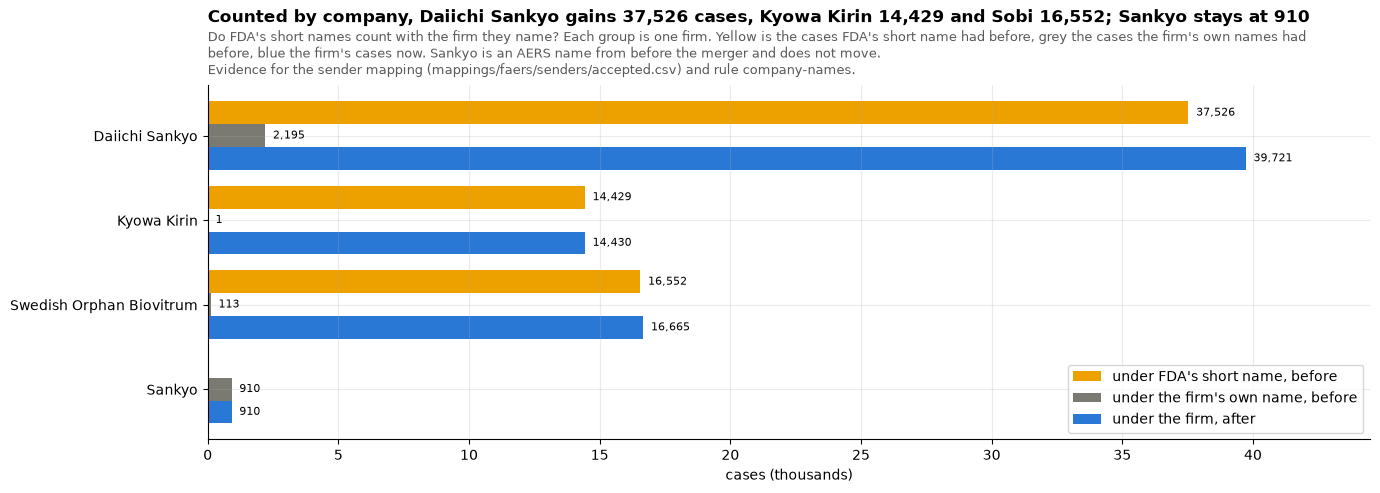

Cases under each short name, by era (default case set):


era_T,faers,legacy
mfr_sndr,,
BIOVITRUM,15214,0
DAIICHI,37523,3
KYOWA,14429,0
SWEDISH ORPHAN,1338,0


In [17]:
# FDA's short names: cases (default case set) counted under the company before and after the change.
SHORT = {  # FDA's FAERS name: (the company it counted as before, the firm it counts as now)
    "DAIICHI": ("Daiichi", "Daiichi Sankyo"),
    "KYOWA": ("Kyowa", "Kyowa Kirin"),
    "SWEDISH ORPHAN": ("Swedish Orphan", "Swedish Orphan Biovitrum"),
    "BIOVITRUM": ("Biovitrum", "Swedish Orphan Biovitrum"),
}
before_arms = " ".join(
    f"WHEN mfr_sndr = '{k}' AND company_T IS NOT NULL THEN '{b}'" for k, (b, _) in SHORT.items()
)
names = sorted({n for pair in SHORT.values() for n in pair} | {"Sankyo"})
inlist = ", ".join(f"'{n}'" for n in names)
moved = q(f"""
WITH c AS (SELECT era_T, mfr_sndr, company_T AS after_T, CASE {before_arms} ELSE company_T END AS before_T
           FROM case_latest_T WHERE dup_kept_T)
SELECT era_T, mfr_sndr, before_T, after_T, count(*) AS cases FROM c
WHERE before_T IN ({inlist}) OR after_T IN ({inlist}) GROUP BY ALL ORDER BY cases DESC""")


def cases_of(column, name):
    return int(moved.loc[moved[column] == name, "cases"].sum())


FIRMS = {f: [k for k, (_, g) in SHORT.items() if g == f] for _, f in SHORT.values()} | {
    "Sankyo": []
}
rows = []
for firm, senders in FIRMS.items():
    rows.append(
        {
            "firm": firm,
            "short_before": int(moved.loc[moved.mfr_sndr.isin(senders), "cases"].sum()),
            "firm_before": cases_of("before_T", firm),
            "firm_after": cases_of("after_T", firm),
        }
    )
chg = pd.DataFrame(rows)
chg["moved"] = chg.firm_after - chg.firm_before
fig, ax = plt.subplots(figsize=(15, 4.6))
y = np.arange(len(chg))
kinds = [
    ("short_before", "under FDA's short name, before", SERIES[3]),
    ("firm_before", "under the firm's own name, before", SERIES[6]),
    ("firm_after", "under the firm, after", SERIES[0]),
]
for i, (col, label, colour) in enumerate(kinds):
    bars = ax.barh(y + (i - 1) * 0.27, chg[col] / 1e3, 0.27, color=colour, label=label)
    for b, v in zip(bars, chg[col], strict=True):
        if v:
            ax.text(b.get_width() + 0.3, b.get_y() + 0.135, f"{v:,}", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels(chg.firm)
ax.invert_yaxis()
ax.set_xlim(0, chg[["short_before", "firm_before", "firm_after"]].max().max() / 1e3 * 1.12)
ax.set_xlabel("cases (thousands)")
ax.legend(loc="lower right")
titled(
    ax,
    f"Counted by company, Daiichi Sankyo gains {chg.moved[0]:,} cases, Kyowa Kirin {chg.moved[1]:,} and Sobi {chg.moved[2]:,}; Sankyo stays at {chg.firm_after[3]:,}",
    "Do FDA's short names count with the firm they name?",
    "Each group is one firm. Yellow is the cases FDA's short name had before, grey the cases the firm's own names had before, blue the firm's cases now. Sankyo is an AERS name from before the merger and does not move.",
    backs="Evidence for the sender mapping (mappings/faers/senders/accepted.csv) and rule company-names.",
    width=165,
)
plt.show()
era = (
    moved[moved.mfr_sndr.isin(SHORT)]
    .groupby(["mfr_sndr", "era_T"])
    .cases.sum()
    .unstack(fill_value=0)
)
print("Cases under each short name, by era (default case set):")
display(era)

### Is BIOVITRUM the same company as Sobi?

`BIOVITRUM` counts with Sobi, as `SWEDISH ORPHAN` does: Swedish Orphan and Biovitrum merged before FAERS began, so FDA's FAERS name is the merged firm's. The AERS name `BIOVITRUM AB.` (67 cases, from before the merger) stays apart. The chart puts the medicines under the FDA name `BIOVITRUM` next to those under the other Swedish Orphan names, as the evidence.

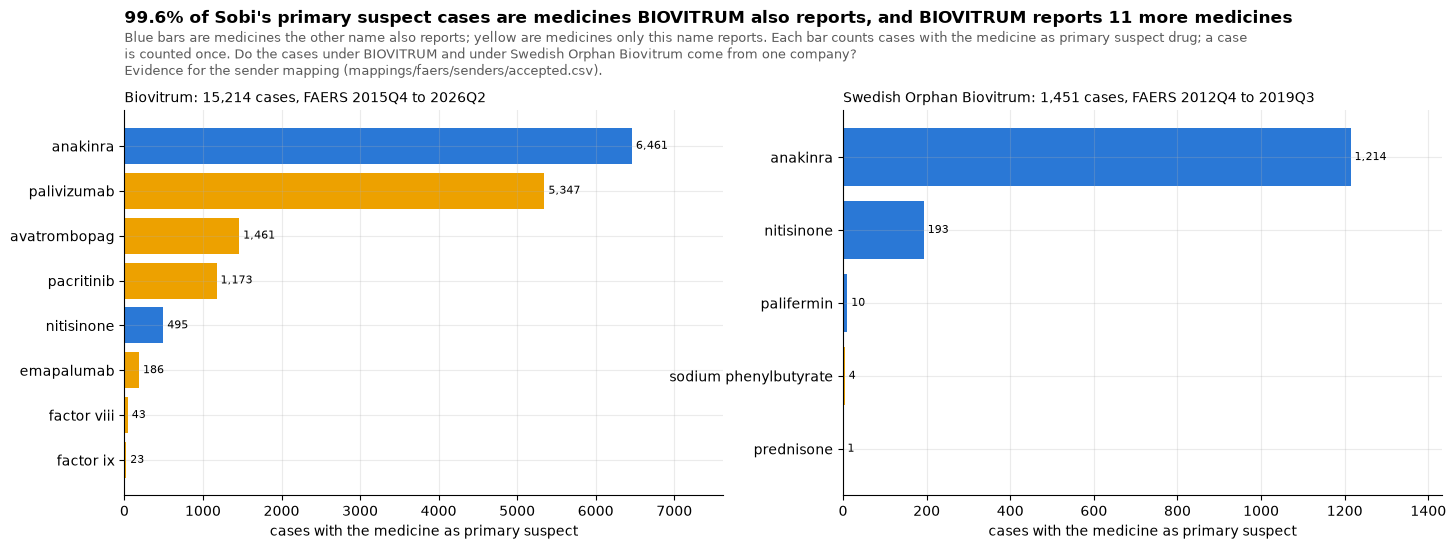

,cases,first_faers_quarter,last_quarter,aers_cases
company,,,,
Biovitrum,15214,2015q4,2026q2,0
Swedish Orphan Biovitrum,1451,2012q4,2019q3,112


Biovitrum       Swedish Orphan Biovitrum        
        product cases                  product   cases
0      anakinra  6461                 anakinra  1214.0
1   palivizumab  5347               nitisinone   193.0
2  avatrombopag  1461               palifermin    10.0
3    pacritinib  1173    sodium phenylbutyrate     4.0
4    nitisinone   495               prednisone     1.0
5    emapalumab   186                      NaN     NaN
6   factor viii    43                      NaN     NaN
7     factor ix    23                      NaN     NaN

In [18]:
# BIOVITRUM against the other Swedish Orphan names, both Sobi now: the medicines of
# their cases, primary suspect drug (PS), cases of the default case set.
def products_of(company):
    sender = "mfr_sndr = 'BIOVITRUM'" if company == "Biovitrum" else "mfr_sndr <> 'BIOVITRUM'"
    return q(f"""SELECT s.substance_T AS product, count(DISTINCT c.case_key_T) AS cases
        FROM case_latest_T c
        JOIN drug_latest_T d USING (era_T, primaryid, quarter_T)
        JOIN drug_substance_T s USING (era_T, primaryid, quarter_T, drug_seq)
        WHERE c.dup_kept_T AND c.company_T = 'Swedish Orphan Biovitrum' AND {sender} AND d.role_cod = 'PS' AND s.substance_T IS NOT NULL
        GROUP BY 1 ORDER BY 2 DESC, 1""")


span = q("""SELECT CASE WHEN mfr_sndr = 'BIOVITRUM' THEN 'Biovitrum' ELSE company_T END AS company, count(*) AS cases, min(quarter_T) FILTER (WHERE era_T = 'faers') AS first_faers_quarter, max(quarter_T) AS last_quarter,
       count(*) FILTER (WHERE era_T = 'legacy') AS aers_cases
    FROM case_latest_T WHERE dup_kept_T AND company_T = 'Swedish Orphan Biovitrum' GROUP BY 1""").set_index(
    "company"
)
bio, sobi = products_of("Biovitrum"), products_of("Swedish Orphan Biovitrum")
TOPN = 8
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, df, other, name in (
    (axes[0], bio, sobi, "Biovitrum"),
    (axes[1], sobi, bio, "Swedish Orphan Biovitrum"),
):
    t = df.head(TOPN)
    shared = t["product"].isin(other["product"])
    ax.barh(
        t["product"][::-1].str[:40],
        t.cases[::-1],
        color=[SERIES[0] if s else SERIES[3] for s in shared[::-1]],
    )
    for i, v in enumerate(t.cases[::-1]):
        ax.text(v, i, f" {v:,}", va="center", fontsize=8)
    ax.set_xlim(0, t.cases.max() * 1.18)
    ax.set_xlabel("cases with the medicine as primary suspect")
    ax.set_title(
        f"{name}: {int(span.loc[name, 'cases']):,} cases, FAERS {span.loc[name, 'first_faers_quarter'].upper()} to {span.loc[name, 'last_quarter'].upper()}",
        loc="left",
        fontsize=10,
    )
shared_sobi = sobi["product"].isin(bio["product"])
sobi_share = 100 * sobi.cases[shared_sobi].sum() / sobi.cases.sum()
extra = int((~bio["product"].isin(sobi["product"])).sum())
h = header(fig)
title(
    h,
    f"{sobi_share:.1f}% of Sobi's primary suspect cases are medicines BIOVITRUM also reports, and BIOVITRUM reports {extra} more medicines",
    "Blue bars are medicines the other name also reports; yellow are medicines only this name reports. Each bar counts cases with the medicine as primary suspect drug; a case is counted once.",
    "Do the cases under BIOVITRUM and under Swedish Orphan Biovitrum come from one company?",
    backs="Evidence for the sender mapping (mappings/faers/senders/accepted.csv).",
    width=170,
)
plt.show()
display(span)
display(
    pd.concat(
        {
            "Biovitrum": bio.head(TOPN).reset_index(drop=True),
            "Swedish Orphan Biovitrum": sobi.head(TOPN).reset_index(drop=True),
        },
        axis=1,
    )
)

**What this section shows**

- **FDA's short names, before and after.** *Shows:* cases per firm in the default case set: under FDA's short name before, under the firm's own names before, and under the firm now. *Point:* DAIICHI (37,526 cases, 37,523 of them FAERS and 3 AERS from after the merger) now counts with Daiichi Sankyo, which goes from 2,195 to 39,721; KYOWA (14,429) with Kyowa Kirin, from 1 to 14,430; SWEDISH ORPHAN (1,338) and BIOVITRUM (15,214 FAERS cases) with Swedish Orphan Biovitrum (Sobi), from 113 to 16,665. Sankyo, an AERS name from before the merger, stays apart at 910. *So what:* a count by company reads each of the three firms as one company, and a name from before the merger is not folded in.
- **BIOVITRUM beside Sobi.** *Shows:* the medicines most often primary suspect under BIOVITRUM and under Swedish Orphan Biovitrum, blue where the other name reports them too. *Point:* the two share their main medicines (anakinra and nitisinone), but the names cover different years in FAERS: the Swedish Orphan names from 2012Q4 to 2019Q3, BIOVITRUM from 2015Q4 to 2026Q2, so one begins where the other fades. *So what:* the same firm's medicines carry on under the new name, which is why BIOVITRUM counts with Sobi.

### Which senders leave which fields empty

FDA's rules ask little of a report. A report is valid when it names an identifiable patient, an identifiable reporter, a suspect drug and an adverse event; everything else is asked for "if known". So a sender who leaves age or route empty breaks no rule, and the gaps below are habits and what each sender is told, not errors.

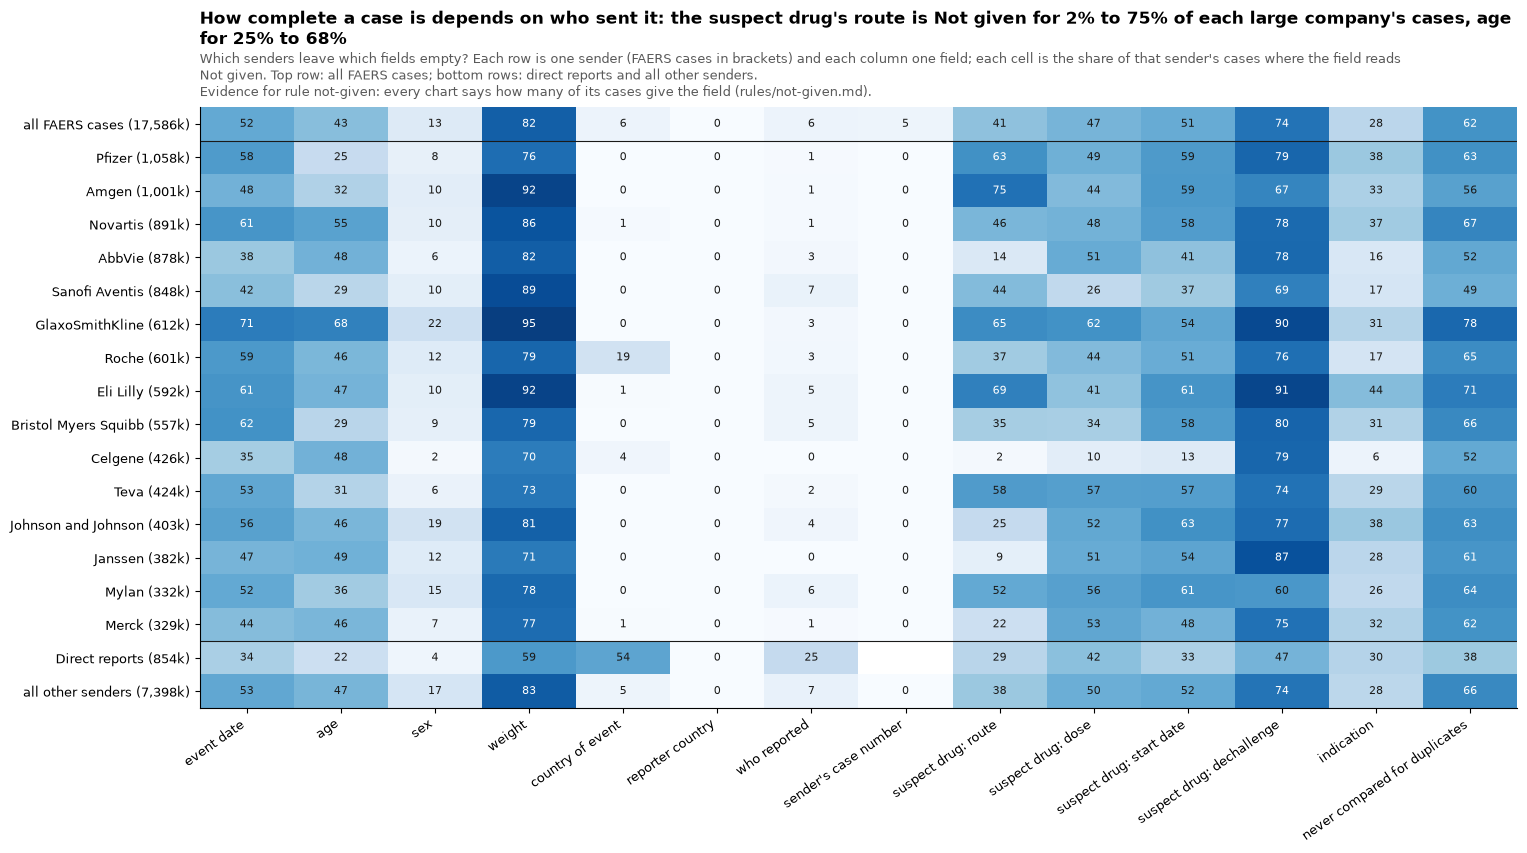

Route of the suspect drug, for the senders leaving it empty in over 60% of cases (% of their suspect drug rows): Pfizer 60% blank and 2% saying unknown; GlaxoSmithKline 39% blank and 26% saying unknown; Eli Lilly 21% blank and 49% saying unknown; Amgen 6% blank and 69% saying unknown
checked: FAERS cases with who reported blank (scratch table against case_latest_T) = 1,006,560


In [19]:
# Which senders leave which fields empty: % of each sender's FAERS cases that read Not given.
SFIELDS = {
    "event date": "event_dt_s_T IS NOT NULL",
    "age": "age_s_T IS NOT NULL",
    "sex": "sex_s_T IS NOT NULL",
    "weight": "wt_s_T IS NOT NULL",
    "country of event": "occr_country_s_T IS NOT NULL",
    "reporter country": "reporter_country_s_T IS NOT NULL",
    "who reported": "occp_s_T IS NOT NULL",
    "sender's case number": "mfr_num_s_T IS NOT NULL",
    "suspect drug: route": "coalesce(ps_route_empty_T, true)",
    "suspect drug: dose": "coalesce(ps_dose_empty_T, true)",
    "suspect drug: start date": "NOT ps_start_any_T",
    "suspect drug: dechallenge": "coalesce(ps_dechal_empty_T, true)",
    "indication": "NOT indi_known_T",
    "never compared for duplicates": "dup_key_T IS NULL OR key_not_given_T",
}
PCT = ", ".join(f'100 * avg(({c})::INT) AS "{n}"' for n, c in SFIELDS.items())
con.register("top_T", pd.DataFrame({"sender_T": TOP}))
grid_df = q(f"""SELECT CASE WHEN sender_T IN (SELECT sender_T FROM top_T) OR sender_T = 'Direct reports' THEN sender_T ELSE 'all other senders' END AS sender,
                       count(*) AS cases, {PCT} FROM w.cases_T WHERE era_T = 'faers' GROUP BY 1
                UNION ALL SELECT 'all FAERS cases', count(*), {PCT} FROM w.cases_T WHERE era_T = 'faers'""").set_index(
    "sender"
)
grid_df = grid_df.reindex(["all FAERS cases"] + TOP + ["Direct reports", "all other senders"])
grid_df.loc["Direct reports", "sender's case number"] = np.nan  # direct reports have none by design
fig, ax = plt.subplots(figsize=(17, 7.8))
g = grid_df.drop(columns="cases")
grid(g, ax, fontsize=8)
ax.set_xticklabels(g.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticklabels(
    [f"{s} ({n / 1e3:,.0f}k)" for s, n in zip(g.index, grid_df.cases, strict=True)], fontsize=9
)
ax.axhline(0.5, color="#1a1a19", lw=0.8)
ax.axhline(len(g) - 2.5, color="#1a1a19", lw=0.8)
titled(
    ax,
    f"How complete a case is depends on who sent it: the suspect drug's route is {NG} for {g.loc[TOP, 'suspect drug: route'].min():.0f}% "
    f"to {g.loc[TOP, 'suspect drug: route'].max():.0f}% of each large company's cases, age for {g.loc[TOP, 'age'].min():.0f}% to {g.loc[TOP, 'age'].max():.0f}%",
    "Which senders leave which fields empty?",
    f"Each row is one sender (FAERS cases in brackets) and each column one field; each cell is the share of that sender's cases where "
    f"the field reads {NG}. Top row: all FAERS cases; bottom rows: direct reports and all other senders.",
    backs="Evidence for rule not-given: every chart says how many of its cases give the field (rules/not-given.md).",
    width=185,
)
plt.show()
hi = g.index[g["suspect drug: route"] > 60].tolist()
con.register("hi_T", pd.DataFrame({"sender_T": hi}))
rs = q(f"""SELECT c.sender_T, 100 * avg(({blank_sql("d.route")})::INT) AS blank,
                 100 * avg((NOT {blank_sql("d.route")} AND {empty("route", "d.route")})::INT) AS unknown
          FROM drug_latest_T d JOIN w.cases_T c USING (era_T, primaryid, quarter_T)
          WHERE d.role_cod = 'PS' AND c.era_T = 'faers' AND c.sender_T IN (SELECT sender_T FROM hi_T) GROUP BY 1 ORDER BY 2 DESC""")
print(
    "Route of the suspect drug, for the senders leaving it empty in over 60% of cases (% of their suspect drug rows): "
    + "; ".join(
        f"{r.sender_T} {r.blank:.0f}% blank and {r.unknown:.0f}% saying unknown"
        for r in rs.itertuples()
    )
)
check(
    "FAERS cases with who reported blank (scratch table against case_latest_T)",
    one("SELECT count(*) FROM w.cases_T WHERE era_T = 'faers' AND occp_s_T = 'blank'")[0],
    one("SELECT count(*) FROM case_latest_T WHERE era_T = 'faers' AND occp_cod IS NULL")[0],
)

### Who reported, from 2025Q3

From 2025Q3 FDA's files say less and less often who reported a case (`occp_cod`). Is that a change in who reports, or in FDA's files? The charts split company reports from direct reports, and follow each large company quarter by quarter.

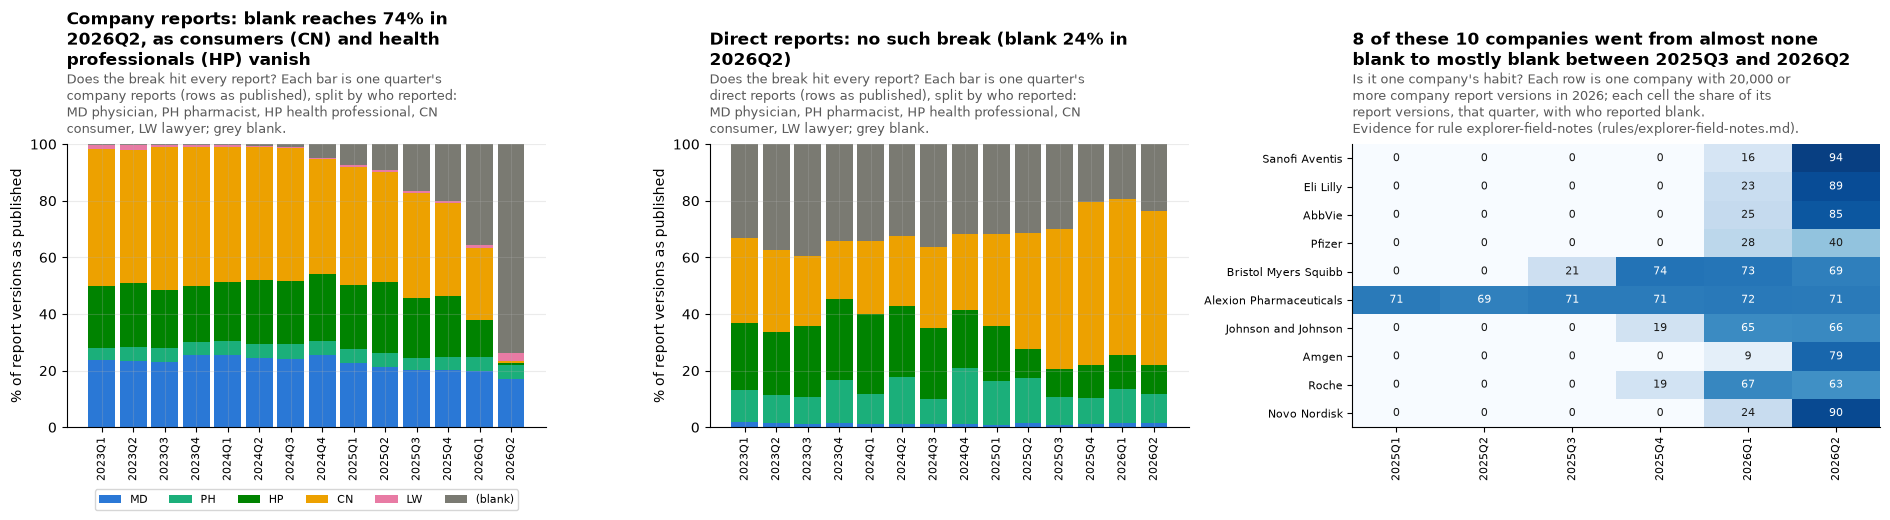

Lawyer (LW) on company reports: the company with the most in 2026, Pfizer: 2,003 LW report versions in 2025, 9,994 in 2026Q1 and Q2. The cause is not known.


FDA's notes in its zips, the quarter their current text first appeared: ASC_NTS.pdf 2024Q4; FAQs.pdf 2025Q2; Readme.pdf 2021Q4


In [20]:
# The occupation break: which codes go blank, for which reports, and from which companies. Rows as published.
occ = q("""SELECT quarter_T, rept_cod = 'DIR' AS direct, coalesce(occp_cod, '(blank)') AS occp, count(*) AS n
           FROM demo WHERE quarter_T >= '2023q1' GROUP BY ALL""")
occ["who"] = np.where(occ.direct, "direct reports", "company reports")
OCODES = ["MD", "PH", "HP", "CN", "LW", "(blank)"]
OCC_COL = [SERIES[0], SERIES[2], SERIES[5], SERIES[3], SERIES[4], KIND_COLOUR["blank"]]
by_company = q("""SELECT m.company, d.quarter_T, 100 * avg((d.occp_cod IS NULL)::INT) AS pct_blank, count(*) AS n,
                          count(*) FILTER (WHERE d.occp_cod = 'LW') AS lw
                   FROM demo d JOIN company_T m ON m.fda_value = d.mfr_sndr
                   WHERE d.quarter_T >= '2025q1' AND d.rept_cod IS DISTINCT FROM 'DIR' GROUP BY ALL""")
recent_n = by_company[by_company.quarter_T >= "2026q1"].groupby("company").n.sum()
BIG = recent_n[recent_n >= 20000].sort_values(ascending=False).index.tolist()
heat = (
    by_company[by_company.company.isin(BIG)]
    .pivot(index="company", columns="quarter_T", values="pct_blank")
    .reindex(BIG)
)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, who in zip(axes[:2], ["company reports", "direct reports"], strict=True):
    p = (
        occ[occ.who == who]
        .pivot_table(index="quarter_T", columns="occp", values="n", aggfunc="sum")
        .reindex(columns=OCODES)
        .fillna(0)
    )
    p = 100 * p.div(p.sum(axis=1), axis=0)
    bottom = np.zeros(len(p))
    for c, col in zip(OCODES, OCC_COL, strict=True):
        ax.bar(range(len(p)), p[c], bottom=bottom, color=col, label=c, width=0.85)
        bottom += p[c].values
    ax.set_xticks(range(len(p)))
    ax.set_xticklabels([x.upper() for x in p.index], rotation=90, fontsize=8)
    ax.set_ylim(0, 100)
    ax.set_ylabel("% of report versions as published")
    claim = (
        f"Company reports: blank reaches {p['(blank)'].iloc[-1]:.0f}% in {p.index[-1].upper()}, as consumers (CN) and health professionals (HP) vanish"
        if who == "company reports"
        else f"Direct reports: no such break (blank {p['(blank)'].iloc[-1]:.0f}% in {p.index[-1].upper()})"
    )
    titled(
        ax,
        claim,
        "Does the break hit every report?",
        f"Each bar is one quarter's {who} (rows as published), split by who reported: MD physician, PH pharmacist, HP health "
        "professional, CN consumer, LW lawyer; grey blank.",
        width=60,
    )
axes[0].legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
grid(heat.rename(columns=str.upper), axes[2], fontsize=8)
SWITCHED = int(((heat.iloc[:, 0] < 10) & (heat.iloc[:, -1] > 50)).sum())
titled(
    axes[2],
    f"{SWITCHED} of these {len(BIG)} companies went from almost none blank to mostly blank between 2025Q3 and 2026Q2",
    "Is it one company's habit?",
    "Each row is one company with 20,000 or more company report versions in 2026; each cell the share of its report versions, "
    "that quarter, with who reported blank.",
    backs="Evidence for rule explorer-field-notes (rules/explorer-field-notes.md).",
    width=66,
)
plt.tight_layout()
plt.show()
lw = (
    by_company[by_company.quarter_T >= "2026q1"]
    .groupby("company")
    .lw.sum()
    .sort_values(ascending=False)
)
lw_before = by_company[by_company.quarter_T < "2026q1"].groupby("company").lw.sum()
print(
    f"Lawyer (LW) on company reports: the company with the most in 2026, {lw.index[0]}: {int(lw_before.get(lw.index[0], 0)):,} "
    f"LW report versions in 2025, {int(lw.iloc[0]):,} in 2026Q1 and Q2. The cause is not known."
)


def note_versions(folder):
    """For each of FDA's notes inside its zips, the first quarter of its current content, over the FAERS quarters."""
    since = {}
    for qz in discover(folder):
        if qz.name < "2012q4":
            continue
        with zipfile.ZipFile(qz.path) as z:
            for n in z.namelist():
                base = Path(n).name
                if base.lower() in {"readme.pdf", "asc_nts.pdf", "faqs.pdf"}:
                    digest = hashlib.sha256(z.read(n)).hexdigest()
                    if since.get(base, ("", ""))[0] != digest:
                        since[base] = (digest, qz.name)
    return {base: quarter for base, (_, quarter) in since.items()}


if ZIPS:
    print(
        "FDA's notes in its zips, the quarter their current text first appeared: "
        + "; ".join(
            f"{b} {qq.upper()}" for b, qq in sorted(note_versions(Path(ZIPS).expanduser()).items())
        )
    )

**What the break is.** From 2025Q3, company by company, FDA's files stop saying who reported a company report. The codes that vanish are consumer (`CN`) and health professional (`HP`); physician and pharmacist hold. Most large companies switch within a quarter or two, from almost no blanks to mostly blank, one after another between 2025Q3 and 2026Q2. Direct reports, which people send FDA themselves, show no such break.

**Why it is not real.** People did not stop being consumers or nurses in one quarter per company, and the reports they send FDA directly did not change. Something changed in how company reports reach FDA's files. At the same time one company's lawyer (`LW`) reports rose from 2,003 in 2025 to 9,994 in the first half of 2026; the cause is not known.

**A likely explanation, not proven.** FDA has accepted reports in the ICH E2B(R3) format since January 2024 and planned to require it for postmarketing individual case safety reports from 1 April 2026; a notice in the Federal Register (2026-06660, 6 April 2026) moved that to 1 October 2026. Companies move their reporting to the new format one after another, and the break follows companies, one after another, in the year before that date: the timing fits a conversion of E2B(R3) reports that loses who reported. FDA's own notes inside its zips say nothing of it: as the cell above shows, the readme has not changed in years, and the file notes and the FAQ last changed before the break. Nothing in Open Altio depends on the cause: the explorer shows the field's note from 2025Q3 whatever it is.

**What section 4 shows**

- **Who sends the reports.** *Shows:* FAERS cases per company, its spellings grouped, and direct reports. *Point:* the 15 largest companies and direct reports send 58% of FAERS cases, many under several spellings. *So what:* counting by sender needs the mapping; it now counts 99.1% of company-sent cases under 369 companies.
- **Which senders leave which fields empty.** *Shows:* for each large sender, the share of its cases where each field reads Not given. *Point:* the suspect drug's route is Not given for 2% to 75% of each large company's cases, age for 25% to 68%; one company leaves a missing route blank (Pfizer, 60% blank, 2% unknown), others write unknown (Amgen, 6% and 69%); direct reports give event date and age more often than most companies. *So what:* how complete a product's cases are depends on who reports it, so each chart says its coverage, and each sender's gaps are within FDA's rules.
- **Who reported, company reports.** *Shows:* who reported on company reports, quarter by quarter. *Point:* blank reaches 74% in 2026Q2 as consumers and health professionals vanish. *So what:* a count by who reported after mid-2025 measures FDA's files, so the explorer notes the field from 2025Q3.
- **Who reported, direct reports.** *Shows:* the same on direct reports. *Point:* no break. *So what:* the change is in how company reports reach the files, not in who reports.
- **Company by company.** *Shows:* each large company's share of reports with who reported blank, by quarter. *Point:* 8 of the 10 largest went from almost none blank to mostly blank, most within a quarter or two; Pfizer reached 40%, and Alexion was already 71% blank. *So what:* the switch follows companies, as a change of report format would; it is not one sender's habit.

## 5. What emptiness does to the rules

Each rule that reads these fields, on cases (the latest version of each case). "Usable" is what the rule can use. "Given, unusable" means the sender wrote something the rule cannot read: an age with no unit, a partial date where a full one is needed, a sex code other than F or M. The rules themselves (units, caps, partial dates) are separate choices; here only the effect of emptiness.

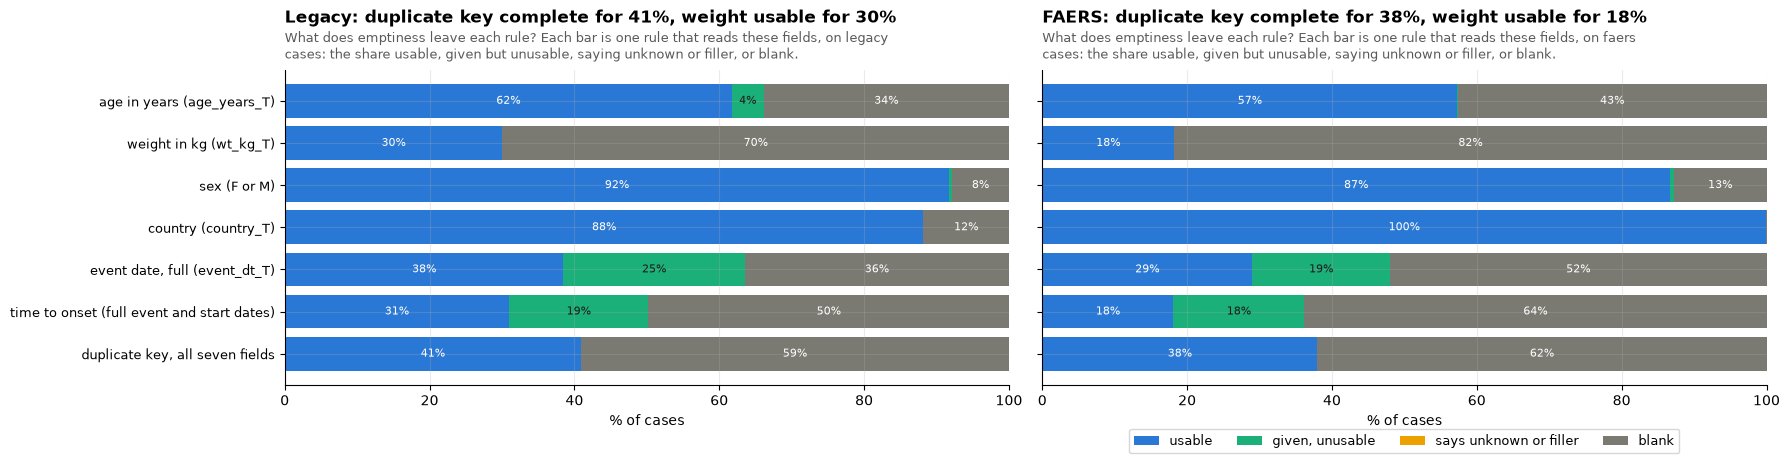

Ages given but unusable: 143,910 with no unit (130,671 of them legacy) and 844 unreadable (a unit or a number the age rule does not read).


checked: cases with a usable weight in kg = 4,105,634
checked: cases with a full event date = 6,253,240


state,usable,"given, unusable",says unknown or filler,blank,all cases
rule,,,,,
age in years (age_years_T),11928677,144754,15,8515083,20588529
weight in kg (wt_kg_T),4105634,1069,964,16480862,20588529
sex (F or M),17992140,108097,0,2488292,20588529
country (country_T),20220767,0,0,367762,20588529
"event date, full (event_dt_T)",6253240,4096104,0,10239185,20588529
time to onset (full event and start dates),4114901,3752140,0,12721488,20588529
"duplicate key, all seven fields",7903804,0,0,12684725,20588529


In [21]:
# What each rule that reads these fields gets, per case (the latest version of each case).
AGE_UNITS = "('YR', 'DEC', 'MON', 'WK', 'DY', 'HR')"  # the units derive.py reads
WT_UNITS = "('KG', 'KGS', 'LBS', 'GMS')"
# a weight over the rule's limit, once read in kilograms, is no weight (rules/weight-in-kg.md)
WT_KG = (
    "CASE upper(trim(wt_cod)) "
    + " ".join(
        f"WHEN '{u}' THEN TRY_CAST(trim(wt) AS DOUBLE) * {a} / {b}"
        for u, (a, b) in rulebook.value("weight-in-kg", "units").items()
    )
    + " END"
)
MAX_KG = rulebook.value("weight-in-kg", "max_kg")


def NUM(c):
    # the number the release reads (src/open_altio/faers/dates.py): digits, a point, `5.` and `.9` too
    return f"regexp_full_match(trim({c}), '[0-9]+\\.?[0-9]*|\\.[0-9]+')"


AGE_STATE = f"""CASE WHEN age_s_T = 'blank' THEN 'blank' WHEN age_s_T IS NOT NULL THEN 'says unknown or filler'
     WHEN age_cod_s_T IS NOT NULL THEN 'given, no unit' WHEN age_cod NOT IN {AGE_UNITS} OR NOT {NUM("age")} THEN 'given, unreadable'
     ELSE 'usable' END"""
RULES = {
    "age in years (age_years_T)": f"CASE WHEN ({AGE_STATE}) LIKE 'given%' THEN 'given, unusable' ELSE ({AGE_STATE}) END",
    "weight in kg (wt_kg_T)": f"""CASE WHEN wt_s_T = 'blank' THEN 'blank' WHEN wt_s_T IS NOT NULL THEN 'says unknown or filler'
     WHEN wt_cod_s_T IS NOT NULL OR wt_cod NOT IN {WT_UNITS} OR NOT {NUM("wt")} OR {WT_KG} > {MAX_KG} OR {WT_KG} <= 0 THEN 'given, unusable' ELSE 'usable' END""",
    "sex (F or M)": "CASE WHEN sex_s_T = 'blank' THEN 'blank' WHEN sex_s_T IS NOT NULL THEN 'says unknown or filler' WHEN sex IN ('F', 'M') THEN 'usable' ELSE 'given, unusable' END",
    "country (country_T)": "CASE WHEN country_s_T = 'blank' THEN 'blank' WHEN country_s_T IS NOT NULL THEN 'says unknown or filler' ELSE 'usable' END",
    "event date, full (event_dt_T)": "CASE WHEN event_dt_s_T = 'blank' THEN 'blank' WHEN event_dt_T IS NOT NULL THEN 'usable' ELSE 'given, unusable' END",
    "time to onset (full event and start dates)": """CASE WHEN event_dt_T IS NOT NULL AND ps_start_full_T THEN 'usable'
     WHEN event_dt_s_T = 'blank' OR NOT ps_start_any_T THEN 'blank' ELSE 'given, unusable' END""",
    "duplicate key, all seven fields": """CASE WHEN dup_key_T IS NOT NULL AND NOT key_not_given_T THEN 'usable'
     WHEN dup_key_T IS NOT NULL THEN 'says unknown or filler' ELSE 'blank' END""",
}
STATES = ["usable", "given, unusable", "says unknown or filler", "blank"]
ST_COL = [SERIES[0], SERIES[2], SERIES[3], KIND_COLOUR["blank"]]
RULE_STATES = q(
    " UNION ALL ".join(
        f"SELECT '{n}' AS rule, era_T, {s} AS state, count(*) AS n FROM w.cases_T GROUP BY ALL"
        for n, s in RULES.items()
    )
)
fig, axes = plt.subplots(1, 2, figsize=(18, 4.8), sharey=True)
ERA_NAME = {"legacy": "Legacy", "faers": "FAERS"}
for ax, era in zip(axes, ["legacy", "faers"], strict=True):
    p = (
        RULE_STATES[RULE_STATES.era_T == era]
        .pivot_table(index="rule", columns="state", values="n", aggfunc="sum")
        .reindex(index=list(RULES), columns=STATES)
        .fillna(0)
    )
    p = 100 * p.div(p.sum(axis=1), axis=0)
    left = np.zeros(len(p))
    for s, col in zip(STATES, ST_COL, strict=True):
        bars = ax.barh(range(len(p)), p[s], left=left, color=col, label=s)
        for b, v in zip(bars, p[s], strict=True):
            if v >= 4:
                ax.text(
                    b.get_x() + v / 2,
                    b.get_y() + b.get_height() / 2,
                    f"{v:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if s in ("usable", "blank") else "#1a1a19",
                )
        left += p[s].values
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of cases")
    titled(
        ax,
        f"{ERA_NAME[era]}: duplicate key complete for {p.loc['duplicate key, all seven fields', 'usable']:.0f}%, "
        f"weight usable for {p.loc['weight in kg (wt_kg_T)', 'usable']:.0f}%",
        "What does emptiness leave each rule?",
        f"Each bar is one rule that reads these fields, on {era} cases: the share usable, given but unusable, saying unknown or filler, "
        "or blank.",
        width=92,
    )
axes[0].set_yticks(range(len(RULES)))
axes[0].set_yticklabels(list(RULES), fontsize=9)
axes[0].invert_yaxis()
axes[1].legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)
plt.tight_layout()
plt.show()
tot = (
    RULE_STATES.pivot_table(index="rule", columns="state", values="n", aggfunc="sum")
    .reindex(index=list(RULES), columns=STATES)
    .fillna(0)
    .astype(int)
)
tot["all cases"] = tot.sum(axis=1)
AGE_SPLIT = (
    q(f"SELECT {AGE_STATE} AS state, era_T, count(*) AS n FROM w.cases_T GROUP BY ALL")
    .pivot_table(index="state", columns="era_T", values="n", aggfunc="sum")
    .fillna(0)
    .astype(int)
)
print(
    f"Ages given but unusable: {AGE_SPLIT.loc['given, no unit'].sum():,} with no unit ({AGE_SPLIT.loc['given, no unit', 'legacy']:,} of them legacy) "
    f"and {AGE_SPLIT.loc['given, unreadable'].sum():,} unreadable (a unit or a number the age rule does not read)."
)
check(
    "cases with a usable weight in kg",
    int(tot.loc["weight in kg (wt_kg_T)", "usable"]),
    one(
        f"SELECT count(*) FROM case_latest_T WHERE wt_kg_T IS NOT NULL AND NOT {empty('wt')} AND NOT {empty('wt_cod')}"
    )[0],
)
check(
    "cases with a full event date",
    int(tot.loc["event date, full (event_dt_T)", "usable"]),
    one("SELECT count(event_dt_T) FROM case_latest_T")[0],
)
tot

**Time to onset, and the padded dates.** Legacy cases give a time to onset (a full event date and a full start date for the suspect drug) far more often than FAERS cases. Section 1 showed that legacy AERS padded a date known only to the month or year to the 1st, which makes a full date that is not a real day. How much of legacy's lead is padding?

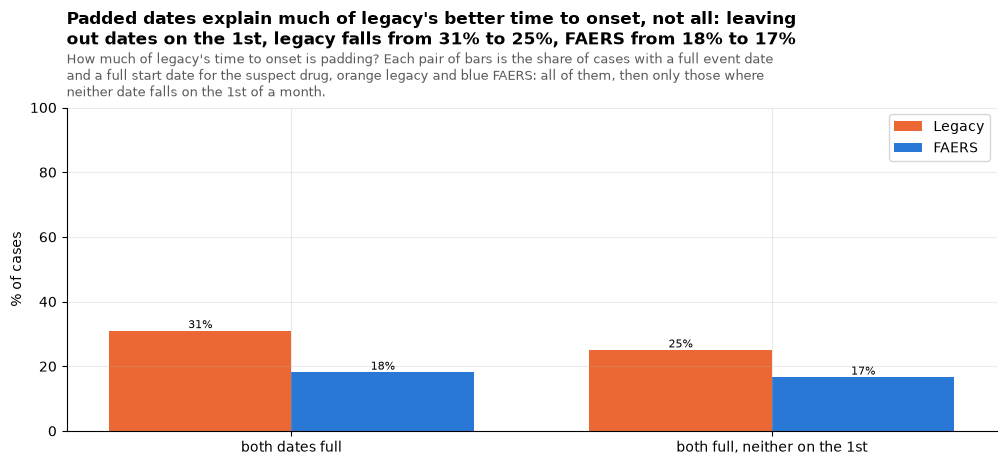

In [22]:
TTO = (
    q("""SELECT era_T, count(*) AS cases,
                  count(*) FILTER (WHERE event_dt_T IS NOT NULL AND ps_start_full_T) AS both_full,
                  count(*) FILTER (WHERE event_dt_T IS NOT NULL AND right(event_dt, 2) <> '01' AND ps_start_full_not_1st_T) AS neither_on_1st
           FROM w.cases_T GROUP BY 1""")
    .set_index("era_T")
    .reindex(["legacy", "faers"])
)
TTO_PCT = pd.DataFrame(
    {
        "both dates full": 100 * TTO.both_full / TTO.cases,
        "both full, neither on the 1st": 100 * TTO.neither_on_1st / TTO.cases,
    }
)
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(2)
w = 0.38
for i, era in enumerate(["legacy", "faers"]):
    label_bars(
        ax,
        ax.bar(x + (i - 0.5) * w, TTO_PCT.loc[era], w, color=ERA[era], label=ERA_NAME[era]),
        "{:.0f}%",
    )
ax.set_xticks(x)
ax.set_xticklabels(TTO_PCT.columns)
ax.set_ylabel("% of cases")
ax.set_ylim(0, 100)
ax.legend()
titled(
    ax,
    f"Padded dates explain much of legacy's better time to onset, not all: leaving out dates on the 1st, legacy falls from "
    f"{TTO_PCT.loc['legacy'].iloc[0]:.0f}% to {TTO_PCT.loc['legacy'].iloc[1]:.0f}%, FAERS from {TTO_PCT.loc['faers'].iloc[0]:.0f}% "
    f"to {TTO_PCT.loc['faers'].iloc[1]:.0f}%",
    "How much of legacy's time to onset is padding?",
    "Each pair of bars is the share of cases with a full event date and a full start date for the suspect drug, orange legacy and "
    "blue FAERS: all of them, then only those where neither date falls on the 1st of a month.",
    width=110,
)
plt.show()

### The duplicate key, with Not given never compared

Open Altio's duplicate key (the AEOLUS rule, rule `dedup-default`) compares seven fields: event date, age, age unit, sex, country, the drugs and the reactions. A case with any of them empty is never compared. Since the empty state became one, a value that reads Not given (sex `UNK` or `NS`, `COUNTRY NOT SPECIFIED`, an age of `999`) is never compared either, where before two cases could match on it. The release read here was built before that change, so the cell works out the key with it from the release's own fields, before and after.

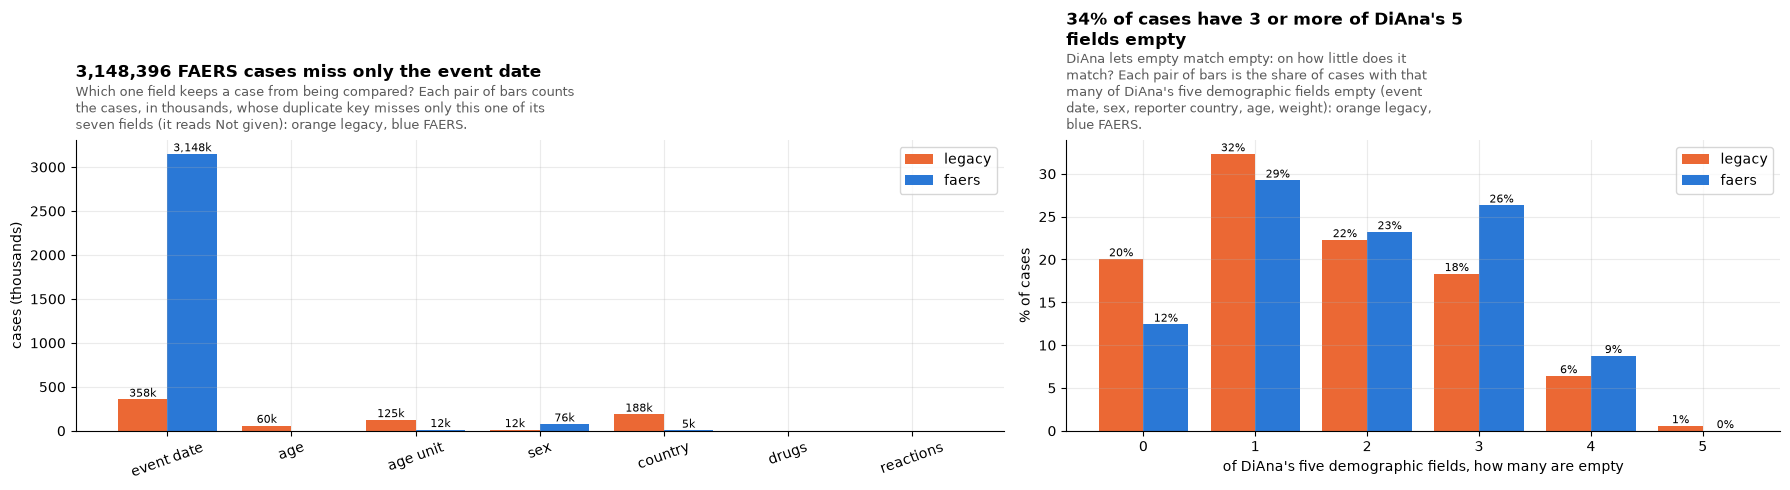

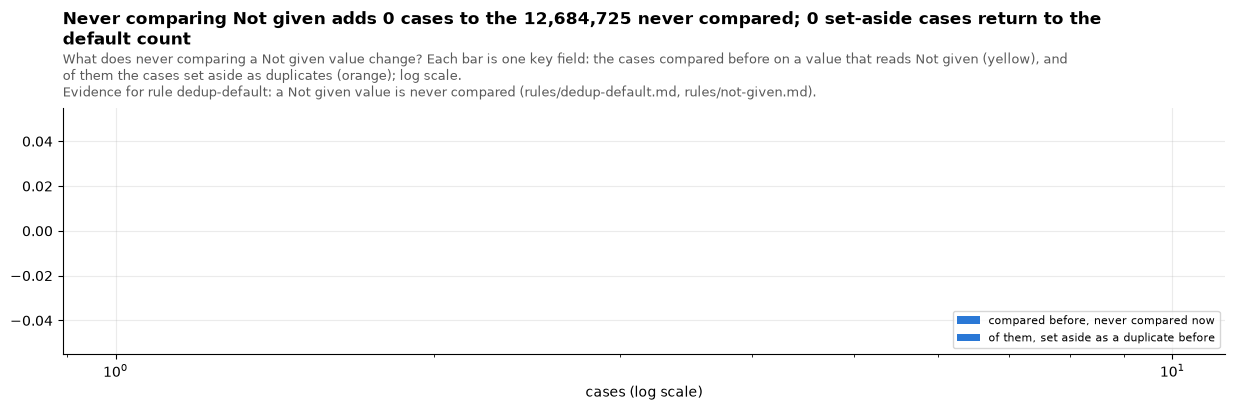

checked: cases never compared before (the release's own key) = 12,684,725


checked: cases never compared after: no key, or a key field reads Not given = 12,684,725
Never compared: 12,684,725 before (61.6% of cases), 12,684,725 after (61.6%). Set aside before and never compared now: 0; 0 of them not grouped by the manufacturer number either, so they return to the default count.
Cases with three or more of DiAna's five demographic fields empty: 6,933,367 (34%).


,compared_before,set_aside_before
field,,


In [23]:
# The duplicate key: seven fields, none of them Not given (rules/dedup-default.md, rules/not-given.md).
KEY = {
    "event date": "event_dt_s_T IS NOT NULL",
    "age": "age_s_T IS NOT NULL",
    "age unit": "age_cod_s_T IS NOT NULL",
    "sex": "sex_s_T IS NOT NULL",
    "country": "country_s_T IS NOT NULL",
    "drugs": "d.has_drug IS NULL",
    "reactions": "r.has_reac IS NULL",
}
sets = """LEFT JOIN (SELECT DISTINCT era_T, primaryid, quarter_T, true AS has_drug FROM drug_latest_T WHERE drugname_norm_T IS NOT NULL) d USING (era_T, primaryid, quarter_T)
          LEFT JOIN (SELECT DISTINCT era_T, primaryid, quarter_T, true AS has_reac FROM reac_latest_T WHERE pt IS NOT NULL) r USING (era_T, primaryid, quarter_T)"""
n_missing = " + ".join(f"({c})::INT" for c in KEY.values())
only = q(f"""SELECT era_T, {", ".join(f'count(*) FILTER (WHERE {n_missing} = 1 AND {c}) AS "{n}"' for n, c in KEY.items())},
                 count(*) FILTER (WHERE {n_missing} = 0) AS complete, count(*) AS cases
             FROM w.cases_T c {sets} GROUP BY 1""").set_index("era_T")
NUMBER_RULES = [
    "manufacturer_number",
    "manufacturer_number_country_code",
]  # the key's other route into a group
BEFORE, AFTER, NEWLY, ASIDE, BACK = one(f"""
SELECT count(*) FILTER (WHERE dup_key_T IS NULL),
       count(*) FILTER (WHERE dup_key_T IS NULL OR key_not_given_T),
       count(*) FILTER (WHERE dup_key_T IS NOT NULL AND key_not_given_T),
       count(*) FILTER (WHERE dup_key_T IS NOT NULL AND key_not_given_T AND NOT dup_kept_T),
       count(*) FILTER (WHERE dup_key_T IS NOT NULL AND key_not_given_T AND NOT dup_kept_T
                        AND NOT list_has_any(dup_rule_T, {NUMBER_RULES}))
FROM w.cases_T""")
moved = q(
    " UNION ALL ".join(
        f"""SELECT '{n}' AS field, count(*) AS compared_before, count(*) FILTER (WHERE NOT dup_kept_T) AS set_aside_before
        FROM w.cases_T WHERE dup_key_T IS NOT NULL AND {c}"""
        for n, c in KEY.items()
        if n not in ("drugs", "reactions")
    )
).set_index("field")
moved = moved[moved.compared_before > 0]
# DiAna's rule-based key: five demographic fields, and empty matches empty (notebook 04). How many of the five are empty?
DIANA = {
    "event date": "event_dt_s_T IS NOT NULL",
    "sex (F or M)": "sex IS NULL OR sex NOT IN ('F', 'M')",
    "reporter country": "reporter_country_s_T IS NOT NULL",
    "age": f"age_s_T IS NOT NULL OR NOT {NUM('age')}",
    "weight": f"wt_s_T IS NOT NULL OR NOT {NUM('wt')}",
}
k5 = " + ".join(f"({c})::INT" for c in DIANA.values())
dia = (
    q(f"SELECT era_T, {k5} AS empty_of_five, count(*) AS cases FROM w.cases_T GROUP BY ALL")
    .pivot(index="empty_of_five", columns="era_T", values="cases")
    .fillna(0)
)
fig, (a1, a3) = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1.3, 1]})
o = only.drop(columns=["complete", "cases"]).T
x = np.arange(len(o))
w = 0.4
for i, era in enumerate(["legacy", "faers"]):
    bars = a1.bar(x + (i - 0.5) * w, o[era] / 1e3, w, color=ERA[era], label=era)
    label_bars(a1, [b for b in bars if b.get_height() >= 1], "{:,.0f}k")
a1.set_xticks(x)
a1.set_xticklabels(o.index, rotation=20)
a1.set_ylabel("cases (thousands)")
a1.legend()
titled(
    a1,
    f"{int(only.loc['faers', 'event date']):,} FAERS cases miss only the event date",
    "Which one field keeps a case from being compared?",
    f"Each pair of bars counts the cases, in thousands, whose duplicate key misses only this one of its seven fields (it reads {NG}): "
    "orange legacy, blue FAERS.",
    width=74,
)
d = 100 * dia / dia.sum()
for i, era in enumerate(["legacy", "faers"]):
    label_bars(a3, a3.bar(d.index + (i - 0.5) * w, d[era], w, color=ERA[era], label=era), "{:.0f}%")
a3.set_xlabel("of DiAna's five demographic fields, how many are empty")
a3.set_ylabel("% of cases")
a3.legend()
titled(
    a3,
    f"{100 * dia[dia.index >= 3].values.sum() / dia.values.sum():.0f}% of cases have 3 or more of DiAna's 5 fields empty",
    "DiAna lets empty match empty: on how little does it match?",
    "Each pair of bars is the share of cases with that many of DiAna's five demographic fields empty (event date, sex, reporter "
    "country, age, weight): orange legacy, blue FAERS.",
    width=57,
)
plt.tight_layout()
plt.show()
fig, a2 = plt.subplots(figsize=(15, 3.2))
for col, colour, label in [
    ("compared_before", SERIES[3], "compared before, never compared now"),
    ("set_aside_before", SERIES[1], "of them, set aside as a duplicate before"),
]:
    bars = a2.barh(moved.index, moved[col].where(moved[col] > 0), color=colour, label=label)
    label_bars(a2, [b for b in bars if b.get_width() > 0], horizontal=True)
a2.set_xscale("log")
a2.set_xlabel("cases (log scale)")
a2.legend(fontsize=8, loc="lower right")
titled(
    a2,
    f"Never comparing {NG} adds {NEWLY:,} cases to the {BEFORE:,} never compared; {BACK:,} set-aside cases return to the default count",
    "What does never comparing a Not given value change?",
    f"Each bar is one key field: the cases compared before on a value that reads {NG} (yellow), and of them the cases set aside as "
    "duplicates (orange); log scale.",
    backs="Evidence for rule dedup-default: a Not given value is never compared (rules/dedup-default.md, rules/not-given.md).",
    width=150,
)
plt.show()
check(
    "cases never compared before (the release's own key)",
    BEFORE,
    one("SELECT count(*) FROM case_dup_T WHERE dup_key_T IS NULL")[0],
)
check(
    "cases never compared after: no key, or a key field reads Not given",
    AFTER,
    one(
        "SELECT count(*) FROM case_latest_T c JOIN case_dup_T k USING (era_T, case_key_T) WHERE k.dup_key_T IS NULL OR "
        + "("
        + " OR ".join(not_given.check(f, f"c.{f}") for f in KEY_FIELDS)
        + ")"
    )[0],
)
print(
    f"Never compared: {BEFORE:,} before ({100 * BEFORE / N_CASES:.1f}% of cases), {AFTER:,} after ({100 * AFTER / N_CASES:.1f}%). "
    f"Set aside before and never compared now: {ASIDE:,}; {BACK:,} of them not grouped by the manufacturer number either, so they "
    "return to the default count."
)
three_plus = int(dia[dia.index >= 3].sum().sum())
print(
    f"Cases with three or more of DiAna's five demographic fields empty: {three_plus:,} ({100 * three_plus / N_CASES:.0f}%)."
)
moved

**What section 5 shows**

- **What emptiness leaves each rule, legacy and FAERS.** *Shows:* for each rule that reads these fields, the share of cases it can use. *Point:* age is usable for 58% of cases and weight for 20%; 143,910 ages are given with no unit and 856 are unreadable, which today read as no age; the duplicate key is complete for 38% of FAERS cases. *So what:* every analysis by age, weight or date rests on part of the cases, which the coverage line says.
- **Time to onset and padded dates.** *Shows:* the cases with both dates full, then only those where neither falls on the 1st. *Point:* legacy falls from 50% to 25%, FAERS from 21% to 17%: padding explains much of legacy's lead, not all. *So what:* a legacy time to onset is mostly, not only, longer on paper; reading the dates' precision matters more than the era.
- **Which one field keeps a case from being compared.** *Shows:* the cases whose key misses exactly one field. *Point:* 3,143,886 FAERS cases miss only the event date; every other single field is far behind. *So what:* the event date decides most of what the duplicate key can see.
- **DiAna's five fields.** *Shows:* how many of DiAna's five demographic fields each case leaves empty. *Point:* 34% of cases have three or more empty, and DiAna still compares them, matching empty with empty. *So what:* the 12.7 million never compared is our own rule's count; DiAna's risk is the opposite one, false matches (notebook 04).
- **What never comparing Not given changes.** *Shows:* per key field, the cases compared before on a value that reads Not given, and those set aside. *Point:* never compared rises from 12,673,308 to 12,684,488 (61.6% of cases), and 120 set-aside cases return to the default count. *So what:* the change is small and makes the count of never compared cases honest.

## What was decided

Each decision lives in a rule file or a reviewed mapping, with its test and its docs.

**One empty state, Not given, everywhere** (`rules/not-given.md`). A field that is blank, says unknown, is a filler, or is a column FDA's file did not have that quarter reads **Not given** in the explorer's filters, charts, case window, the statistics' strata and the clean download columns; FDA's own value is always shown beside it, and sex reads Female, Male, Not given. Senders write blank or unknown for the same thing by habit (among the senders leaving the suspect drug's route empty most often, one mostly writes blank, others unknown), and in 2026Q2 FDA's own files turned route `UNKNOWN` into blank (27% to 15% unknown, 39% to 62% blank, 2025Q4 to 2026Q2), so telling the two apart would draw trends that are not real.

**What reads Not given: one checked list per field** (`rules/not-given.md`). Coded unknowns, unknown words in free text, drug names that name no drug, and fillers: 87.5 million values say unknown and 8.7 million are fillers on the grain users see. Kept as real: an age of 0, the countries `NI` and `NA`, dechallenge and rechallenge `D`. Three exceptions: rechallenge `D` from 2012Q4 to 2015Q3 is a filler (sent again later, 96.3% came back blank and 41 stayed `D`); `to_mfr` is read only on direct reports (1,817,362 company reports say `N` from 2014Q1 to 2015Q3, a filler); and a sender name made only of unknown words and company words (`Unknown Manufacturer`, `UNKNOWN`) is no company. `GENERIC` is no unknown word: Generics [UK] Ltd is a company.

**Every chart says its coverage** (`rules/not-given.md`). A chart that reads a field that can be empty says under its title how many of its cases give the field ("Age given for 51% of these cases" for Ozempic), keeps one grey Not given bar apart, and follows the reader's filters, so a reader knows whether what they see is representative.

**Notes where FDA's own files changed** (`rules/explorer-field-notes.md`). One list, shown under the field's chart and beside its filter when the dates chosen take in those quarters: who reported from 2025Q3, route and dose form from 2026Q1, dechallenge and rechallenge from 2012Q4 to 2016Q2. Nothing depends on FDA's reason, so no question is put to FDA.

**The duplicate key never compares a Not given value** (`rules/dedup-default.md`). Cases never compared rise from 12,673,308 to 12,684,488 (61.6%), and 120 cases set aside before return to the default count.

**Nearly empty fields are not filters.** Death date, `drug_rec_act`, expiry date, cumulative dose, and legacy's `image`, `confid` and `foll_seq` are not offered as filters; nothing is taken from the downloads or SQL, where people look deeper, and the methods page shows every field's coverage by era. `to_mfr` is no longer nearly empty: read on direct reports only, it is filled on 96% of them.

**Senders counted by company** (`mappings/faers/senders/accepted.csv`). 1,113 spellings in 475 companies, 99.1% of FAERS and 98.2% of AERS company-sent cases, reviewed: spellings of one company only, never rolled up to an owner, and renamed companies and differently named arms kept apart. A company filter and a "by company" chart use the grouped name; FDA's `mfr_sndr` stays everywhere. Counting by owner needs dates of ownership and is left for later.

## Methods-page cards from this notebook

The cards below are computed by the same functions the release build calls (`src/open_altio/faers/insights/cards/empty_fields.py`), so the chart data on the methods page is reproducible from this code. Each card is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT`) for checking; the release carries them in `methods.json`.

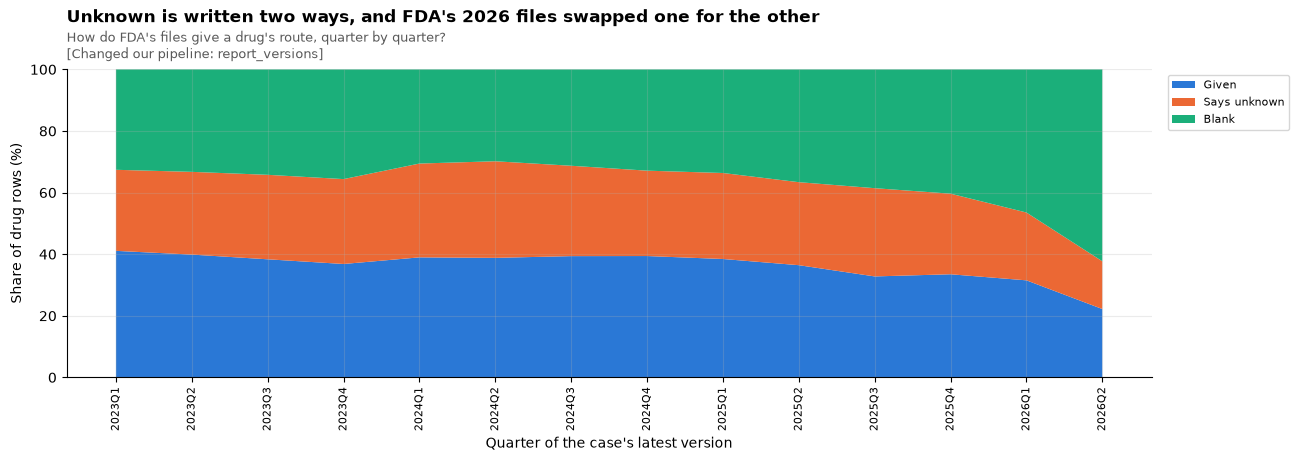

A missing route reaches FAERS as a blank or as UNKNOWN, by the sender's habit, and in 2026Q2 FDA's files wrote UNKNOWN on 16% of drug rows against 26% in 2025Q4, while blank rose from 40% to 62%. Counted apart, the two draw trends that are not real, so we read both, and every other way of saying unknown, as one state: Not given.


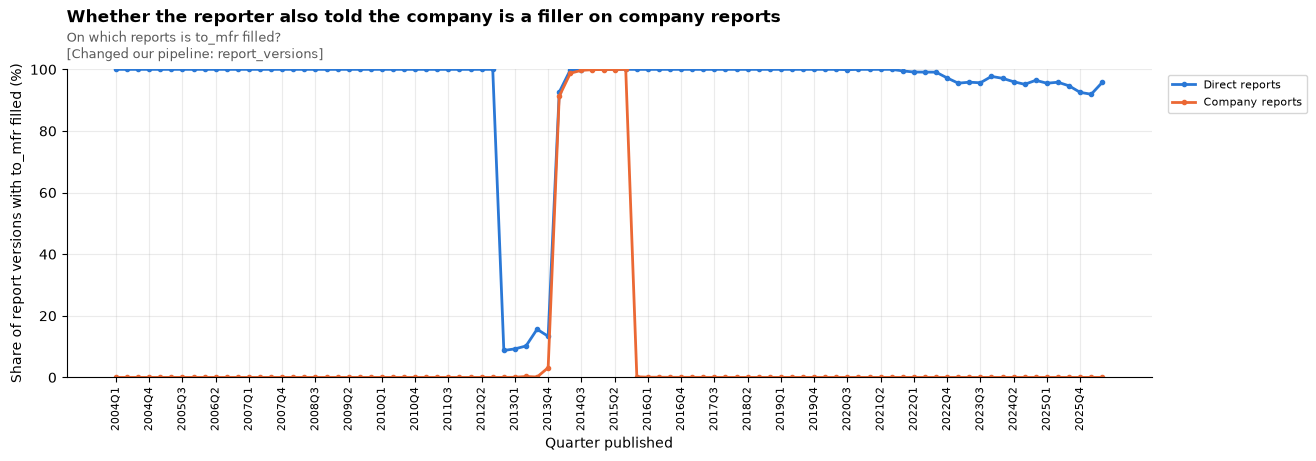

to_mfr asks whether a person who reported straight to FDA also told the company, so it means something only on direct reports, where FDA's files fill it on 96% of report versions. Company reports are blank in almost every quarter, and 1,817,362 of them say N from 2014Q1 to 2015Q3, a filler, so we read to_mfr on a company report as Not given.


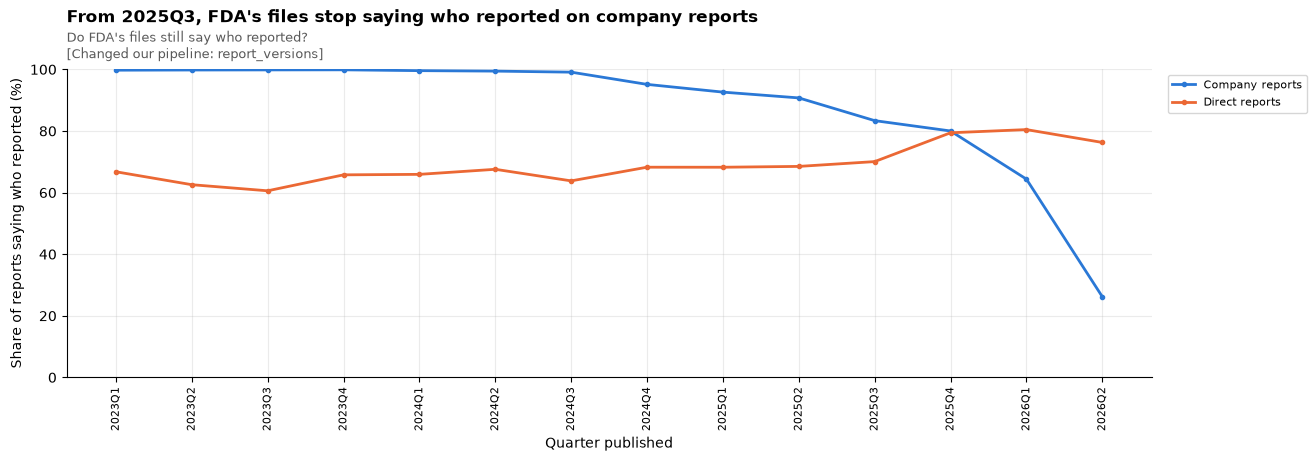

FDA's files said who reported on 91% of company reports in 2025Q2 and on 26% in 2026Q2; consumers fell from 39% to 1% of them. Direct reports, which people send FDA themselves, kept it (76% in 2026Q2), so a count by who reported after mid-2025 shows a change in FDA's files, not in who reports; the explorer says so under the field's chart and filter.


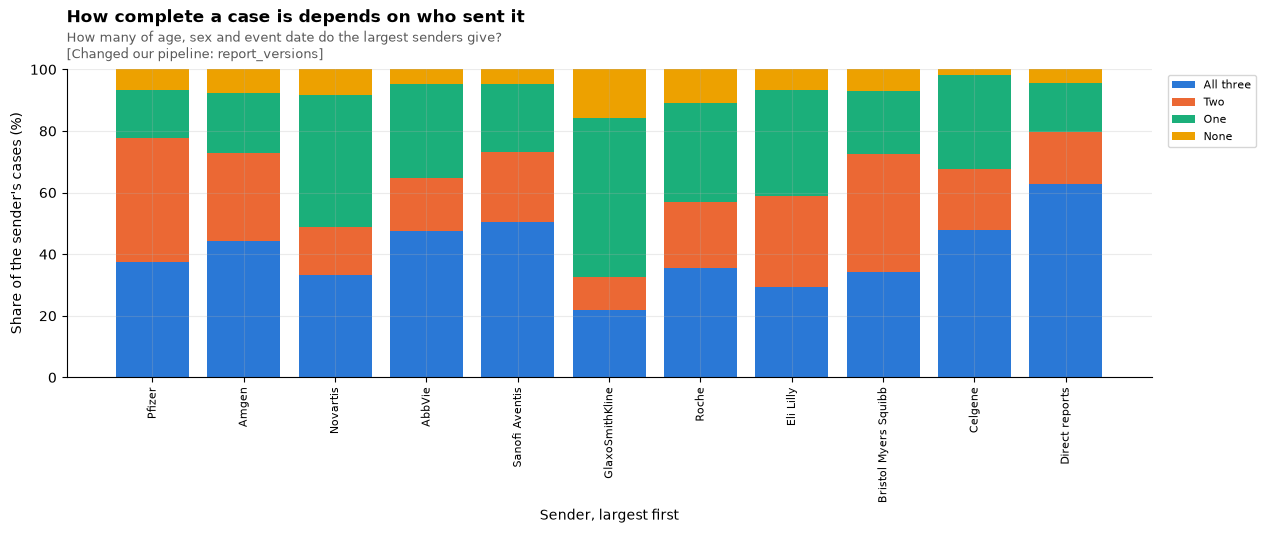

Among the 10 companies that sent the most FAERS cases, the share of cases giving the patient's age and sex and the event date ranges from 22% (GlaxoSmithKline) to 51% (Sanofi Aventis); direct reports give all three in 63%. A product's cases carry the habits of the companies that report it, so every chart in the explorer says how many of its cases give the field, and senders are counted by company, their spellings grouped.
notebooks/out/cards/03_empty_fields.json


In [24]:
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import plot_card, write_cards

cards = compute_cards(
    con,
    [
        "unknown_written_two_ways",
        "to_mfr_filler_on_company_reports",
        "who_reported_lost_on_company_reports",
        "completeness_depends_on_sender",
    ],
)
for card in cards:
    plot_card(card)
print(write_cards(cards, "03_empty_fields"))